Text Summarization || LSTM Encoder-Decoder📚🔄

Fine Tuning Seq2Seq model

In [ ]:
#install Kaggle
!pip install -q kaggle

In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"kulalranjani21","key":"7de078f5ca307cde59098ce48f1a19ae"}'}

In [ ]:
#create a kaggle folder
! mkdir ~/.kaggle

In [ ]:
#copy the kaggle.json to folder created
! cp kaggle.json ~/.kaggle/

In [ ]:
#Permission for the json to act
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
# to list all datasets in kaggle
!kaggle datasets list

ref                                                           title                                               size  lastUpdated          downloadCount  voteCount  usabilityRating  
------------------------------------------------------------  -------------------------------------------------  -----  -------------------  -------------  ---------  ---------------  
anandshaw2001/netflix-movies-and-tv-shows                     Netflix Movies and TV Shows                          1MB  2025-01-03 10:33:01           8308        221  1.0              
ishajangir/crime-data                                         Crime Data                                          49MB  2025-01-08 05:14:42           1289         27  1.0              
ashaychoudhary/anxiety-attack-factors-symptoms-and-severity   Anxiety Attack : Factors, Symptoms, and Severity   244KB  2025-01-19 11:56:21           1314         32  1.0              
oktayrdeki/traffic-accidents                                  Traffic Accid

In [ ]:
!kaggle kernels output harshsingh2209/text-summarization-fine-tuning-seq2seq-model -p /path/to/dest

Output file downloaded to /path/to/dest/t5-small-transcript-summarizer/checkpoint-2500/config.json
Output file downloaded to /path/to/dest/t5-small-transcript-summarizer/checkpoint-2500/generation_config.json
Output file downloaded to /path/to/dest/t5-small-transcript-summarizer/checkpoint-2500/model.safetensors
Output file downloaded to /path/to/dest/t5-small-transcript-summarizer/checkpoint-2500/optimizer.pt
Output file downloaded to /path/to/dest/t5-small-transcript-summarizer/checkpoint-2500/rng_state.pth
Output file downloaded to /path/to/dest/t5-small-transcript-summarizer/checkpoint-2500/scheduler.pt
Output file downloaded to /path/to/dest/t5-small-transcript-summarizer/checkpoint-2500/special_tokens_map.json
Output file downloaded to /path/to/dest/t5-small-transcript-summarizer/checkpoint-2500/spiece.model
Output file downloaded to /path/to/dest/t5-small-transcript-summarizer/checkpoint-2500/tokenizer.json
Output file downloaded to /path/to/dest/t5-small-transcript-summarizer/c

In [ ]:
!pip install contractions

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 289.9/289.9 kB 22.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.3/118.3 kB 11.8 MB/s eta 0:00:00


In [ ]:
pip install pydot

In [ ]:
from textblob import Word
import nltk
nltk.data.path.append("/kaggle/working/")
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [ ]:
# Libraray for Data Manipulation
import numpy as np
import pandas as pd

# Libraray for Data Visualisation
import seaborn as sns
import matplotlib.pyplot as plt
sns.set(style="white",font_scale=1.5)
sns.set(rc={"axes.facecolor":"#FFFAF0","figure.facecolor":"#FFFAF0"})
sns.set_context("poster",font_scale = .7)

# Library for preprocessing
import contractions
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import LabelBinarizer
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
from wordcloud import WordCloud,STOPWORDS
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize,sent_tokenize
import spacy
import math
from gensim.models import Word2Vec
from sklearn.feature_extraction.text import TfidfVectorizer
from joblib import Parallel, delayed
import re,string,unicodedata
from sklearn.model_selection import train_test_split
from textblob import TextBlob
from scipy.sparse import lil_matrix
from tensorflow.keras.preprocessing.sequence import pad_sequences
from nltk import pos_tag

# Library for model building
from tensorflow.keras.regularizers import l2
import tensorflow
import keras
from keras import layers
from tensorflow.keras.preprocessing.text import Tokenizer
from keras.models import Sequential,Model
#from attention import BahdanauAttention
from keras.layers import SimpleRNN,LSTM,GRU, Embedding, Dense, SpatialDropout1D, Dropout, BatchNormalization, Bidirectional, Attention, Input, Concatenate
from sklearn.metrics import accuracy_score
from tensorflow.keras.initializers import GlorotUniform
from tensorflow.keras.optimizers import Adam

#Library to overcome Warnings
import warnings
warnings.filterwarnings('ignore')

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

In [ ]:
import transformers

print(transformers.__version__)

4.47.1


In [ ]:
!pip install evaluate datasets rouge_score -q

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.0/84.0 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 480.6/480.6 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.3/179.3 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.5/143.5 kB 10.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.8/194.8 kB 10.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2024.10.0 requires fsspec==2024.10.0, but you have fsspec 2024.9.0 which is incompatible.


In [ ]:
import wandb
from Kaggle_secrets import UserSecretsClient
"user_secrets" = "UserSecretsClient()"
my_secret = user_secrets.get_secret("wandb_api_key")
wandb.login(key=my_secret)
secret_value = UserSecretsClient().get_secret(secret_label)

SyntaxError: cannot assign to literal here. Maybe you meant '==' instead of '='? (<ipython-input-10-3f83240c241e>, line 3)

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
import re
import nltk
from nltk.corpus import stopwords
import random
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from datasets import Dataset, DatasetDict
from evaluate import load
from transformers import pipeline
from transformers import AutoTokenizer
from transformers import AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq, Seq2SeqTrainingArguments, Seq2SeqTrainer

In [ ]:
sns.set_style('darkgrid')
plt.rcParams['figure.figsize'] = (17,7)
plt.rcParams['font.size'] = 14

Load and Inspect Dataset

In [ ]:
train_df = pd.read_csv('/content/drive/MyDrive/Major Project/samsum-train.csv/samsum-train.csv')
test_df = pd.read_csv('/content/drive/MyDrive/Major Project/samsum-test.csv')

In [ ]:
import pandas as pd # Import the pandas library and assign it to the alias 'pd'

train_df = pd.read_csv("/content/drive/MyDrive/Major Project/samsum-train.csv/samsum-train.csv")
test_df = pd.read_csv("/content/drive/MyDrive/Major Project/samsum-test.csv")
val_df = pd.read_csv("/content/drive/MyDrive/Major Project/samsum-validation.csv")

In [ ]:
train_df.info();

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14732 entries, 0 to 14731
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        14732 non-null  object
 1   dialogue  14731 non-null  object
 2   summary   14732 non-null  object
dtypes: object(3)
memory usage: 345.4+ KB


In [ ]:
train_df.head()

,id,dialogue,summary
0,13818513,Amanda: I baked cookies. Do you want some?\r\...,Amanda baked cookies and will bring Jerry some...
1,13728867,Olivia: Who are you voting for in this electio...,Olivia and Olivier are voting for liberals in ...
2,13681000,"Tim: Hi, what's up?\r\nKim: Bad mood tbh, I wa...",Kim may try the pomodoro technique recommended...
3,13730747,"Edward: Rachel, I think I'm in ove with Bella....",Edward thinks he is in love with Bella. Rachel...
4,13728094,Sam: hey overheard rick say something\r\nSam:...,"Sam is confused, because he overheard Rick com..."


In [ ]:
print(f"Samples in Training Set: {train_df.shape[0]}")
print(f"Samples in Validation Set: {val_df.shape[0]}")
print(f"Samples in Testing Set: {test_df.shape[0]}")

Samples in Training Set: 14732
Samples in Validation Set: 818
Samples in Testing Set: 819


In [ ]:
train_df.sample(5)

,id,dialogue,summary
7254,13715791,Alex: So apparently there's election coming so...,There will be an election soon and there are t...
5524,13680289,Bill: Hi. Seems like there are some problems a...,There are problems at Bill's building site. It...
178,13862208,"Katarina: Hello, I got your contact details fr...",Katarina wants to rent a flat from Liz. She wi...
13833,13728838,Tristan: i lost my wallet!!!\r\nTristan: i'm f...,Tristan left his wallet at Laura's place. Laur...
703,13730087,Betty: <file_other>\r\nBetty: Maybe you should...,Betty warned Steven about some cancer-causing ...


In [ ]:
test_df.sample(5)

,id,dialogue,summary
504,13829179,Martha: how do you feel about minimalism?\r\nJ...,Martha saw a documentary about minimalism.
666,13730473,Kevin: Hey. Your mum has been calling me all d...,Lilian has already told them she is at Helen's...
77,13730529,Mary: Did you tell your sister I am doing onli...,Mark told his sister that Mary is doing an onl...
146,13680992,"Mr. Williams: Ms. Blair, would you like to go ...",Mr. Williams invites Ms. Blair for a coffee. T...
443,13817847,Lucy: Have you thrown the garbage out?\r\nLevy...,Levy hasn't taken the trash out because parent...


Data Exploration

In [ ]:
print("train_df shape: ",train_df.shape)
print("test_df shape: ",test_df.shape)

train_df shape:  (14732, 3)
test_df shape:  (819, 3)


Statistical Summary of Dataset

In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14732 entries, 0 to 14731
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        14732 non-null  object
 1   dialogue  14731 non-null  object
 2   summary   14732 non-null  object
dtypes: object(3)
memory usage: 345.4+ KB


In [ ]:
print("Duplicates in Dataset: ",train_df.duplicated().sum())

Duplicates in Dataset:  0


Check missing values

In [ ]:
train_df.isna().sum()

,0
id,0
dialogue,1
summary,0


In [ ]:
test_df.isna().sum()

,0
id,0
dialogue,0
summary,0


In [ ]:
val_df.isna().sum()

,0
id,0
dialogue,0
summary,0


In [ ]:
train_df.dropna(axis=0, inplace=True)

In [ ]:
any(train_df.isna().sum())

False

Computing Total No. of Missing Values and the Percentage of Missing Values

In [ ]:
missing_data = train_df.isnull().sum().to_frame().rename(columns={0:"Total No. of Missing Values"})
missing_data["% of Missing Values"] = round((missing_data["Total No. of Missing Values"]/len(train_df))*100,2)
missing_data

,Total No. of Missing Values,% of Missing Values
id,0,0.00
dialogue,1,0.01
summary,0,0.00


Performing Descriptive Analysis

In [ ]:
round(train_df.describe().T,2)

,count,unique,top,freq
id,14732,14732,13729017,1
dialogue,14731,14264,"Jimmy: Hey, guess what? My car's completely ka...",4
summary,14732,14730,Seth's pet Oreo that he got when he was 10 is ...,2


Exploratory Data Analysis

In [ ]:
eda_df = train_df.drop(['id'], axis=1)

In [ ]:
eda_df['dialogue_length'] = eda_df['dialogue'].str.len()
eda_df['summary_length'] = eda_df['summary'].str.len()

In [ ]:
eda_df['dialogue_word_count'] = eda_df['dialogue'].apply(lambda x: len(x.split()))
eda_df['summary_word_count'] = eda_df['summary'].apply(lambda x: len(x.split()))

In [ ]:
eda_df.head()

,dialogue,summary,dialogue_length,summary_length,dialogue_word_count,summary_word_count
0,Amanda: I baked cookies. Do you want some?\r\...,Amanda baked cookies and will bring Jerry some...,94,56,16,9
1,Olivia: Who are you voting for in this electio...,Olivia and Olivier are voting for liberals in ...,111,61,18,10
2,"Tim: Hi, what's up?\r\nKim: Bad mood tbh, I wa...",Kim may try the pomodoro technique recommended...,528,77,98,14
3,"Edward: Rachel, I think I'm in ove with Bella....",Edward thinks he is in love with Bella. Rachel...,155,97,26,18
4,Sam: hey overheard rick say something\r\nSam:...,"Sam is confused, because he overheard Rick com...",909,145,179,27


In [ ]:
def visualize(data, col):

    print()
    plt.subplot(1,2,1)
    sns.boxplot(y=data[col])
    plt.ylabel(col, labelpad=12.5)

    plt.subplot(1,2,2)
    sns.kdeplot(data[col], fill=True)
    plt.xlabel('')
    plt.ylabel('')

    plt.show()

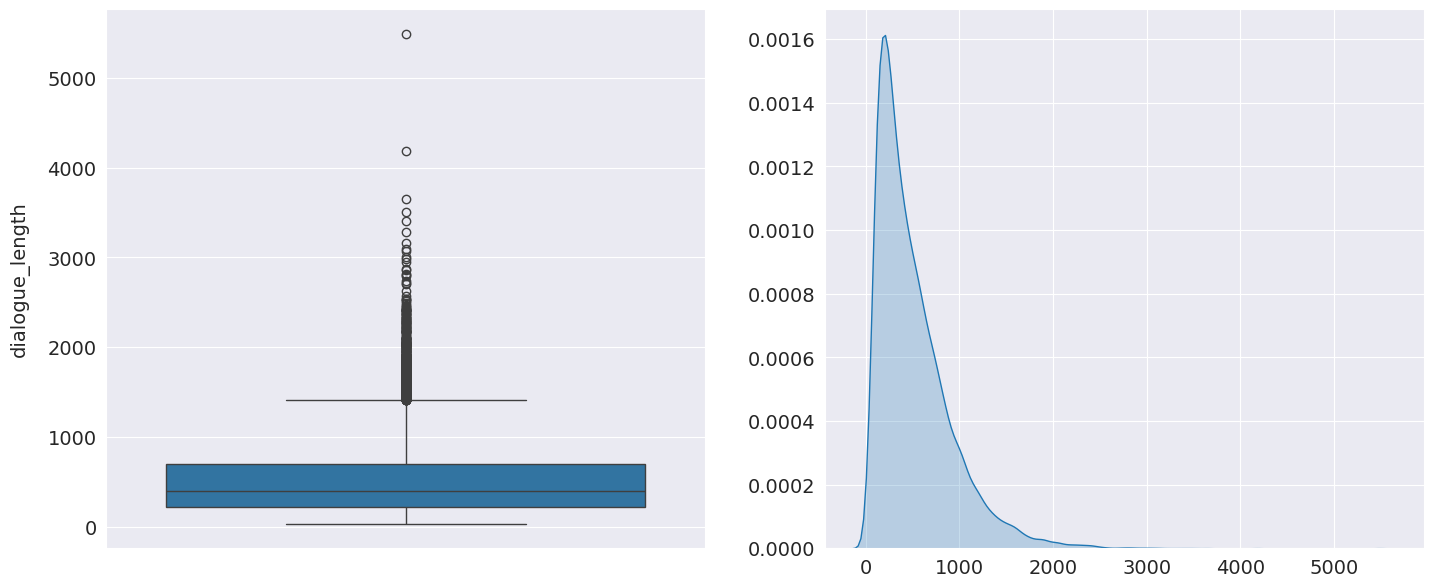

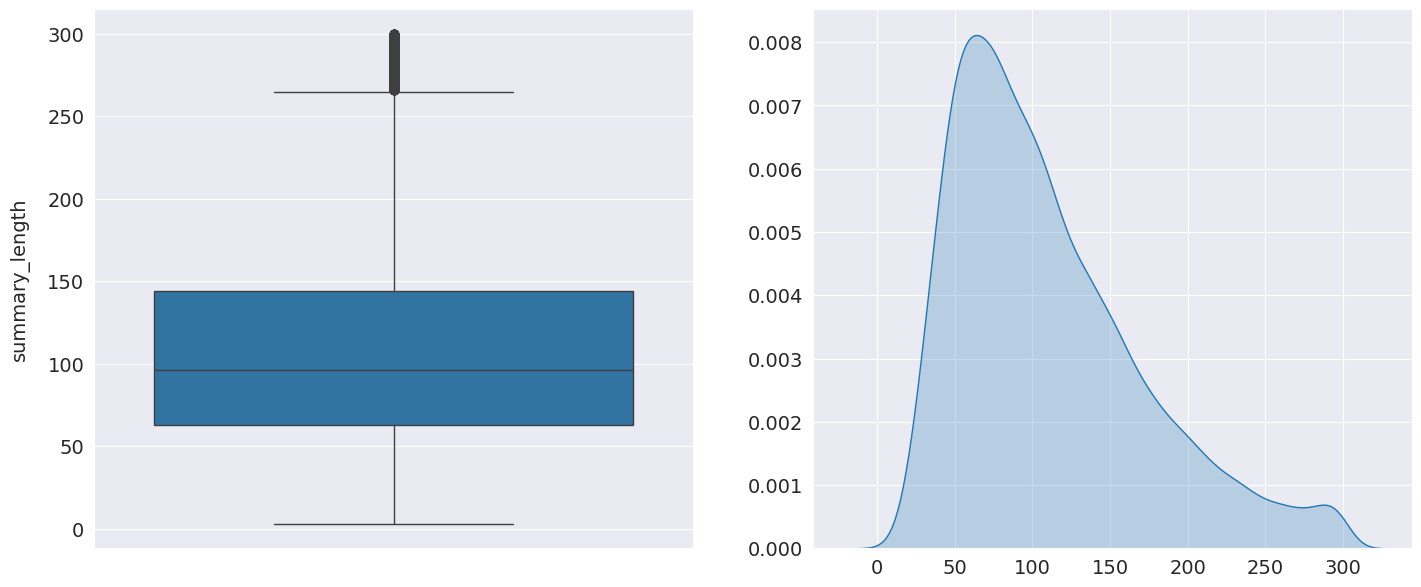

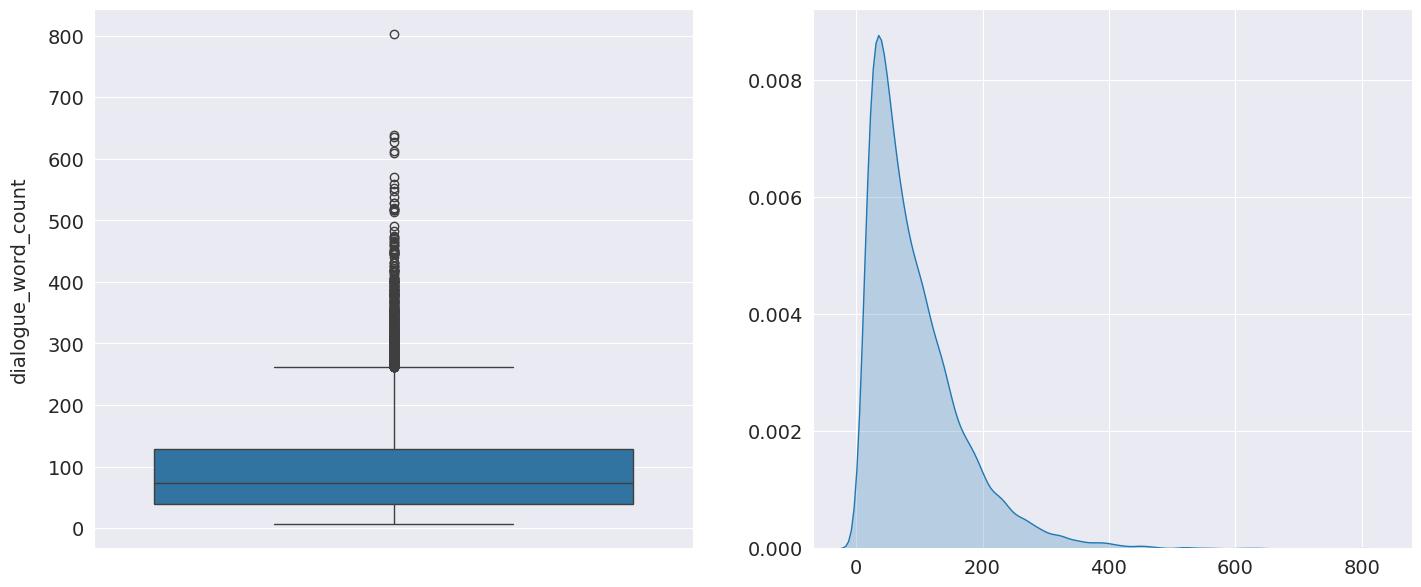

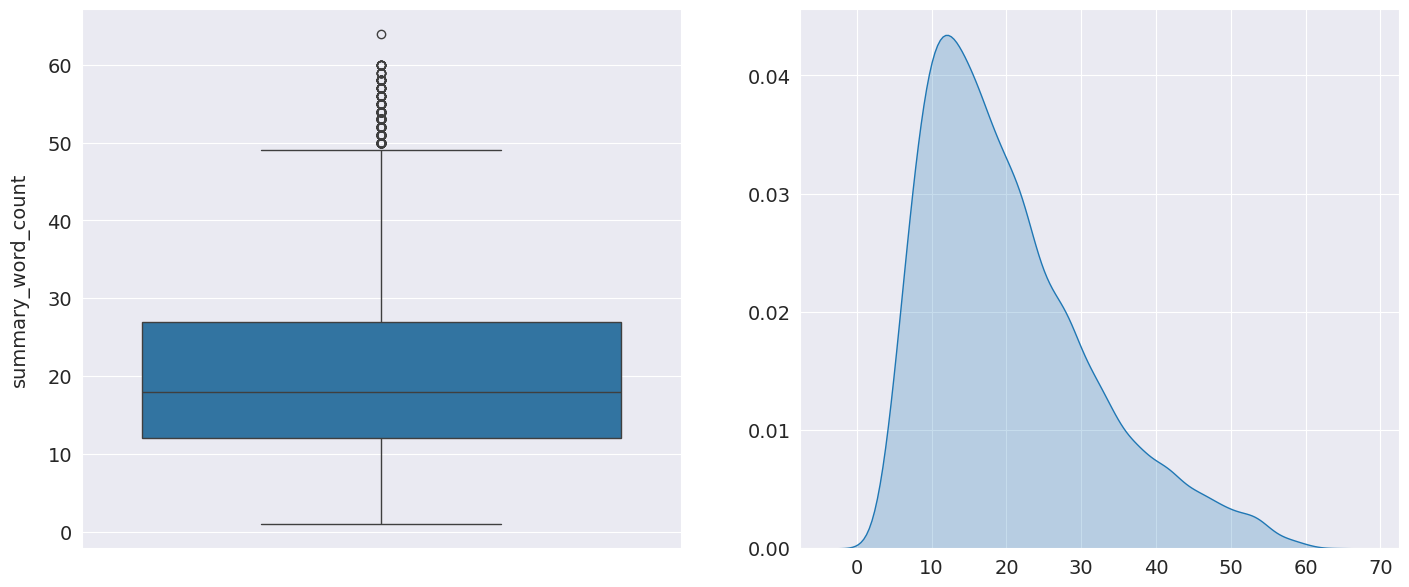

In [ ]:
cols = eda_df.columns[2:]
for col in cols:
    visualize(eda_df, col)

Prepare Dataset and Model

In [ ]:
model_checkpoint = "t5-small"

In [ ]:
def cleanse(text):
    clean = re.compile('<.*?>')
    clean = re.sub(clean, '', text)

    clean = '\n'.join([line for line in clean.split('\n') if not re.match('.*:\s*$', line)])

    return clean

In [ ]:
train_df['dialogue'] = train_df['dialogue'].apply(cleanse)
val_df['dialogue'] = val_df['dialogue'].apply(cleanse)
test_df['dialogue'] = test_df['dialogue'].apply(cleanse)

In [ ]:
train_df['summary'] = train_df['summary'].apply(cleanse)
val_df['summary'] = val_df['summary'].apply(cleanse)
test_df['summary'] = test_df['summary'].apply(cleanse)


HuggingFace Dataset & DatasetDict

In [ ]:
train_dataset = Dataset.from_pandas(train_df, preserve_index=False)
test_dataset = Dataset.from_pandas(test_df)
val_dataset = Dataset.from_pandas(val_df)

In [ ]:
!pip install datasets

In [ ]:
dataset_dict = {
    "train": train_dataset,
    "test": test_dataset,
    "validation": val_dataset
}

data = DatasetDict(dataset_dict)

In [ ]:
data

DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 14731
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 819
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 818
    })
})

Visualizing Random Samples

In [ ]:
for _ in range(5):
    idx = random.randint(0, 14730)
    sample = data["train"][idx]

    print("")
    print("="*100)
    print(sample["dialogue"])
    print("-"*100)
    print(sample["summary"])
    print("")


Joseph: How about we have lunch together? 
Maria P: Sure! I'll be free at 1 p.m.
Maria B: Ok
Joseph: 1 is fine for me 
Joseph: Al Haesh?
Maria B: Ok
Maria P: Sounds good to me! 
----------------------------------------------------------------------------------------------------
Joseph, Maria P, and Maria B will have lunch together at 1pm at Al Haesh.


Tim: wanna have a break?
Laura: gimme 10 min, ok?
Laura: need to finish sth...
Tim: but u wanna go for lunch or just coffee?
Laura: it's too early for lunch..
Laura: if you wanna have lunch let's meet at 2:20 downstairs
Tim: ok!
----------------------------------------------------------------------------------------------------
Laura and Tim will meet for a lunch at 2:20 downstairs.


Meghan: Baby, I miss you
Simon: I miss you too pumpkin
Meghan: When are you coming back?
Simon: Monday the latest, I have my last meeting in the morning and then I'm catching the afternoon flight
Meghan: Pick you up from the airport?
Simon: baby you're too

Text Preprocessing

In [ ]:
from transformers import AutoTokenizer # Import AutoTokenizer explicitly

tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

Let's test it

In [ ]:
tokenizer("Hi there! I am Andrew Garfield")

{'input_ids': [2018, 132, 55, 27, 183, 5954, 3121, 1846, 1], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1]}

NOTE: T5 model and its variants are also capable of Translation, hence we need to provide a prefix to specify the task

In [ ]:
prefix = "summarize: "

In [ ]:
max_dialogue_length = 1024
max_summary_length = 128

In [ ]:
def preprocess_function(samples):
    inputs = [prefix + doc for doc in samples["dialogue"]]
    model_inputs = tokenizer(inputs, max_length=max_dialogue_length, truncation=True)

    labels = tokenizer(text_target=samples["summary"], max_length=max_summary_length, truncation=True)
    model_inputs["labels"] = labels["input_ids"]

    return model_inputs

In [ ]:
preprocess_function(data["train"][0])

{'input_ids': [[21603, 10, 71, 1], [21603, 10, 3, 51, 1], [21603, 10, 3, 9, 1], [21603, 10, 3, 29, 1], [21603, 10, 3, 26, 1], [21603, 10, 3, 9, 1], [21603, 10, 3, 10, 1], [21603, 10, 1], [21603, 10, 27, 1], [21603, 10, 1], [21603, 10, 3, 115, 1], [21603, 10, 3, 9, 1], [21603, 10, 3, 157, 1], [21603, 10, 3, 15, 1], [21603, 10, 3, 26, 1], [21603, 10, 1], [21603, 10, 1], [21603, 10, 3, 75, 1], [21603, 10, 3, 32, 1], [21603, 10, 3, 32, 1], [21603, 10, 3, 157, 1], [21603, 10, 3, 23, 1], [21603, 10, 3, 15, 1], [21603, 10, 3, 7, 1], [21603, 10, 3, 5, 1], [21603, 10, 1], [21603, 10, 309, 1], [21603, 10, 3, 32, 1], [21603, 10, 1], [21603, 10, 3, 63, 1], [21603, 10, 3, 32, 1], [21603, 10, 3, 76, 1], [21603, 10, 1], [21603, 10, 3, 210, 1], [21603, 10, 3, 9, 1], [21603, 10, 3, 29, 1], [21603, 10, 3, 17, 1], [21603, 10, 1], [21603, 10, 3, 7, 1], [21603, 10, 3, 32, 1], [21603, 10, 3, 51, 1], [21603, 10, 3, 15, 1], [21603, 10, 3, 58, 1], [21603, 10, 1], [21603, 10, 1], [21603, 10, 446, 1], [21603, 10

In [ ]:
final_data = data.map(preprocess_function, batched=True,
                     remove_columns=['id', 'dialogue', 'summary'])

Map:   0%|          | 0/14731 [00:00<?, ? examples/s]

Map:   0%|          | 0/819 [00:00<?, ? examples/s]

Map:   0%|          | 0/818 [00:00<?, ? examples/s]

In [ ]:
final_data

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 14731
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 819
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 818
    })
})

Preprocessing

In [ ]:
col = 'id'
train_df.drop(col,axis = 1,inplace = True)
test_df.drop(col,axis = 1,inplace = True)

Dropping Duplicates and Null Values

In [ ]:
train_df.dropna(inplace = True)

Lowercasing

In [ ]:
train_df['dialogue'] = train_df['dialogue'].str.lower()
train_df['summary'] = train_df['summary'].str.lower()
test_df['dialogue'] = test_df['dialogue'].str.lower()
test_df['summary'] = test_df['summary'].str.lower()

Removing Html tags

In [ ]:
import re
def remove_html_tags(text):
    pattern = r'[^a-zA-Z0-9\s]'
    text = re.sub(pattern,'',text)
    return text

In [ ]:
train_df['dialogue'] = train_df['dialogue'].apply(remove_html_tags)
train_df['summary'] = train_df['summary'].apply(remove_html_tags)
test_df['dialogue'] = test_df['dialogue'].apply(remove_html_tags)
test_df['summary'] = test_df['summary'].apply(remove_html_tags)

Removing URLs

In [ ]:
def remove_url(text):
    pattern = re.compile(r'https?://\S+|www\.\S+')
    return pattern.sub(r'',text)

train_df['dialogue'] = train_df['dialogue'].apply(remove_url)
train_df['summary'] = train_df['summary'].apply(remove_url)
test_df['dialogue'] = test_df['dialogue'].apply(remove_url)
test_df['summary'] = test_df['summary'].apply(remove_url)

Chat word treatment

In [ ]:
chat_words = {
    "AFAIK": "As Far As I Know",
    "AFK": "Away From Keyboard",
    "ASAP": "As Soon As Possible",
    "ATK": "At The Keyboard",
    "ATM": "At The Moment",
    "A3": "Anytime, Anywhere, Anyplace",
    "BAK": "Back At Keyboard",
    "BBL": "Be Back Later",
    "BBS": "Be Back Soon",
    "BFN": "Bye For Now",
    "B4N": "Bye For Now",
    "BRB": "Be Right Back",
    "BRT": "Be Right There",
    "BTW": "By The Way",
    "B4": "Before",
    "CU": "See You",
    "CUL8R": "See You Later",
    "CYA": "See You",
    "FAQ": "Frequently Asked Questions",
    "FC": "Fingers Crossed",
    "FWIW": "For What It's Worth",
    "FYI": "For Your Information",
    "GAL": "Get A Life",
    "GG": "Good Game",
    "GN": "Good Night",
    "GMTA": "Great Minds Think Alike",
    "GR8": "Great!",
    "G9": "Genius",
    "IC": "I See",
    "ICQ": "I Seek you (also a chat program)",
    "ILU": "I Love You",
    "IMHO": "In My Honest/Humble Opinion",
    "IMO": "In My Opinion",
    "IOW": "In Other Words",
    "IRL": "In Real Life",
    "KISS": "Keep It Simple, Stupid",
    "LDR": "Long Distance Relationship",
    "LMAO": "Laugh My A.. Off",
    "LOL": "Laughing Out Loud",
    "LTNS": "Long Time No See",
    "L8R": "Later",
    "MTE": "My Thoughts Exactly",
    "M8": "Mate",
    "NRN": "No Reply Necessary",
    "OIC": "Oh I See",
    "PITA": "Pain In The A..",
    "PRT": "Party",
    "PRW": "Parents Are Watching",
    "QPSA": "Que Pasa?",
    "ROFL": "Rolling On The Floor Laughing",
    "ROFLOL": "Rolling On The Floor Laughing Out Loud",
    "ROTFLMAO": "Rolling On The Floor Laughing My A.. Off",
    "SK8": "Skate",
    "STATS": "Your sex and age",
    "ASL": "Age, Sex, Location",
    "THX": "Thank You",
    "TTFN": "Ta-Ta For Now!",
    "TTYL": "Talk To You Later",
    "U": "You",
    "U2": "You Too",
    "U4E": "Yours For Ever",
    "WB": "Welcome Back",
    "WTF": "What The F...",
    "WTG": "Way To Go!",
    "WUF": "Where Are You From?",
    "W8": "Wait...",
    "7K": "Sick:-D Laughter",
    "TFW": "That feeling when",
    "MFW": "My face when",
    "MRW": "My reaction when",
    "IFYP": "I feel your pain",
    "LOL": "Laughing out loud",
    "TNTL": "Trying not to laugh",
    "JK": "Just kidding",
    "IDC": "I don’t care",
    "ILY": "I love you",
    "IMU": "I miss you",
    "ADIH": "Another day in hell",
    "IDC": "I don’t care",
    "ZZZ": "Sleeping, bored, tired",
    "WYWH": "Wish you were here",
    "TIME": "Tears in my eyes",
    "BAE": "Before anyone else",
    "FIMH": "Forever in my heart",
    "BSAAW": "Big smile and a wink",
    "BWL": "Bursting with laughter",
    "LMAO": "Laughing my a** off",
    "BFF": "Best friends forever",
    "CSL": "Can’t stop laughing",
}

In [ ]:
def chat_conversion(text):
    new_text=[]
    for w in text.split():
        if w.upper() in chat_words:
            new_text.append(chat_words[w.upper()])
        else:
            new_text.append(w)
    return " ".join(new_text)

In [ ]:
train_df['dialogue'] = train_df['dialogue'].apply(chat_conversion)
train_df['summary'] = train_df['summary'].apply(chat_conversion)
test_df['dialogue'] = test_df['dialogue'].apply(chat_conversion)
test_df['summary'] = test_df['summary'].apply(chat_conversion)

Removing Emojis

In [ ]:
def remove_emoji(text):
    emoji_pattern = re.compile("["
                           u"\U0001F600-\U0001F64F"  # emoticons
                           u"\U0001F300-\U0001F5FF"  # symbols & pictographs
                           u"\U0001F680-\U0001F6FF"  # transport & map symbols
                           u"\U0001F1E0-\U0001F1FF"  # flags (iOS)
                           u"\U00002702-\U000027B0"
                           u"\U000024C2-\U0001F251"
                           "]+", flags=re.UNICODE)
    return emoji_pattern.sub(r'', text)

In [ ]:
train_df['dialogue'] = train_df['dialogue'].apply(remove_emoji)
train_df['summary'] = train_df['summary'].apply(remove_emoji)
test_df['dialogue'] = test_df['dialogue'].apply(remove_emoji)
test_df['summary'] = test_df['summary'].apply(remove_emoji)

Removing contraction

In [ ]:
def expand_contractions(text):
    expanded_text = contractions.fix(text)
    return expanded_text

train_df['dialogue'] = train_df['dialogue'].apply(expand_contractions)
train_df['summary'] = train_df['summary'].apply(expand_contractions)
test_df['dialogue'] = test_df['dialogue'].apply(expand_contractions)
test_df['summary'] = test_df['summary'].apply(expand_contractions)

In [ ]:
train_df['summary'] = ['<start> ' + sentence + ' <end>' for sentence in train_df['summary']]
test_df['summary'] = ['<start> ' + sentence + ' <end>' for sentence in test_df['summary']]

Tokenize on the Data

In [ ]:
tok = Tokenizer()
tok.fit_on_texts(train_df['dialogue']+train_df['summary'])

In [ ]:
len(tok.word_index)

33259

In [ ]:
tok.document_count

14731

Converting data in numerical forms

In [ ]:
# Convert training dialogues and summaries to sequences
train_df['dialogue'] = tok.texts_to_sequences(train_df['dialogue'])
train_df['summary'] = tok.texts_to_sequences(train_df['summary'])

# Convert test dialogues and summaries to sequences (without fitting)
test_df['dialogue'] = tok.texts_to_sequences(test_df['dialogue'])
test_df['summary'] = tok.texts_to_sequences(test_df['summary'])

In [ ]:
train_df

,dialogue,summary
0,"[423, 1, 3359, 1528, 15, 2, 71, 52, 584, 70, 4...","[16, 423, 3359, 1528, 6, 12, 211, 584, 52, 98,..."
1,"[318, 144, 18, 2, 5396, 11, 10, 39, 2944, 604,...","[16, 318, 6, 1588, 18, 5396, 11, 11934, 10, 39..."
2,"[225, 116, 26, 7, 60, 356, 217, 1440, 3, 24, 8...","[16, 356, 235, 174, 4, 16211, 13671, 1959, 118..."
3,"[1001, 410, 1, 61, 1, 21, 10, 21537, 29, 831, ...","[16, 1001, 556, 38, 7, 10, 132, 29, 831, 410, ..."
4,"[192, 113, 9658, 491, 167, 109, 192, 1, 15, 8,...","[16, 192, 7, 2350, 110, 38, 9658, 491, 2300, 3..."
...,...,...
14727,"[4686, 2, 18, 25, 20, 141, 2, 235, 32, 845, 13...","[16, 4686, 7, 512, 3, 64, 1386, 3, 1281, 76, 3..."
14728,"[1076, 137, 1076, 137, 1076, 113, 882, 50, 18,...","[16, 1076, 7, 27, 96, 33, 765, 323, 341, 6, 32..."
14729,"[112, 432, 146, 52, 217, 527, 2850, 12, 5972, ...","[16, 2850, 7, 46, 3, 5972, 8896, 177, 1983, 6,..."
14730,"[597, 631, 2969, 50, 18, 2, 214, 597, 4, 656, ...","[16, 2969, 101, 8, 129, 9, 3, 4, 656, 29, 4, 3..."


In [ ]:
def calculate_max_sequence_length(train_summary,train_dialogue,test_summary,test_dialogue):
    max_length_1 = max(max(len(seq) for seq in train_dialogue), max(len(seq) for seq in train_summary))
    max_length_2 = max(max(len(seq) for seq in test_dialogue), max(len(seq) for seq in test_summary))
    max_length_combined = max(max_length_1,max_length_2)
    return max_length_combined

max_length_combined = calculate_max_sequence_length(train_df['dialogue'],train_df['summary'],test_df['dialogue'],test_df['summary'])
max_length_combined

819

In [ ]:
for num in train_df['dialogue'][0]:
    print(num, end=' ')

423 1 3359 1528 15 2 71 52 584 70 423 54 211 2 98 

In [ ]:
# Print corresponding words horizontally
for num in train_df['dialogue'][0]:
    word = tok.index_word.get(num, 'UNK')
    print(word, end=' ')

amanda i baked cookies do you want some jerry sure amanda ill bring you tomorrow 

In [ ]:
for num in train_df['summary'][0]:
    word = tok.index_word.get(num)
    print(word,end = " ")

start amanda baked cookies and will bring jerry some tomorrow end 

separating the data in dependent and independent and padding it

In [ ]:
x_train = pad_sequences(train_df['dialogue'],maxlen = max_length_combined,padding = 'post')
y_train = pad_sequences(train_df['summary'],maxlen = max_length_combined,padding = 'post')
x_test = pad_sequences(test_df['dialogue'],maxlen = max_length_combined,padding = 'post')
y_test = pad_sequences(test_df['summary'],maxlen = max_length_combined,padding = 'post')

In [ ]:
x_train

array([[ 423,    1, 3359, ...,    0,    0,    0],
       [ 318,  144,   18, ...,    0,    0,    0],
       [ 225,  116,   26, ...,    0,    0,    0],
       ...,
       [ 112,  432,  146, ...,    0,    0,    0],
       [ 597,  631, 2969, ...,    0,    0,    0],
       [1586,   18,    2, ...,    0,    0,    0]], dtype=int32)

In [ ]:
y_train

array([[  16,  423, 3359, ...,    0,    0,    0],
       [  16,  318,    6, ...,    0,    0,    0],
       [  16,  356,  235, ...,    0,    0,    0],
       ...,
       [  16, 2850,    7, ...,    0,    0,    0],
       [  16, 2969,  101, ...,    0,    0,    0],
       [  16, 1586,    6, ...,    0,    0,    0]], dtype=int32)

In [ ]:
# Check the shape of the resulting arrays
print("Shape of x_train:", x_train.shape)
print("Shape of x_test:", x_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of x_train: (14731, 819)
Shape of x_test: (819, 819)
Shape of y_train: (14731, 819)
Shape of y_test: (819, 819)


Model Architecture

In [ ]:
model = AutoModelForSeq2SeqLM.from_pretrained(model_checkpoint)

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/242M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

In [ ]:
print(model)

T5ForConditionalGeneration(
  (shared): Embedding(32128, 512)
  (encoder): T5Stack(
    (embed_tokens): Embedding(32128, 512)
    (block): ModuleList(
      (0): T5Block(
        (layer): ModuleList(
          (0): T5LayerSelfAttention(
            (SelfAttention): T5Attention(
              (q): Linear(in_features=512, out_features=512, bias=False)
              (k): Linear(in_features=512, out_features=512, bias=False)
              (v): Linear(in_features=512, out_features=512, bias=False)
              (o): Linear(in_features=512, out_features=512, bias=False)
              (relative_attention_bias): Embedding(32, 8)
            )
            (layer_norm): T5LayerNorm()
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (1): T5LayerFF(
            (DenseReluDense): T5DenseActDense(
              (wi): Linear(in_features=512, out_features=2048, bias=False)
              (wo): Linear(in_features=2048, out_features=512, bias=False)
              (dropout): Drop

Model Training

In [ ]:
batch_size = 16
epochs = 4
model_name = f"{model_checkpoint}-transcript-summarizer"
args = Seq2SeqTrainingArguments(
    model_name,                                                        # Specify Model name
    evaluation_strategy="epoch",                                       # Evaluate performance at Epoch end
    learning_rate=2e-5,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    weight_decay=0.01,
    save_total_limit=3,                                                # Save the model only 3 times
    num_train_epochs=epochs,                                           # Number of Epochs
    predict_with_generate=True,                                        # To predict Sequences
    fp16=True,                                                         # Set to fp16, mixed precision training
    push_to_hub=False                                                  # Push model to huggingface
)


In [ ]:
from transformers import AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq, Seq2SeqTrainingArguments, Seq2SeqTrainer # Import Seq2SeqTrainingArguments

In [ ]:
data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

In [ ]:
# Make sure 'tokenizer' is defined before using it
from transformers import AutoTokenizer

model_checkpoint = "t5-small"  # or any other checkpoint you are using
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

# Now you can use 'tokenizer'
data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

In [ ]:
metric = load("rouge")
def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    decoded_preds = tokenizer.batch_decode(predictions, skip_special_tokens=True)

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    decoded_preds = ["\n".join(nltk.sent_tokenize(pred.strip())) for pred in decoded_preds]
    decoded_labels = ["\n".join(nltk.sent_tokenize(label.strip())) for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels, use_stemmer=True)
    result = {key : value * 100 for key, value in result.items()}

    prediction_lens = [np.count_nonzero(pred != tokenizer.pad_token_id) for pred in predictions]
    result["gen_len"] = np.mean(prediction_lens)

    return {k: round(v,4) for k,v in result.items()}

In [ ]:
trainer = Seq2SeqTrainer(
    model,
    args,
    train_dataset=final_data["train"],
    eval_dataset=final_data["validation"],
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics
)

In [ ]:
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
import nltk
nltk.download('punkt_tab')  # Download the required data package

trainer = Seq2SeqTrainer(
    model,
    args,
    train_dataset=final_data["train"],
    eval_dataset=final_data["validation"],
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics
)

trainer.train()

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum,Gen Len
1,2.036400,1.824900,40.939900,18.064500,34.093400,37.985700,17.185800
2,1.991000,1.797627,41.081300,18.152400,34.255700,38.048100,17.324000
3,1.968600,1.784702,41.572000,18.643000,34.631300,38.394700,17.297100
4,1.948600,1.781536,41.634900,18.730000,34.762000,38.473600,17.282400


TrainOutput(global_step=3684, training_loss=1.9763241083433005, metrics={'train_runtime': 1072.5965, 'train_samples_per_second': 54.936, 'train_steps_per_second': 3.435, 'total_flos': 6243183017459712.0, 'train_loss': 1.9763241083433005, 'epoch': 4.0})

Testing our Fine Tuned Model

In [ ]:
results = trainer.evaluate(final_data["test"])

In [ ]:
for k,v in results.items():
    print(f"{k:{30}}{round(v,3):{20}}")

eval_loss                                      1.8
eval_rouge1                                 41.102
eval_rouge2                                 17.105
eval_rougeL                                 33.733
eval_rougeLsum                              37.618
eval_gen_len                                17.272
eval_runtime                                27.744
eval_samples_per_second                      29.52
eval_steps_per_second                        1.874
epoch                                          4.0


Pipeline

In [ ]:
summarizer = pipeline('summarization', model=model, tokenizer=tokenizer)

Device set to use cuda:0


In [ ]:
for _ in range(5):
    idx = random.randint(0, 818)

    dialogue = data["test"][idx]["dialogue"]
    summary = data["test"][idx]["summary"]

    predicted = summarizer(dialogue)

    print("="*100)
    print(f"Dialogue:\n{dialogue}")
    print("-"*100)
    print(f"Summary:\n{summary}")
    print("-"*100)
    print(f"Predicted:\n{predicted[0]['summary_text']}")

Your max_length is set to 200, but your input_length is only 127. Since this is a summarization task, where outputs shorter than the input are typically wanted, you might consider decreasing max_length manually, e.g. summarizer('...', max_length=63)


Dialogue:
Richie: Pogba
Clay: Pogboom
Richie: what a s strike yoh!
Clay: was off the seat the moment he chopped the ball back to his right foot
Richie: me too dude
Clay: hope his form lasts
Richie: This season he's more mature
Clay: Yeah, Jose has his trust in him
Richie: everyone does
Clay: yeah, he really deserved to score after his first 60 minutes
Richie: reward
Clay: yeah man
Richie: cool then 
Clay: cool
----------------------------------------------------------------------------------------------------
Summary:
Richie and Clay saw a very good football game, with one football player chopping the ball back to his foot, which was particularly exciting. Jose has trust in that player. 
----------------------------------------------------------------------------------------------------
Predicted:
Pogboom was off the seat when he chopped the ball back to his right foot. Jose has his trust in him and he deserves to score after his first 60 minutes.
Dialogue:
Lincoln: Heeyyy ;* whats up


Modelling

ENCODER-DECODER MODEL WITH ATTENTION

In [ ]:
max_length_input = x_train.shape[1]
max_length_output = y_train.shape[1]
input_vocab_size = len(tok.word_index) + 1
output_vocab_size = len(tok.word_index) + 1

# Define Encoder model
encoder_inputs = Input(shape=(max_length_input,))
encoder_embedding = Embedding(input_dim=input_vocab_size, output_dim=260)(encoder_inputs)
encoder_lstm = LSTM(64, return_sequences=True, return_state=True)  # Ensure return_sequences=True
encoder_lstm = LSTM(64, return_sequences=True, return_state=True)  # Ensure return_sequences=True
encoder_outputs, state_h, state_c = encoder_lstm(encoder_embedding)
encoder_states = [state_h, state_c]

# Define Decoder model
decoder_inputs = Input(shape=(max_length_output,))
decoder_embedding = Embedding(input_dim=output_vocab_size, output_dim=260)(decoder_inputs)
decoder_lstm = LSTM(64, return_sequences=True, return_state=True)
decoder_lstm = LSTM(64, return_sequences=True, return_state=True)
decoder_outputs, _, _ = decoder_lstm(decoder_embedding, initial_state=encoder_states)

# Attention Layer
attention = Attention()([decoder_outputs, encoder_outputs])

# Concatenate attention output with decoder outputs
decoder_concat_input = Concatenate(axis=-1)([decoder_outputs, attention])

# Dense Layer for output prediction
decoder_dense = Dense(output_vocab_size, activation='softmax')
decoder_outputs = decoder_dense(decoder_concat_input)

# Define the full Encoder-Decoder model
model = Model([encoder_inputs, decoder_inputs], decoder_outputs)

# Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Print model summary
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 819)            │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ input_layer_1             │ (None, 819)            │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ embedding (Embedding)     │ (None, 819, 260)       │      8,647,600 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ embedding_1 (Embedding)   │ (None, 819, 260)       │      8,647,600 │ input_layer_1[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ lstm_1 (LSTM)             │ [(None, 819, 64),      │         83,200 │ embedding[0][0]        │
│                           │ (None, 64), (None,     │                │                        │
│                           │ 64)]                   │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ lstm_3 (LSTM)             │ [(None, 819, 64),      │         83,200 │ embedding_1[0][0],     │
│                           │ (None, 64), (None,     │                │ lstm_1[0][1],          │
│                           │ 64)]                   │                │ lstm_1[0][2]           │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ attention (Attention)     │ (None, 819, 64)        │              0 │ lstm_3[0][0],          │
│                           │                        │                │ lstm_1[0][0]           │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ concatenate (Concatenate) │ (None, 819, 128)       │              0 │ lstm_3[0][0],          │
│                           │                        │                │ attention[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense (Dense)             │ (None, 819, 33260)     │      4,290,540 │ concatenate[0][0]      │
└───────────────────────────┴────────────────────────┴────────────────┴────────────────────────┘

 Total params: 21,752,140 (82.98 MB)

 Trainable params: 21,752,140 (82.98 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
Model: "functional_1"

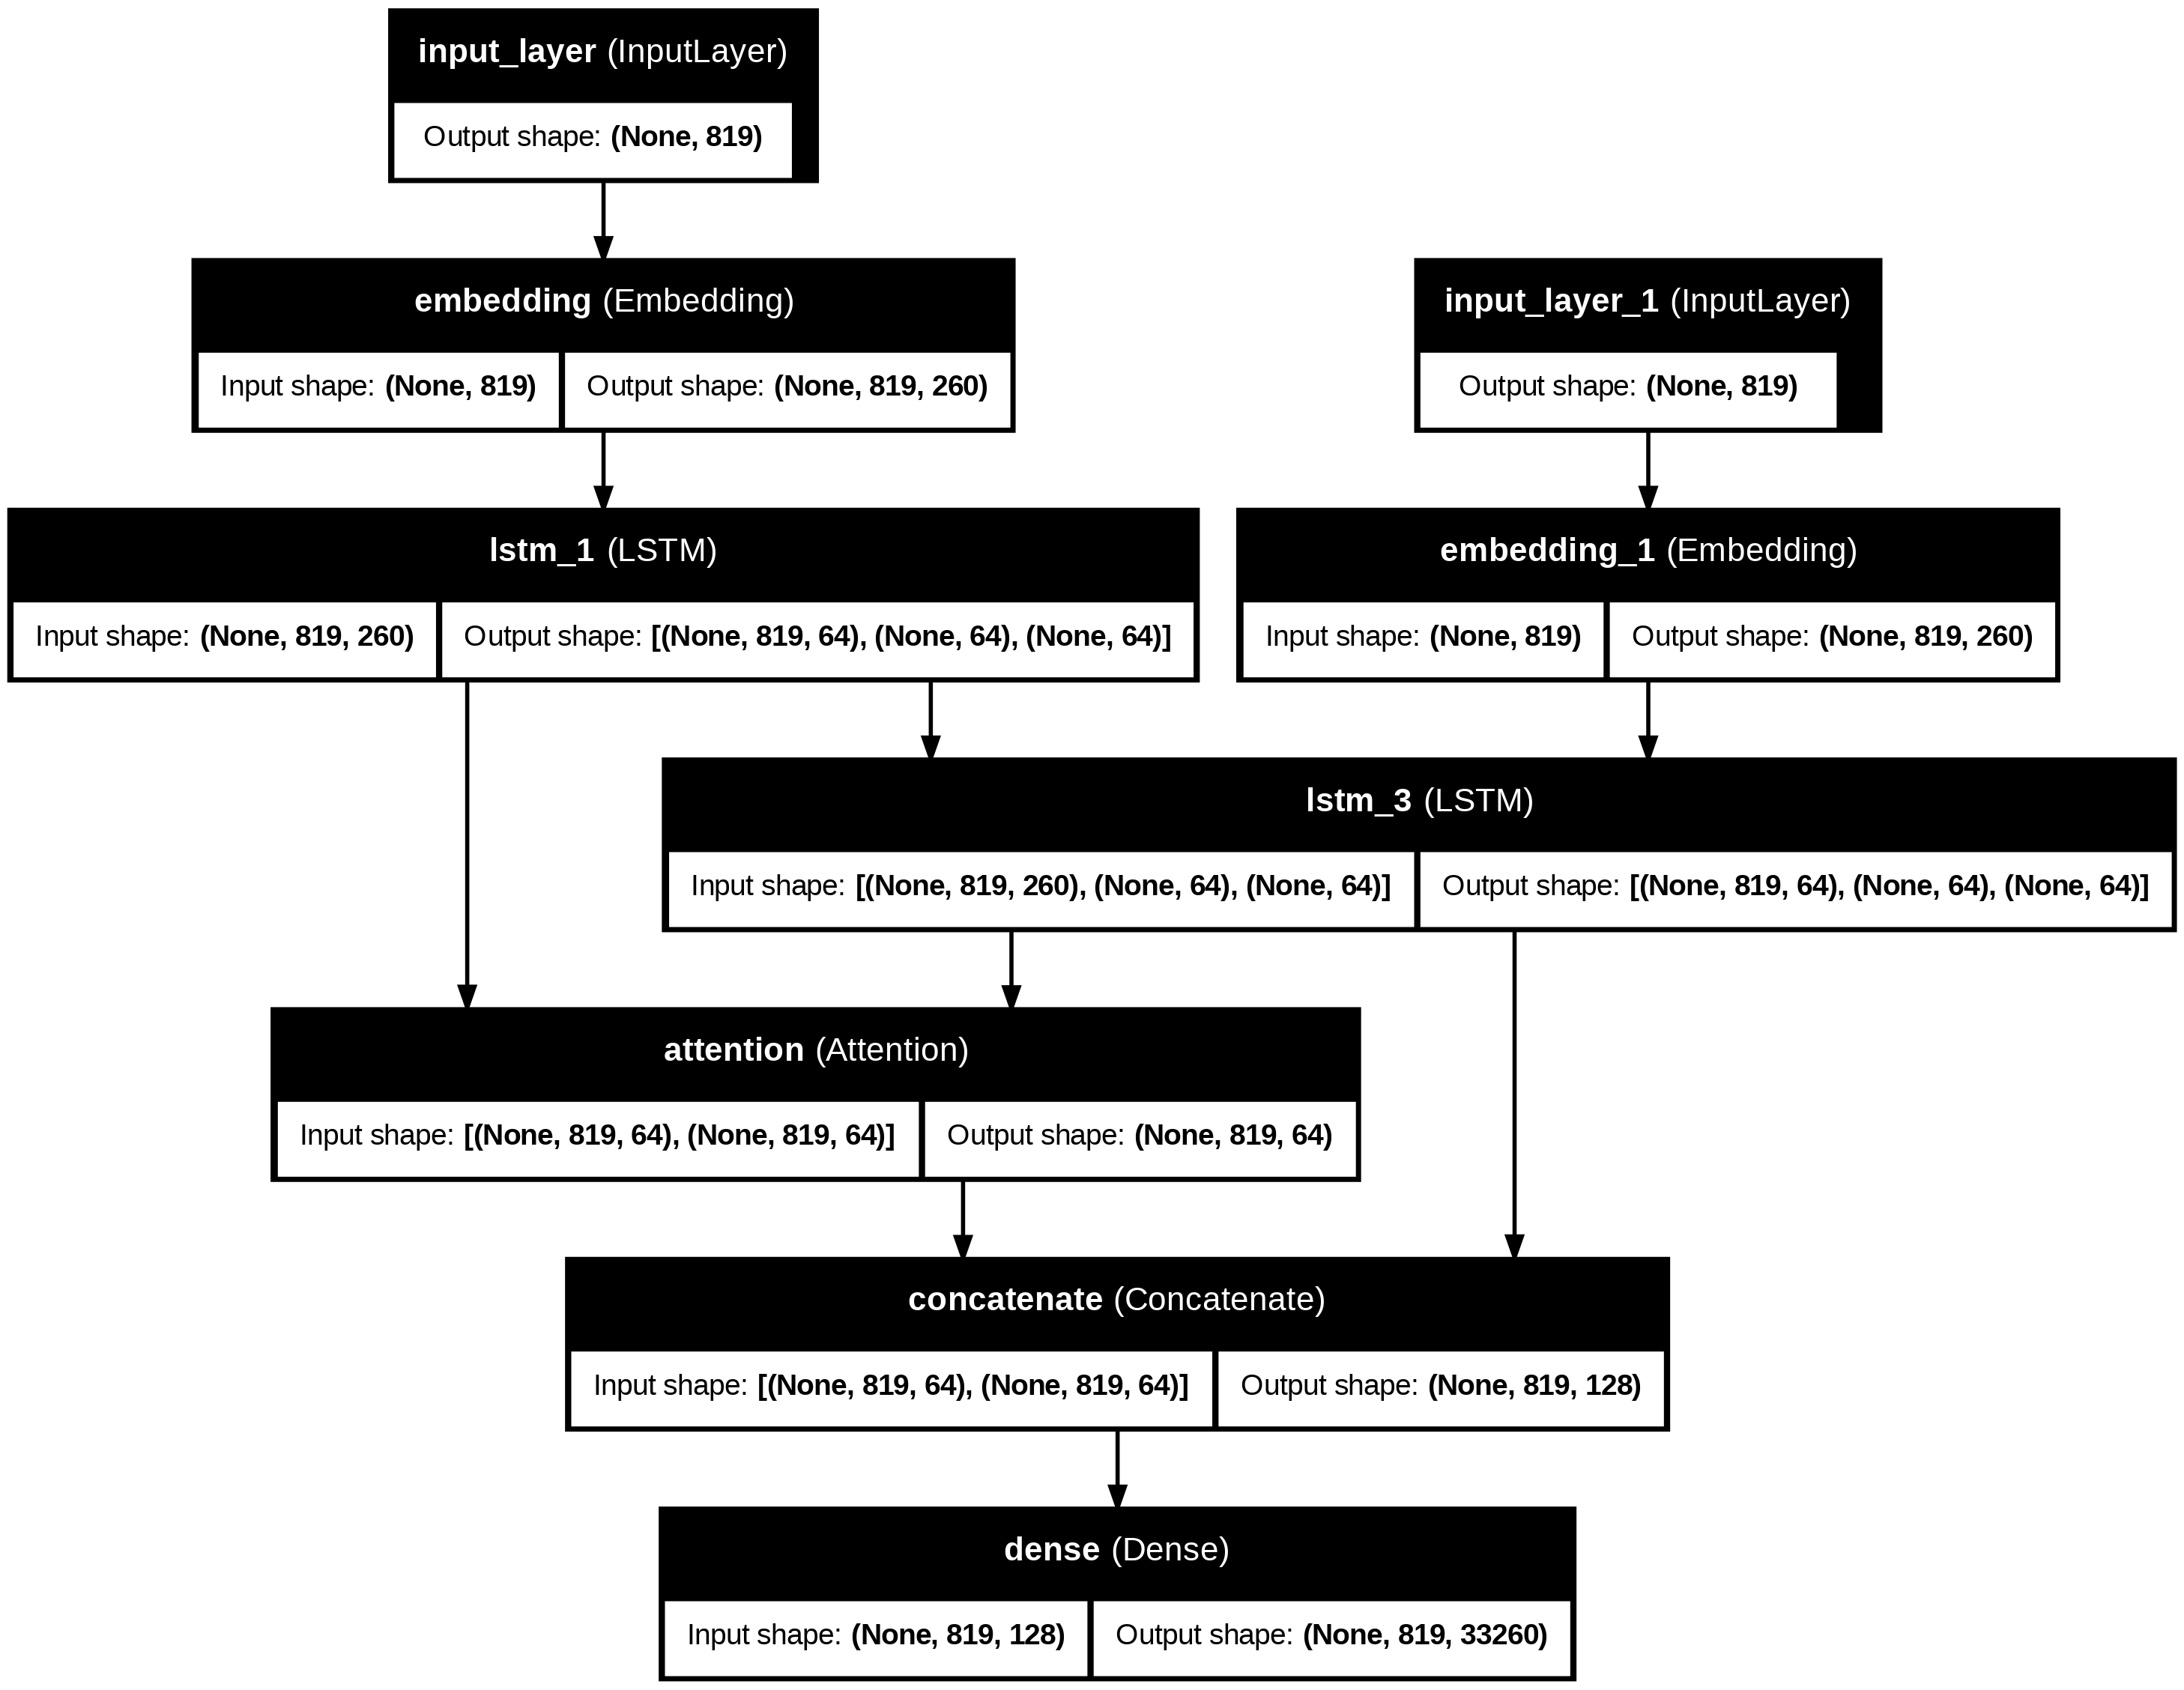

In [ ]:
from tensorflow.keras.utils import plot_model
from IPython.display import Image
plot_model(model, to_file='model_plot.png', show_shapes=True, show_layer_names=True)
Image('model_plot.png')

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
model_checkpoint = ModelCheckpoint('model_checkpoint.keras', save_best_only=True)  # Updated filepath

# Train the model with callbacks
history = model.fit(
    x=[x_train, y_train],
    y=y_train,
    batch_size=16,
    epochs=5,
    validation_data=([x_test, y_test], y_test),
    callbacks=[early_stopping, model_checkpoint],
)

Epoch 1/5
921/921 ━━━━━━━━━━━━━━━━━━━━ 347s 370ms/step - accuracy: 0.9674 - loss: 1.2663 - val_accuracy: 0.9854 - val_loss: 0.1174
Epoch 2/5
921/921 ━━━━━━━━━━━━━━━━━━━━ 381s 373ms/step - accuracy: 0.9866 - loss: 0.1104 - val_accuracy: 0.9907 - val_loss: 0.0751
Epoch 3/5
921/921 ━━━━━━━━━━━━━━━━━━━━ 391s 383ms/step - accuracy: 0.9910 - loss: 0.0743 - val_accuracy: 0.9940 - val_loss: 0.0528
Epoch 4/5
921/921 ━━━━━━━━━━━━━━━━━━━━ 373s 373ms/step - accuracy: 0.9939 - loss: 0.0529 - val_accuracy: 0.9955 - val_loss: 0.0397
Epoch 5/5
921/921 ━━━━━━━━━━━━━━━━━━━━ 383s 374ms/step - accuracy: 0.9954 - loss: 0.0402 - val_accuracy: 0.9964 - val_loss: 0.0321


ENCODER-DECODER MODEL WITH ATTENTION EVALUATION

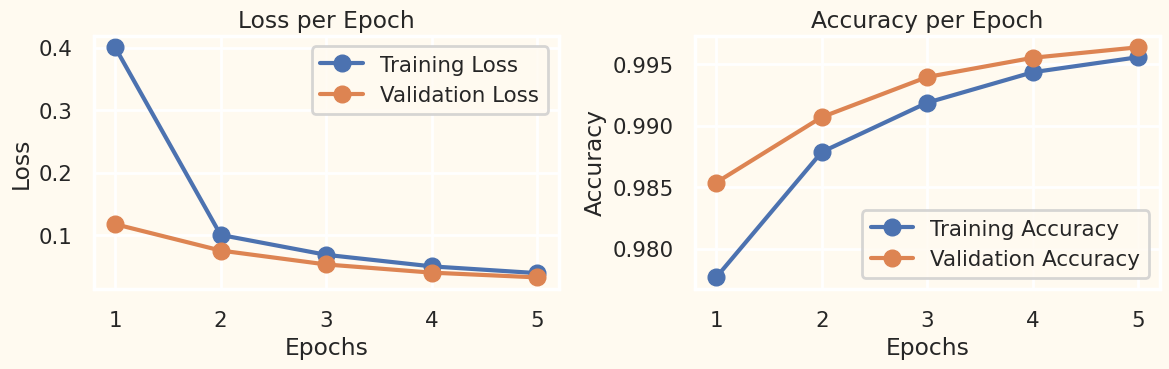

In [ ]:
epochs_range = range(1, len(history.history['loss']) + 1)

plt.figure(figsize=(12, 4))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history['loss'], label='Training Loss', marker='o')
plt.plot(epochs_range, history.history['val_loss'], label='Validation Loss', marker='o')
plt.title('Loss per Epoch')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.xticks(epochs_range)
plt.legend()

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(epochs_range, history.history['val_accuracy'], label='Validation Accuracy', marker='o')
plt.title('Accuracy per Epoch')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.xticks(epochs_range)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
from nltk.translate.bleu_score import corpus_bleu

# Reverse token dictionary for summary (assuming you have a tokenizer `tok` for summary)
rev_tok_summary = {idx: word for word, idx in tok.word_index.items()}
rev_tok_dialogue = {idx: word for word, idx in tok.word_index.items()}  # If the dialogue uses the same tokenizer

# Define the batch size
batch_size = 10

# Initialize lists to store predictions and references
predicted_summaries = []
references = []

# Predict on x_test data in batches
for start in range(0, len(x_test), batch_size):
    end = min(start + batch_size, len(x_test))
    x_batch = x_test[start:end]
    y_batch = y_test[start:end]  # Use the corresponding y_test for padding purposes

    # Predict on the batch
    predictions = model.predict([x_batch, y_batch], batch_size=batch_size)

    # Convert predicted tokens to sentences (predicted summaries)
    predicted_tokens_np = np.argmax(predictions, axis=-1)

    for sample in predicted_tokens_np:
        # Convert the predicted tokens into the corresponding words for the summary
        predicted_sentence = ' '.join([rev_tok_summary.get(token, '<unknown>') for token in sample if token != 0 and token not in [tok.word_index.get('start'), tok.word_index.get('end')]])
        predicted_summaries.append(predicted_sentence)

    # Extract the true (actual) summaries for the BLEU score references
    for i in range(len(y_batch)): #Corrected the indentation here to align with outer loop
        true_summary_sentence = ' '.join([rev_tok_summary.get(token, '<unknown>') for token in y_batch[i] if token != 0 and token not in [tok.word_index.get('start'), tok.word_index.get('end')]])
        references.append([true_summary_sentence.split()])  # BLEU expects list of references for each hypothesis

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━

In [ ]:
# Evaluate BLEU score for the predicted summaries
bleu_score = corpus_bleu(references, [pred.split() for pred in predicted_summaries])
print(f'BLEU score: {bleu_score:.4f}')

BLEU score: 0.6878


PREDICTION FROM ENCODER-DECODER MODEL WITH ATTENTION

In [ ]:
import numpy as np
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'

# Reverse token dictionaries
rev_tok = {idx: word for word, idx in tok.word_index.items()}

# Select a subset of test data
num_samples = 5
x_test_subset = x_test[:num_samples]
y_test_padded_subset = y_test[:num_samples]

# Predict
predictions = model.predict([x_test_subset, y_test_padded_subset], batch_size=16)
print('Shape of predictions:', predictions.shape)

# Convert predictions to token indices
predicted_tokens_np = np.argmax(predictions, axis=-1)
print('Shape of predicted_tokens:', predicted_tokens_np.shape)

# Map indices to tokens and remove 'start' and 'end' tokens from predicted summary
predicted_sentences = []
for sample in predicted_tokens_np:
    sentence = ' '.join([rev_tok.get(token, '<unknown>') for token in sample if token != 0 and token not in [tok.word_index.get('start'), tok.word_index.get('end')]])  # Exclude padding, 'start', and 'end' tokens
    predicted_sentences.append(sentence)

# Reverse token dictionary for the dialogue (assuming you have `tok_english` for dialogue tokens)
rev_tok_english = {idx: word for word, idx in tok.word_index.items()}

# Map the dialogue input to sentences
english_sentences = []
for sample in x_test_subset:
    sentence = ' '.join([rev_tok_english.get(token, '<unknown>') for token in sample if token != 0])  # Exclude padding token
    english_sentences.append(sentence)

# Map actual summaries from y_test to sentences
actual_summaries = []
for sample in y_test_padded_subset:
    sentence = ' '.join([rev_tok.get(token, '<unknown>') for token in sample if token != 0 and token not in [tok.word_index.get('start'), tok.word_index.get('end')]])  # Exclude padding, 'start', and 'end' tokens
    actual_summaries.append(sentence)

# Print the dialogue, predicted summary, and actual summary
for idx, (eng_sentence, pred_summary, actual_summary) in enumerate(zip(english_sentences, predicted_sentences, actual_summaries)):
    print(f'Dialogue {idx + 1}: {eng_sentence}')
    print(f'Predicted summary {idx + 1}: {pred_summary}')
    print(f'Actual summary {idx + 1}: {actual_summary}\n')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Shape of predictions: (5, 819, 33260)
Shape of predicted_tokens: (5, 819)
Dialogue 1: hannah hey do you have bettys number amanda let me check hannah filegif amanda sorry cannot find it amanda ask larry amanda he called her last tears in my eyes we were at the park together hannah i do not know him well hannah filegif amanda do not be shy hes very nice hannah if you say so hannah id rather you texted him amanda just text him hannah urgh alright hannah bye amanda bye bye
Predicted summary 1: hannah needs unwell number but amanda does not have it she needs to contact larry
Actual summary 1: hannah needs bettys number but amanda does not have it she needs to contact larry

Dialogue 2: eric machine rob that is so great eric i know and shows how americans see russian rob and its really funny eric i know i especially like the train part rob hahaha no one talks to the machine like that eric is this his only standup rob i do not know ill check eric sure ro

Saving the best weight

In [ ]:
# Save the entire model
model.save('encoder_decoder_model.h5')
print('Model saved succesfully!!')

Model saved succesfully!!


In [ ]:
bart

In [ ]:
#Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.tokenize import sent_tokenize
import nltk
import warnings

import plotly.express as px
import plotly.io as pio

warnings.filterwarnings("ignore")

In [ ]:
nltk.download('punkt')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


True

In [ ]:
train_file = "/content/drive/MyDrive/Major Project/samsum-train.csv/samsum-train.csv"
df = pd.read_csv(train_file)

df

,id,dialogue,summary
0,13818513,Amanda: I baked cookies. Do you want some?\r\...,Amanda baked cookies and will bring Jerry some...
1,13728867,Olivia: Who are you voting for in this electio...,Olivia and Olivier are voting for liberals in ...
2,13681000,"Tim: Hi, what's up?\r\nKim: Bad mood tbh, I wa...",Kim may try the pomodoro technique recommended...
3,13730747,"Edward: Rachel, I think I'm in ove with Bella....",Edward thinks he is in love with Bella. Rachel...
4,13728094,Sam: hey overheard rick say something\r\nSam:...,"Sam is confused, because he overheard Rick com..."
...,...,...,...
14727,13863028,Romeo: You are on my ‘People you may know’ lis...,Romeo is trying to get Greta to add him to her...
14728,13828570,Theresa: <file_photo>\r\nTheresa: <file_photo>...,Theresa is at work. She gets free food and fre...
14729,13819050,John: Every day some bad news. Japan will hunt...,Japan is going to hunt whales again. Island an...
14730,13828395,Jennifer: Dear Celia! How are you doing?\r\nJe...,Celia couldn't make it to the afternoon with t...


In [ ]:
df = df[0: 1000]

df

,id,dialogue,summary
0,13818513,Amanda: I baked cookies. Do you want some?\r\...,Amanda baked cookies and will bring Jerry some...
1,13728867,Olivia: Who are you voting for in this electio...,Olivia and Olivier are voting for liberals in ...
2,13681000,"Tim: Hi, what's up?\r\nKim: Bad mood tbh, I wa...",Kim may try the pomodoro technique recommended...
3,13730747,"Edward: Rachel, I think I'm in ove with Bella....",Edward thinks he is in love with Bella. Rachel...
4,13728094,Sam: hey overheard rick say something\r\nSam:...,"Sam is confused, because he overheard Rick com..."
...,...,...,...
995,13815986,"Hazel: Hello Brad. That's insane, we havent se...",Brad is visiting his parents today and cannot ...
996,13717031,"Kitty: I don’t have your account numbers, coul...",Kitty will convey money to Barb and Ken.
997,13680667,Max: I'll be late\r\nSylvia: why:\r\nMax: beer...,Max will be late because he is having a drink ...
998,13829491,"Karolina: hi darling, when are you back in Wa...",Karolina will be back in Warsaw this weekend t...


In [ ]:
print(df['summary'].at[0])

Amanda baked cookies and will bring Jerry some tomorrow.


In [ ]:
df.head()

,id,dialogue,summary
0,13818513,Amanda: I baked cookies. Do you want some?\r\...,Amanda baked cookies and will bring Jerry some...
1,13728867,Olivia: Who are you voting for in this electio...,Olivia and Olivier are voting for liberals in ...
2,13681000,"Tim: Hi, what's up?\r\nKim: Bad mood tbh, I wa...",Kim may try the pomodoro technique recommended...
3,13730747,"Edward: Rachel, I think I'm in ove with Bella....",Edward thinks he is in love with Bella. Rachel...
4,13728094,Sam: hey overheard rick say something\r\nSam:...,"Sam is confused, because he overheard Rick com..."


In [ ]:
df.tail()

,id,dialogue,summary
995,13815986,"Hazel: Hello Brad. That's insane, we havent se...",Brad is visiting his parents today and cannot ...
996,13717031,"Kitty: I don’t have your account numbers, coul...",Kitty will convey money to Barb and Ken.
997,13680667,Max: I'll be late\r\nSylvia: why:\r\nMax: beer...,Max will be late because he is having a drink ...
998,13829491,"Karolina: hi darling, when are you back in Wa...",Karolina will be back in Warsaw this weekend t...
999,13864606,Paula: I'm submitting my thesis this week\nMar...,Paula is submitting her thesis this week.


In [ ]:
df.sample(5)

,id,dialogue,summary
396,13819192,Joseph: We should collect some money for the i...,Joseph and Donald believe they need another in...
123,13863151,Josh: You're a nutter!!!\nJosh: I could never ...,Paul didn't convince Josh to go bungee jumping...
624,13716867,Randall: <file_video>\r\nWilfred: wtf? what's ...,Wilfred's got Randall's video. Paige and Finch...
313,13612050,Lily: Congratulations brother! I just heard fr...,Lily is congratulating Peter and his team on t...
23,13728653,Renee: Just saying Hi. Thought of you this mor...,Layla the dog misses Rachel. She is having a k...


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        1000 non-null   object
 1   dialogue  1000 non-null   object
 2   summary   1000 non-null   object
dtypes: object(3)
memory usage: 23.6+ KB


In [ ]:
df.isna().sum()

,0
id,0
dialogue,0
summary,0


In [ ]:
df = df.dropna()

df

,id,dialogue,summary
0,13818513,Amanda: I baked cookies. Do you want some?\r\...,Amanda baked cookies and will bring Jerry some...
1,13728867,Olivia: Who are you voting for in this electio...,Olivia and Olivier are voting for liberals in ...
2,13681000,"Tim: Hi, what's up?\r\nKim: Bad mood tbh, I wa...",Kim may try the pomodoro technique recommended...
3,13730747,"Edward: Rachel, I think I'm in ove with Bella....",Edward thinks he is in love with Bella. Rachel...
4,13728094,Sam: hey overheard rick say something\r\nSam:...,"Sam is confused, because he overheard Rick com..."
...,...,...,...
995,13815986,"Hazel: Hello Brad. That's insane, we havent se...",Brad is visiting his parents today and cannot ...
996,13717031,"Kitty: I don’t have your account numbers, coul...",Kitty will convey money to Barb and Ken.
997,13680667,Max: I'll be late\r\nSylvia: why:\r\nMax: beer...,Max will be late because he is having a drink ...
998,13829491,"Karolina: hi darling, when are you back in Wa...",Karolina will be back in Warsaw this weekend t...


In [ ]:
df.isna().sum()

,0
id,0
dialogue,0
summary,0


In [ ]:
!pip install contractions

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 289.9/289.9 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.3/118.3 kB 11.9 MB/s eta 0:00:00


In [ ]:
!pip install emoji
import re
import spacy
import emoji
from contractions import fix

nlp = spacy.load("en_core_web_sm")

# Clean Dialogue (Input)
def clean_dialogue(dialogue):
    dialogue = re.sub(r"<.*?>", "", dialogue)  # Remove special tags
    dialogue = re.sub(r"\\r\\n", " ", dialogue)  # Replace newlines
    dialogue = re.sub(r"\s+", " ", dialogue).strip()  # Remove extra spaces
    dialogue = dialogue.lower()  # Convert to lowercase
    dialogue = fix(dialogue)  # Expand contractions
    dialogue = emoji.demojize(dialogue)  # Convert emojis to text
    doc = nlp(dialogue)
    dialogue = " ".join([token.lemma_ for token in doc if not token.is_punct])  # Lemmatize
    return dialogue

# Clean Summary (Label)
def clean_summary(summary):
    summary = re.sub(r"\s+", " ", summary).strip()  # Remove extra spaces
    summary = re.sub(r"\\r\\n", " ", summary)  # Replace newlines
    summary = fix(summary)  # Expand contractions
    return summary

# Apply Cleaning
df["cleaned_dialogue"] = df["dialogue"].apply(clean_dialogue)
df["cleaned_summary"] = df["summary"].apply(clean_summary)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 590.6/590.6 kB 13.8 MB/s eta 0:00:00


In [ ]:
df

,id,dialogue,summary,cleaned_dialogue,cleaned_summary
0,13818513,Amanda: I baked cookies. Do you want some?\r\...,Amanda baked cookies and will bring Jerry some...,amanda I bake cookie do you want some jerry su...,Amanda baked cookies and will bring Jerry some...
1,13728867,Olivia: Who are you voting for in this electio...,Olivia and Olivier are voting for liberals in ...,olivia who be you vote for in this election ol...,Olivia and Olivier are voting for liberals in ...
2,13681000,"Tim: Hi, what's up?\r\nKim: Bad mood tbh, I wa...",Kim may try the pomodoro technique recommended...,tim hi what be up kim bad mood to be honest I ...,Kim may try the pomodoro technique recommended...
3,13730747,"Edward: Rachel, I think I'm in ove with Bella....",Edward thinks he is in love with Bella. Rachel...,edward rachel I think I be in ove with bella r...,Edward thinks he is in love with Bella. Rachel...
4,13728094,Sam: hey overheard rick say something\r\nSam:...,"Sam is confused, because he overheard Rick com...",sam hey overheard rick say something sam I do ...,"Sam is confused, because he overheard Rick com..."
...,...,...,...,...,...
995,13815986,"Hazel: Hello Brad. That's insane, we havent se...",Brad is visiting his parents today and cannot ...,hazel hello brad that be insane we have not se...,Brad is visiting his parents today and cannot ...
996,13717031,"Kitty: I don’t have your account numbers, coul...",Kitty will convey money to Barb and Ken.,kitty I do not have your account number could ...,Kitty will convey money to Barb and Ken.
997,13680667,Max: I'll be late\r\nSylvia: why:\r\nMax: beer...,Max will be late because he is having a drink ...,max I will be late sylvia why max beer with to...,Max will be late because he is having a drink ...
998,13829491,"Karolina: hi darling, when are you back in Wa...",Karolina will be back in Warsaw this weekend t...,karolina hi darling when be you back in warsaw...,Karolina will be back in Warsaw this weekend t...


In [ ]:
# Function to calculate word count
def word_count(text):
    return len(text.split())
def char_count(text):
    return len(text)

# Function to calculate unique word count
def unique_word_count(text):
    return len(set(text.split()))

# Function to calculate average word length
def avg_word_length(text):
    words = text.split()
    if len(words) > 0:
        return sum(len(word) for word in words) / len(words)
    else:
        return 0

# Add columns to the DataFrame
df['dialogue_word_count'] = df['cleaned_dialogue'].apply(word_count)
df['summary_word_count'] = df['cleaned_summary'].apply(word_count)
df['dialogue_char_count'] = df['cleaned_dialogue'].apply(char_count)
df['summary_char_count'] = df['cleaned_summary'].apply(char_count)

df['dialogue_unique_word_count'] = df['cleaned_dialogue'].apply(unique_word_count)
df['summary_unique_word_count'] = df['cleaned_summary'].apply(unique_word_count)

df['dialogue_avg_word_length'] = df['cleaned_dialogue'].apply(avg_word_length)
df['summary_avg_word_length'] = df['cleaned_summary'].apply(avg_word_length)

df.head()

,id,dialogue,summary,cleaned_dialogue,cleaned_summary,dialogue_word_count,summary_word_count,dialogue_char_count,summary_char_count,dialogue_unique_word_count,summary_unique_word_count,dialogue_avg_word_length,summary_avg_word_length
0,13818513,Amanda: I baked cookies. Do you want some?\r\...,Amanda baked cookies and will bring Jerry some...,amanda I bake cookie do you want some jerry su...,Amanda baked cookies and will bring Jerry some...,16,9,81,56,13,9,4.125000,5.333333
1,13728867,Olivia: Who are you voting for in this electio...,Olivia and Olivier are voting for liberals in ...,olivia who be you vote for in this election ol...,Olivia and Olivier are voting for liberals in ...,18,10,94,60,16,10,4.277778,5.100000
2,13681000,"Tim: Hi, what's up?\r\nKim: Bad mood tbh, I wa...",Kim may try the pomodoro technique recommended...,tim hi what be up kim bad mood to be honest I ...,Kim may try the pomodoro technique recommended...,105,14,482,77,65,14,3.600000,4.571429
3,13730747,"Edward: Rachel, I think I'm in ove with Bella....",Edward thinks he is in love with Bella. Rachel...,edward rachel I think I be in ove with bella r...,Edward thinks he is in love with Bella. Rachel...,29,18,143,96,22,15,3.965517,4.388889
4,13728094,Sam: hey overheard rick say something\r\nSam:...,"Sam is confused, because he overheard Rick com...",sam hey overheard rick say something sam I do ...,"Sam is confused, because he overheard Rick com...",190,27,819,145,81,23,3.315789,4.407407


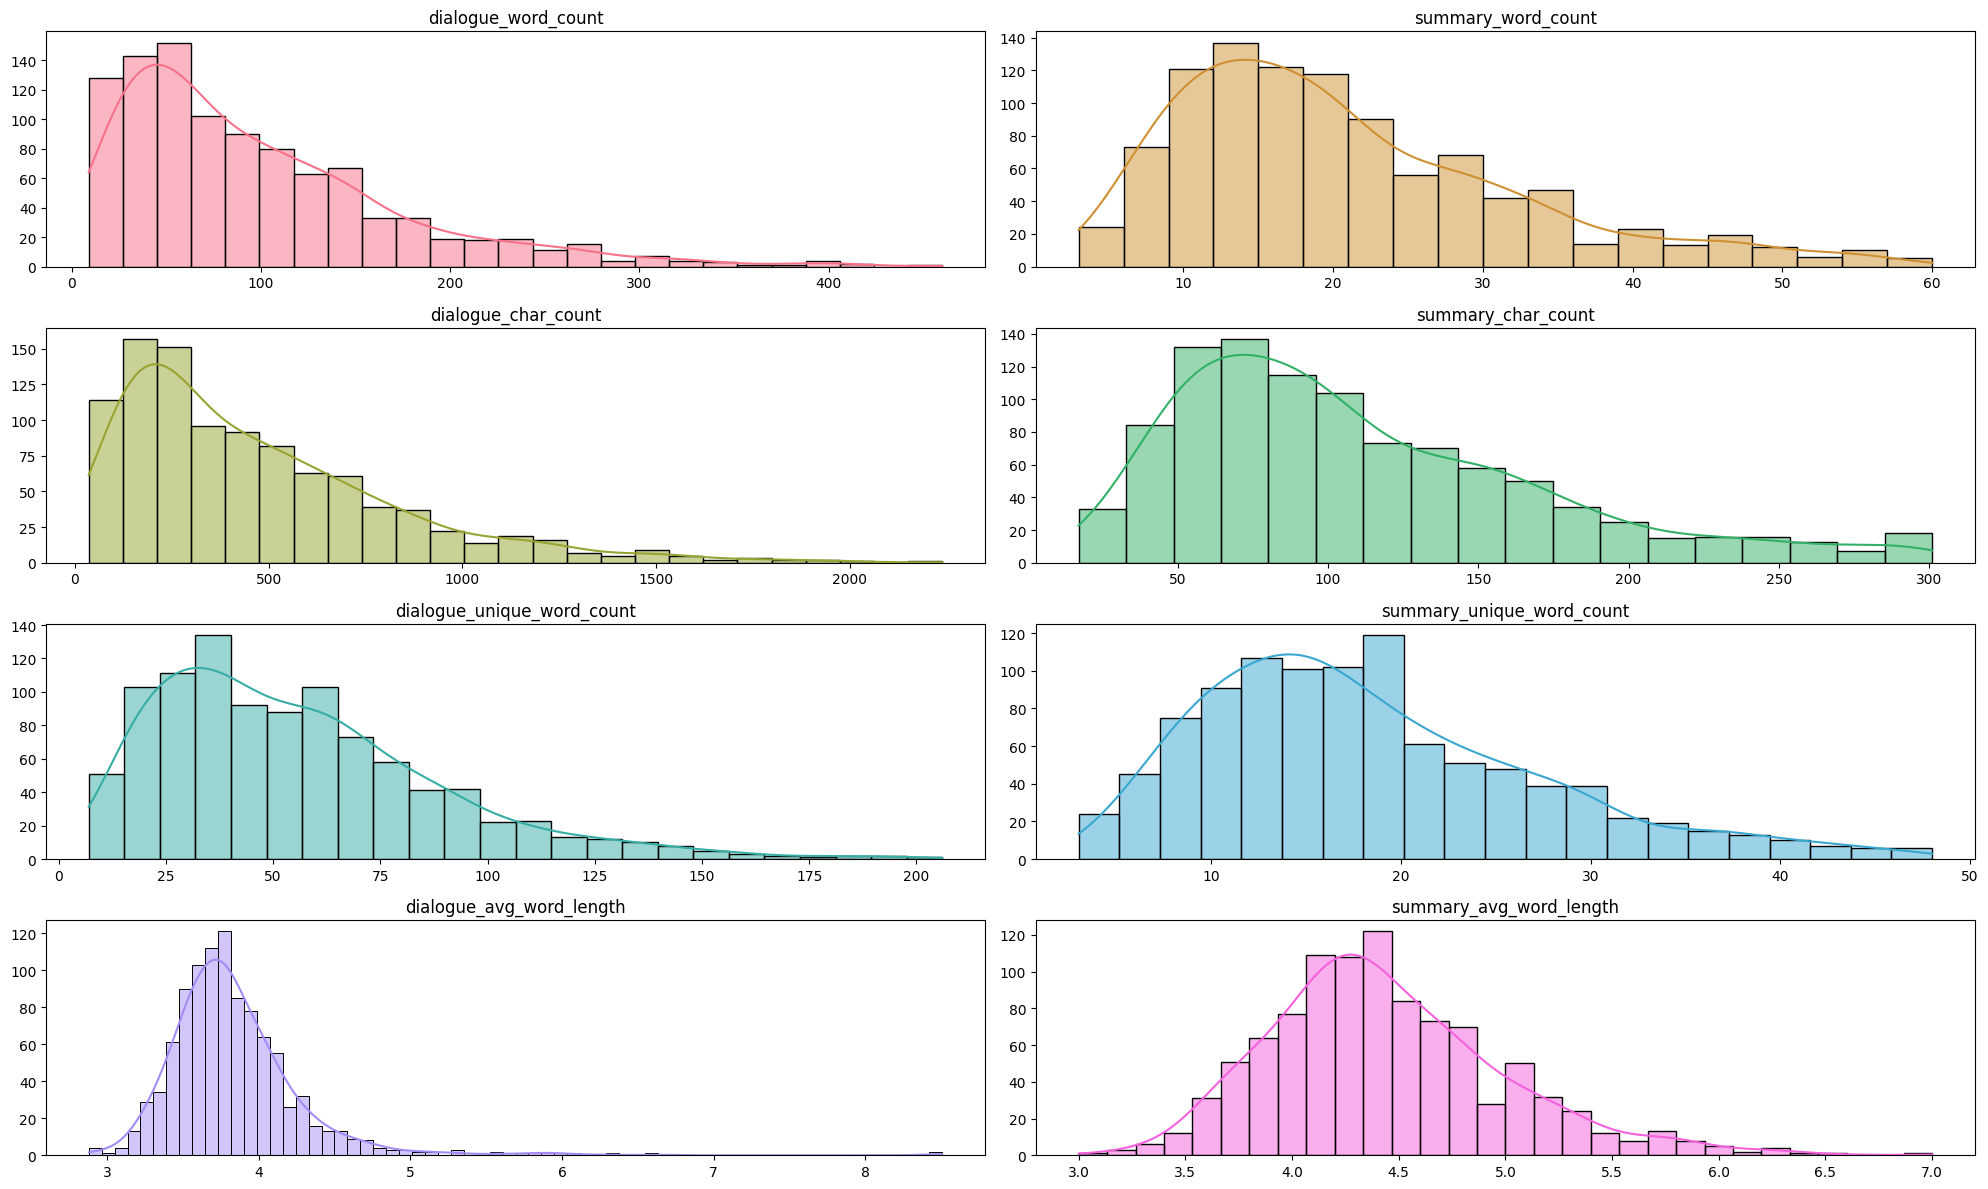

In [ ]:
columns = [
    "dialogue_word_count", "summary_word_count", "dialogue_char_count", "summary_char_count", "dialogue_unique_word_count", "summary_unique_word_count",

    "dialogue_avg_word_length","summary_avg_word_length"
]

# Define a list of unique colors (length should match or exceed the number of columns)
colors = sns.color_palette("husl", len(columns))  # 'husl' generates visually distinct colors

fig, axes = plt.subplots(4, 2, figsize=(20, 12))
axes = axes.flatten()

# Plot each column in the grid
for i, column in enumerate(columns):
    sns.histplot(df[column], kde=True, ax=axes[i], color=colors[i])
    axes[i].set_title(column)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")

# Remove any empty subplots
for j in range(len(columns), len(axes)):
    fig.delaxes(axes[j])

# Adjust layout
plt.tight_layout()
plt.show()

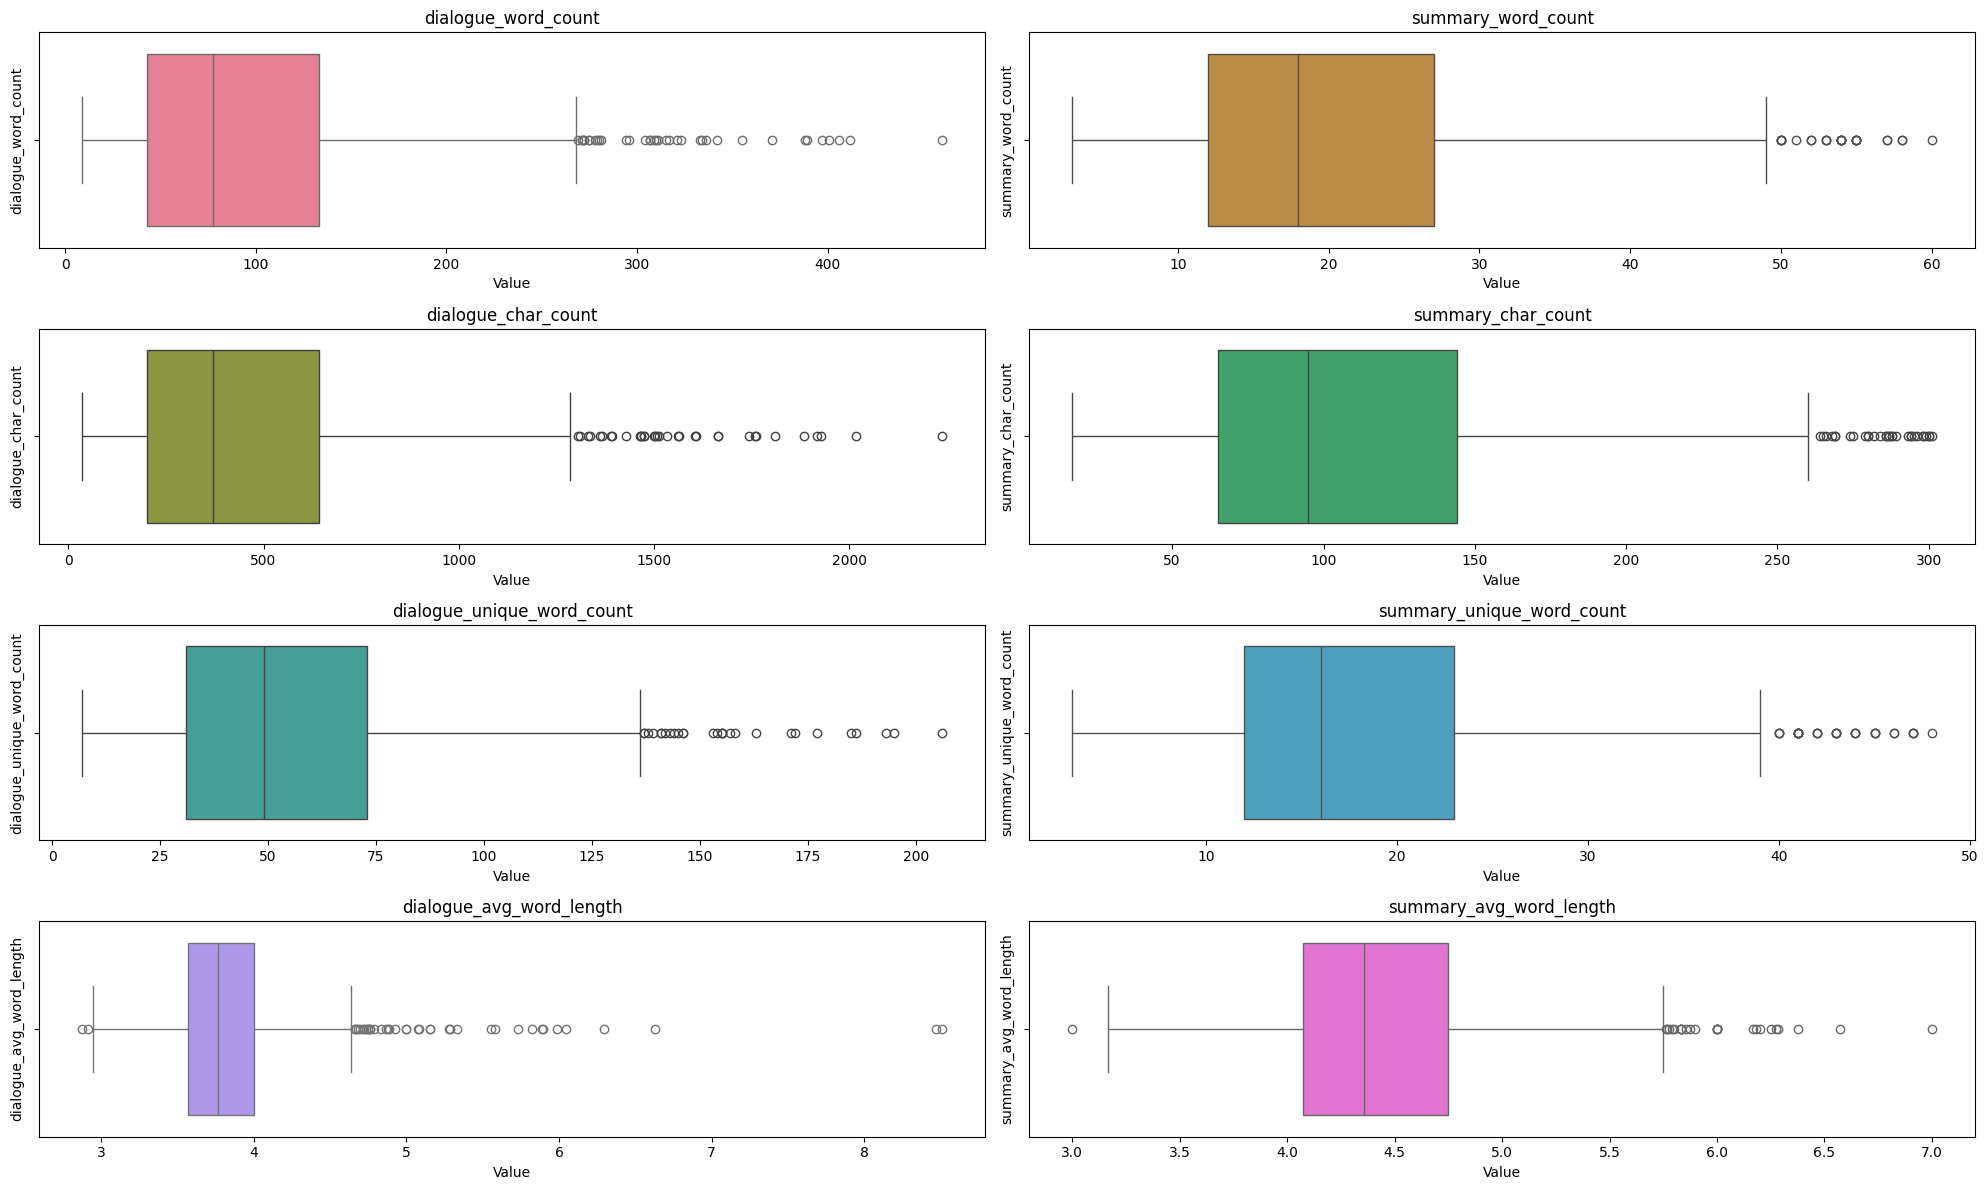

In [ ]:
# Define a list of unique colors (length should match or exceed the number of columns)
colors = sns.color_palette("husl", len(columns))  # 'husl' generates visually distinct colors

fig, axes = plt.subplots(4, 2, figsize=(20, 12))
axes = axes.flatten()

# Plot each column in the grid
for i, column in enumerate(columns):
    sns.boxplot(data=df, x=column, ax=axes[i], color=colors[i])  # Set `x=column` for horizontal box plots
    axes[i].set_title(column)
    axes[i].set_xlabel("Value")  # Generic x-axis label for all plots
    axes[i].set_ylabel(column)  # Show the column name on the y-axis

# Remove any empty subplots
for j in range(len(columns), len(axes)):
    fig.delaxes(axes[j])

# Adjust layout
plt.tight_layout()
plt.show()

In [ ]:
df.describe()

,dialogue_word_count,summary_word_count,dialogue_char_count,summary_char_count,dialogue_unique_word_count,summary_unique_word_count,dialogue_avg_word_length,summary_avg_word_length
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,97.225000,20.616000,468.554000,110.289000,55.612000,18.319000,3.838013,4.435965
std,73.744713,11.314175,356.831714,60.986136,33.057681,8.871637,0.463059,0.554059
min,9.000000,3.000000,36.000000,17.000000,7.000000,3.000000,2.877551,3.000000
25%,43.000000,12.000000,200.750000,65.000000,31.000000,12.000000,3.571429,4.075549
50%,77.500000,18.000000,371.000000,95.000000,49.000000,16.000000,3.766146,4.357143
75%,133.250000,27.000000,641.750000,144.250000,73.000000,23.000000,4.000000,4.750000
max,460.000000,60.000000,2238.000000,301.000000,206.000000,48.000000,8.509259,7.000000


In [ ]:
df

,id,dialogue,summary,cleaned_dialogue,cleaned_summary,dialogue_word_count,summary_word_count,dialogue_char_count,summary_char_count,dialogue_unique_word_count,summary_unique_word_count,dialogue_avg_word_length,summary_avg_word_length
0,13818513,Amanda: I baked cookies. Do you want some?\r\...,Amanda baked cookies and will bring Jerry some...,amanda I bake cookie do you want some jerry su...,Amanda baked cookies and will bring Jerry some...,16,9,81,56,13,9,4.125000,5.333333
1,13728867,Olivia: Who are you voting for in this electio...,Olivia and Olivier are voting for liberals in ...,olivia who be you vote for in this election ol...,Olivia and Olivier are voting for liberals in ...,18,10,94,60,16,10,4.277778,5.100000
2,13681000,"Tim: Hi, what's up?\r\nKim: Bad mood tbh, I wa...",Kim may try the pomodoro technique recommended...,tim hi what be up kim bad mood to be honest I ...,Kim may try the pomodoro technique recommended...,105,14,482,77,65,14,3.600000,4.571429
3,13730747,"Edward: Rachel, I think I'm in ove with Bella....",Edward thinks he is in love with Bella. Rachel...,edward rachel I think I be in ove with bella r...,Edward thinks he is in love with Bella. Rachel...,29,18,143,96,22,15,3.965517,4.388889
4,13728094,Sam: hey overheard rick say something\r\nSam:...,"Sam is confused, because he overheard Rick com...",sam hey overheard rick say something sam I do ...,"Sam is confused, because he overheard Rick com...",190,27,819,145,81,23,3.315789,4.407407
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,13815986,"Hazel: Hello Brad. That's insane, we havent se...",Brad is visiting his parents today and cannot ...,hazel hello brad that be insane we have not se...,Brad is visiting his parents today and cannot ...,271,49,1270,241,141,36,3.690037,3.938776
996,13717031,"Kitty: I don’t have your account numbers, coul...",Kitty will convey money to Barb and Ken.,kitty I do not have your account number could ...,Kitty will convey money to Barb and Ken.,45,8,205,40,38,8,3.577778,4.125000
997,13680667,Max: I'll be late\r\nSylvia: why:\r\nMax: beer...,Max will be late because he is having a drink ...,max I will be late sylvia why max beer with to...,Max will be late because he is having a drink ...,13,12,57,55,11,12,3.461538,3.666667
998,13829491,"Karolina: hi darling, when are you back in Wa...",Karolina will be back in Warsaw this weekend t...,karolina hi darling when be you back in warsaw...,Karolina will be back in Warsaw this weekend t...,114,18,538,100,76,16,3.728070,4.611111


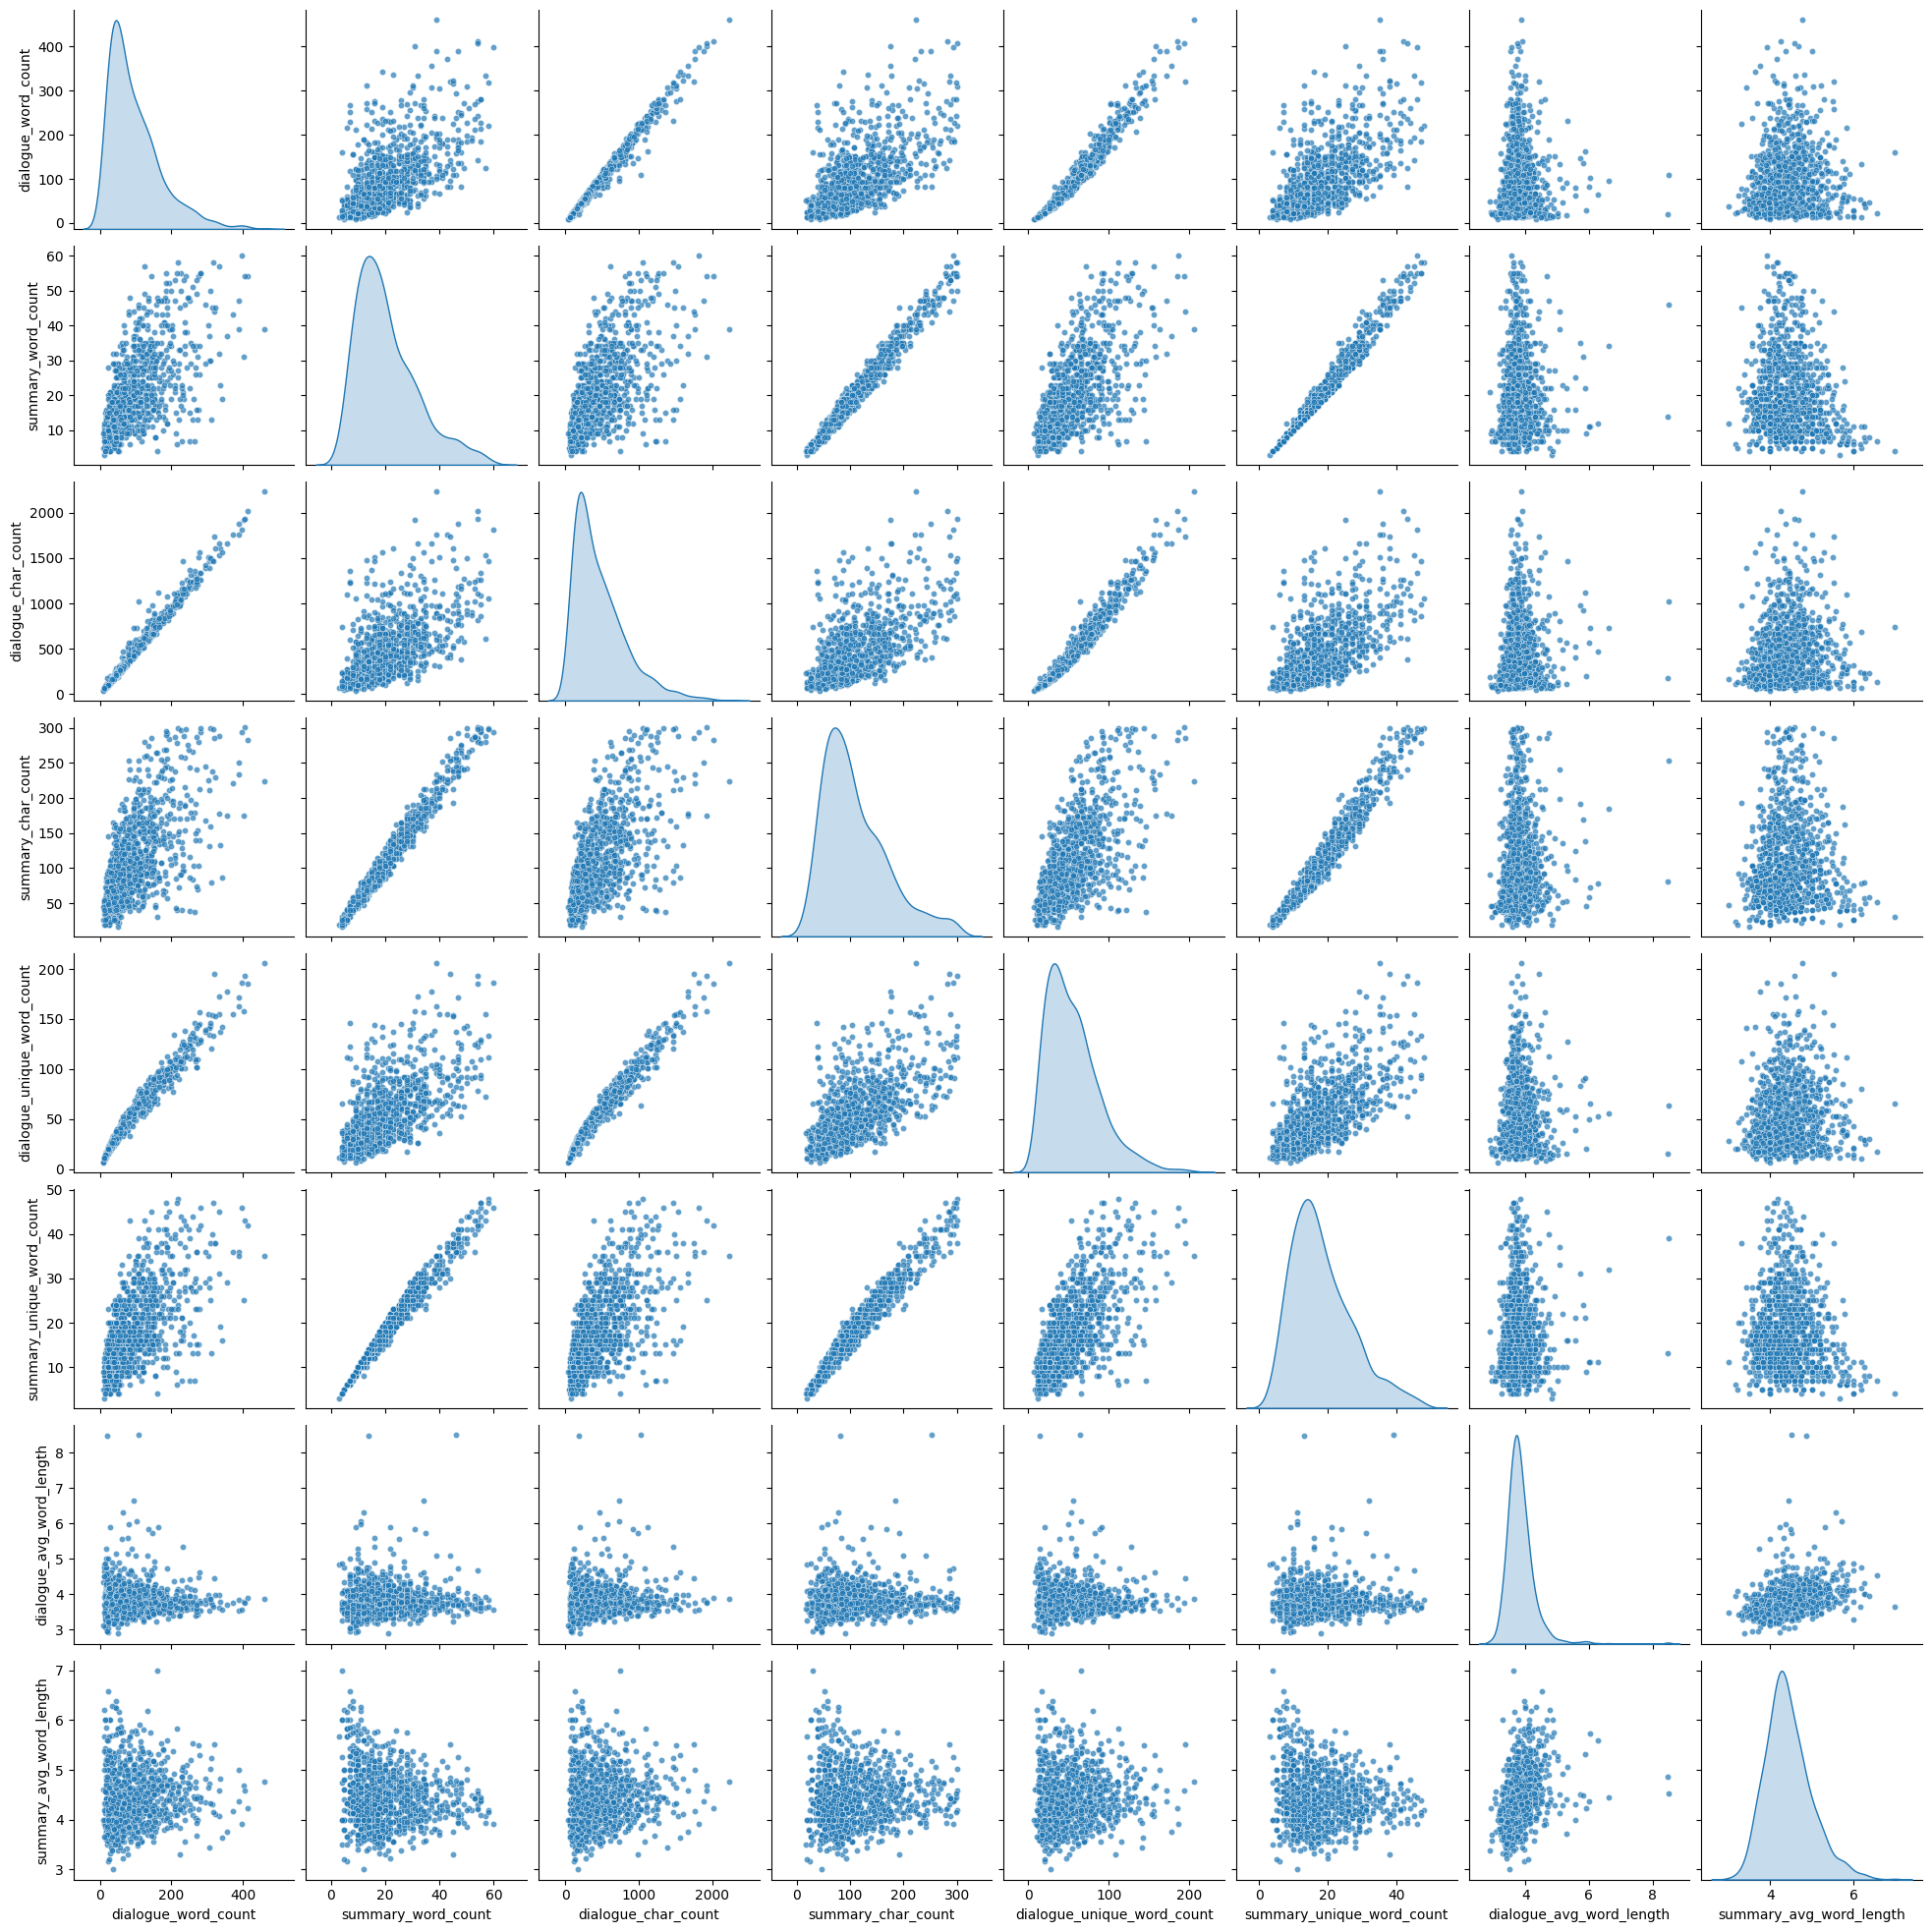

In [ ]:
# Select only the relevant columns from the DataFrame
correlation_data = df[columns]

# Create a pairplot for the selected columns
sns.pairplot(correlation_data, diag_kind="kde", plot_kws={"alpha": 0.7, "s": 20})

# Show the plots
plt.show()

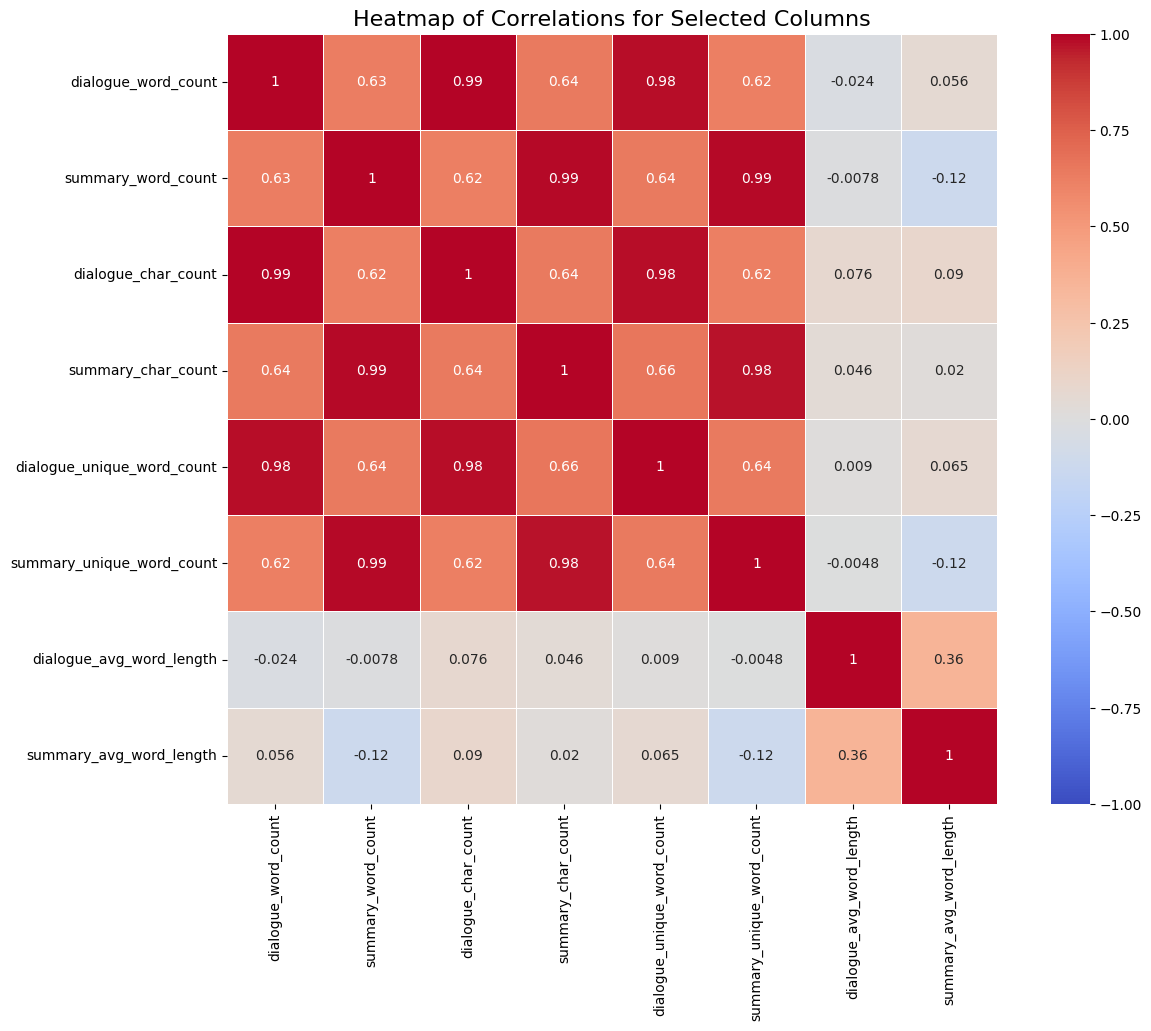

In [ ]:
corr_data = df[columns].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr_data, annot=True, cmap='coolwarm', vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('Heatmap of Correlations for Selected Columns', fontsize=16)
plt.show()

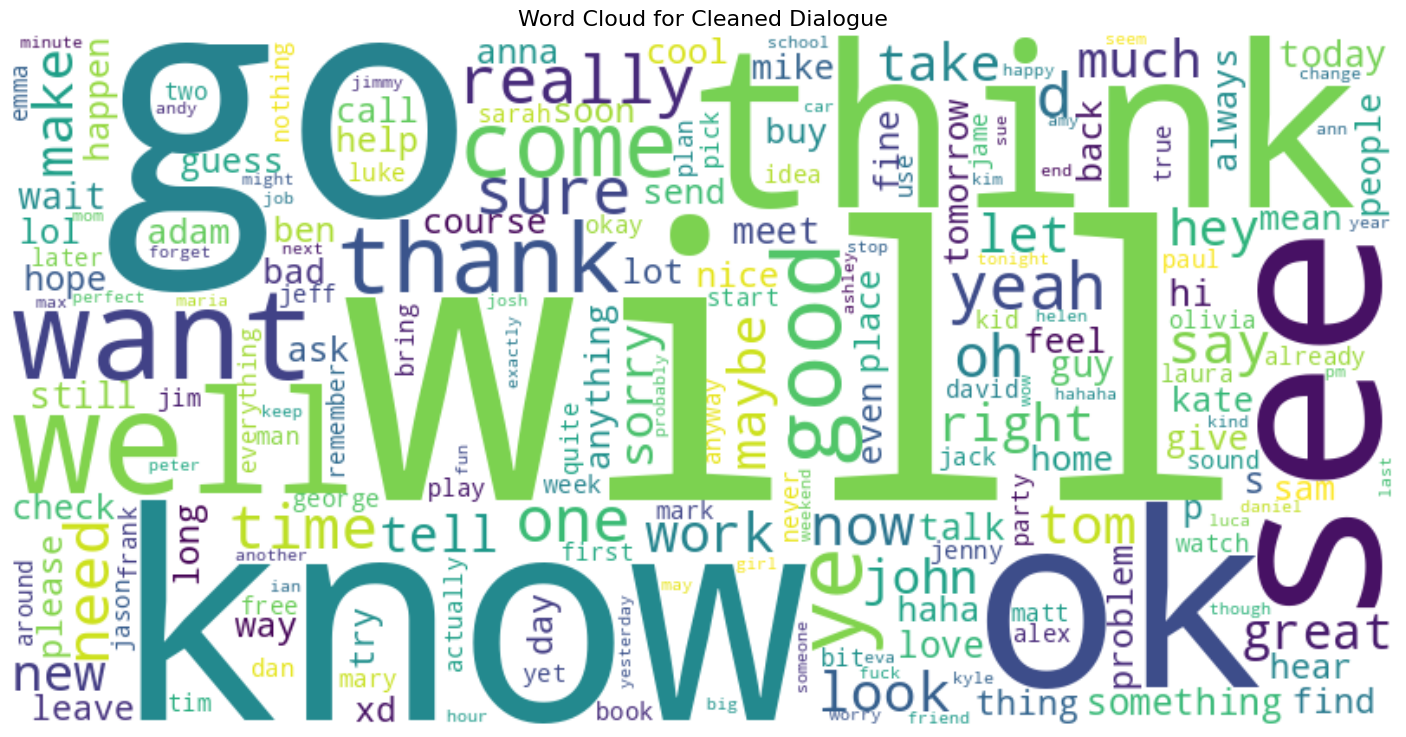

In [ ]:
from wordcloud import WordCloud, STOPWORDS

all_dialogues = " ".join(df["cleaned_dialogue"])

stopwords = set(STOPWORDS)

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    stopwords=stopwords,
    colormap='viridis',
    max_words=200,
    contour_width=1,
    contour_color='steelblue'
).generate(all_dialogues)

# Plot the word cloud
plt.figure(figsize=(20, 9))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud for Cleaned Dialogue", fontsize=16)
plt.show()

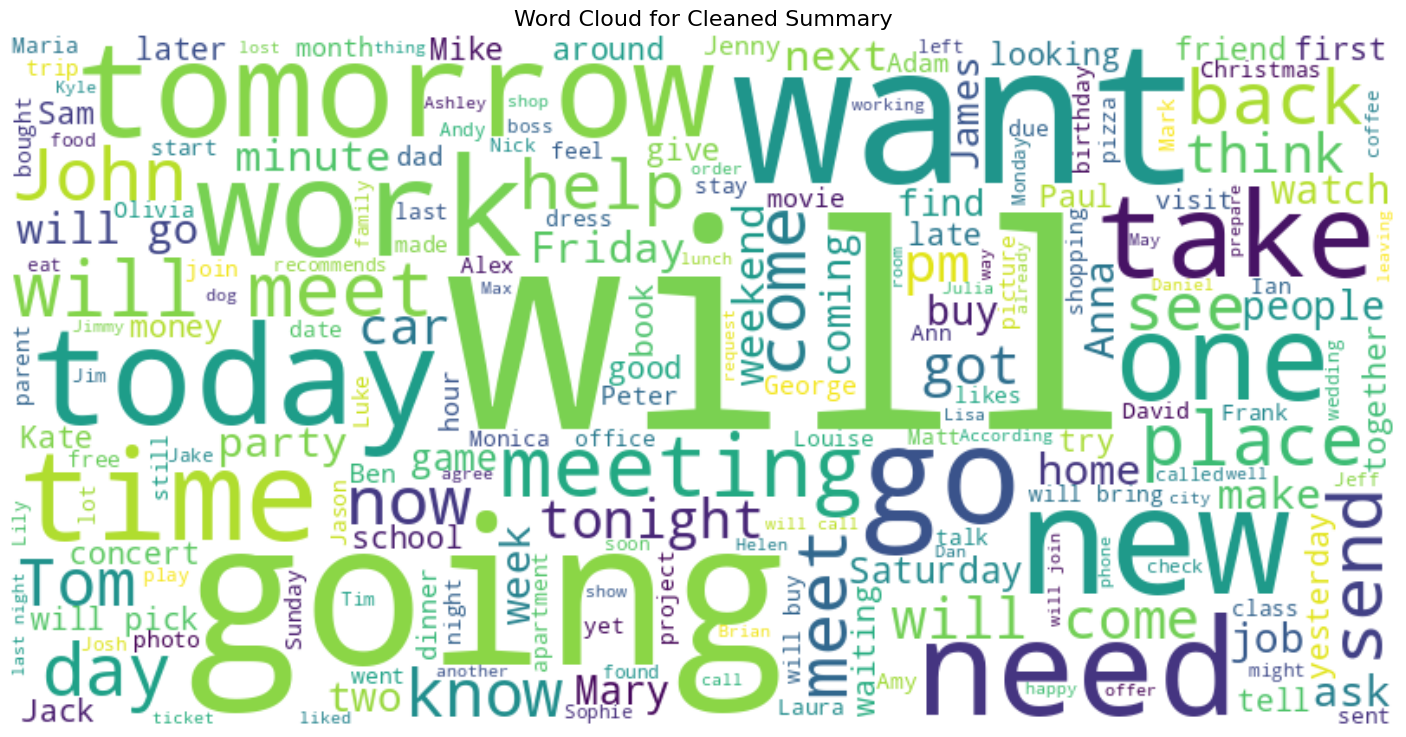

In [ ]:
from wordcloud import WordCloud, STOPWORDS

all_dialogues = " ".join(df["cleaned_summary"])

stopwords = set(STOPWORDS)

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    stopwords=stopwords,
    colormap='viridis',
    max_words=200,
    contour_width=1,
    contour_color='steelblue'
).generate(all_dialogues)

# Plot the word cloud
plt.figure(figsize=(20, 9))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud for Cleaned Summary", fontsize=16)
plt.show()

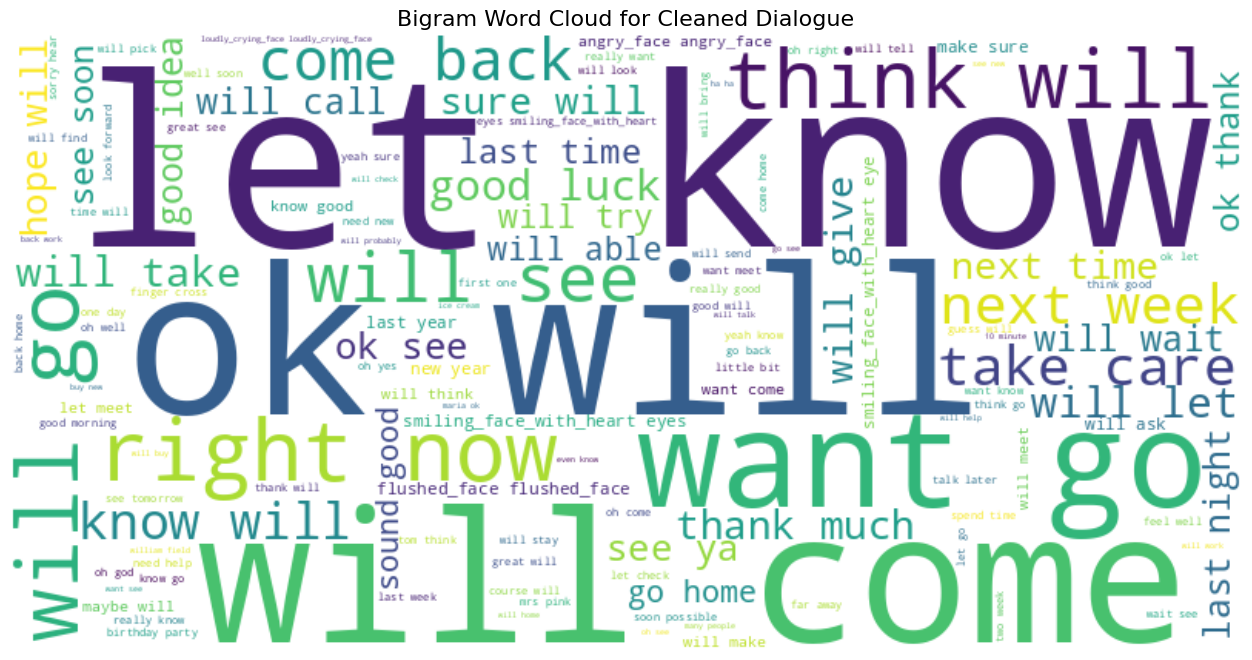

In [ ]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer

# Combine all cleaned dialogues into a single string
all_dialogues = " ".join(df["cleaned_dialogue"])

# Define stopwords (convert to list)
stopwords_list = list(STOPWORDS)

# Use CountVectorizer to extract bigrams
vectorizer = CountVectorizer(ngram_range=(2, 2), stop_words=stopwords_list)
X = vectorizer.fit_transform([all_dialogues])
bigram_freq = X.toarray().sum(axis=0)

# Create a DataFrame of bigrams and their frequencies
bigram_freq_df = pd.DataFrame(bigram_freq, index=vectorizer.get_feature_names_out(), columns=["frequency"])

# Sort bigrams by frequency
bigram_freq_df = bigram_freq_df.sort_values(by="frequency", ascending=False)

# Select the top 200 bigrams for the word cloud
top_bigrams = bigram_freq_df.head(200)

# Generate the bigram word cloud
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    colormap='viridis',
    max_words=200,
    contour_width=1,
    contour_color='steelblue'
).generate_from_frequencies(top_bigrams["frequency"].to_dict())

# Plot the word cloud
plt.figure(figsize=(20, 8))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Bigram Word Cloud for Cleaned Dialogue", fontsize=16)
plt.show()

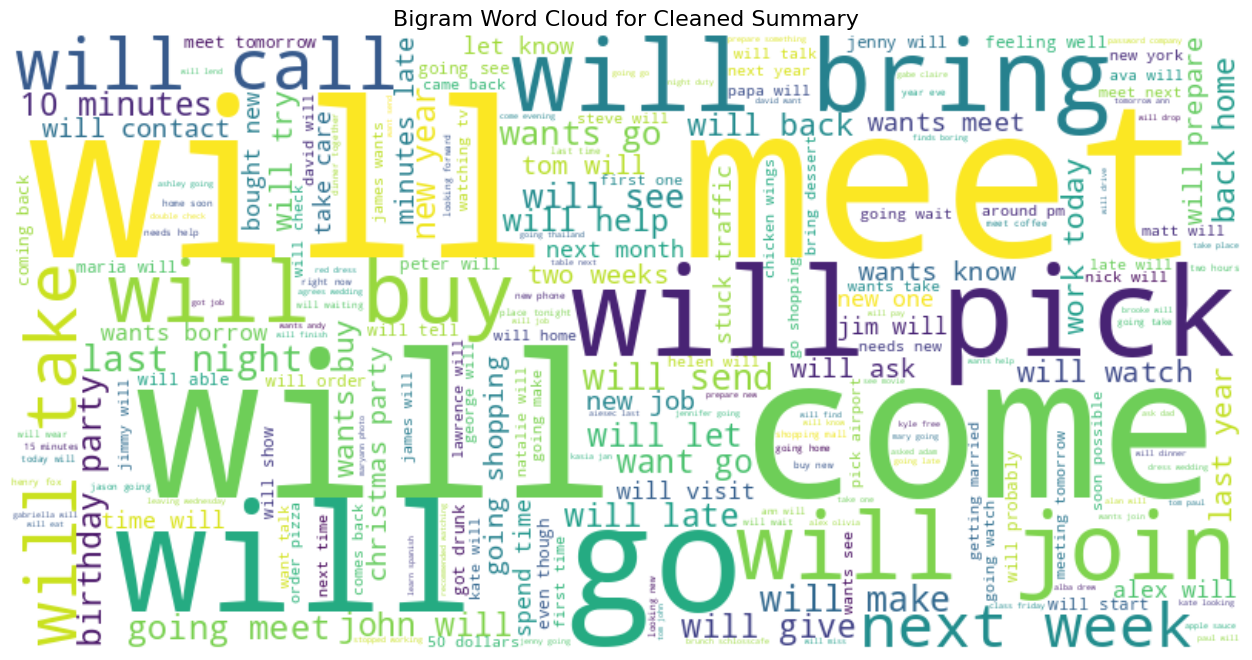

In [ ]:
# Combine all cleaned dialogues into a single string
all_dialogues = " ".join(df["cleaned_summary"])

# Define stopwords (convert to list)
stopwords_list = list(STOPWORDS)

# Use CountVectorizer to extract bigrams
vectorizer = CountVectorizer(ngram_range=(2, 2), stop_words=stopwords_list)
X = vectorizer.fit_transform([all_dialogues])
bigram_freq = X.toarray().sum(axis=0)

# Create a DataFrame of bigrams and their frequencies
bigram_freq_df = pd.DataFrame(bigram_freq, index=vectorizer.get_feature_names_out(), columns=["frequency"])

# Sort bigrams by frequency
bigram_freq_df = bigram_freq_df.sort_values(by="frequency", ascending=False)

# Select the top 200 bigrams for the word cloud
top_bigrams = bigram_freq_df.head(200)

# Generate the bigram word cloud
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    colormap='viridis',
    max_words=200,
    contour_width=1,
    contour_color='steelblue'
).generate_from_frequencies(top_bigrams["frequency"].to_dict())

# Plot the word cloud
plt.figure(figsize=(20, 8))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Bigram Word Cloud for Cleaned Summary", fontsize=16)
plt.show()


In [ ]:
from transformers import pipeline

# Load pre-trained BART model for summarization
summarizer = pipeline("summarization", model="facebook/bart-large-cnn")

config.json:   0%|          | 0.00/1.58k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/363 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Device set to use cuda:0


In [ ]:
# Example dialogue
dialogue = df['cleaned_dialogue'][0]

dialogue

'amanda I bake cookie do you want some jerry sure amanda I will bring you tomorrow'

In [ ]:
summary = summarizer(dialogue, max_length=50, min_length=25, do_sample=False)

summary[0]['summary_text']

Your max_length is set to 50, but your input_length is only 21. Since this is a summarization task, where outputs shorter than the input are typically wanted, you might consider decreasing max_length manually, e.g. summarizer('...', max_length=10)


'Amanda: I bake cookie do you want some jerry sure amanda I will bring you tomorrow. amanda: Will you bring me a cookie tomorrow? Amanda: Would you like a cookie?'

In [ ]:
print("Predicted Summary", summary[0]['summary_text'] )
print("---------------------------------")
print("Actual Summary", df['cleaned_summary'][0])

Predicted Summary Amanda: I bake cookie do you want some jerry sure amanda I will bring you tomorrow. amanda: Will you bring me a cookie tomorrow? Amanda: Would you like a cookie?
---------------------------------
Actual Summary Amanda baked cookies and will bring Jerry some tomorrow.


In [ ]:
# Generate summary
summary = summarizer(dialogue, max_length=50, min_length=25, do_sample=False)
print("Predicted Summary", summary[0]['summary_text'] )
print("---------------------------------")
print("Actual Summary", df['cleaned_summary'])

Your max_length is set to 50, but your input_length is only 21. Since this is a summarization task, where outputs shorter than the input are typically wanted, you might consider decreasing max_length manually, e.g. summarizer('...', max_length=10)


Predicted Summary Amanda: I bake cookie do you want some jerry sure amanda I will bring you tomorrow. amanda: Will you bring me a cookie tomorrow? Amanda: Would you like a cookie?
---------------------------------
Actual Summary 0      Amanda baked cookies and will bring Jerry some...
1      Olivia and Olivier are voting for liberals in ...
2      Kim may try the pomodoro technique recommended...
3      Edward thinks he is in love with Bella. Rachel...
4      Sam is confused, because he overheard Rick com...
                             ...                        
995    Brad is visiting his parents today and cannot ...
996             Kitty will convey money to Barb and Ken.
997    Max will be late because he is having a drink ...
998    Karolina will be back in Warsaw this weekend t...
999            Paula is submitting her thesis this week.
Name: cleaned_summary, Length: 1000, dtype: object


In [ ]:
!pip install datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.2/491.2 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.9/183.9 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.5/143.5 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.8/194.8 kB 18.5 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.3.0
    Uninstalling fsspec-2025.3.0:
      Successfully uninstalled fsspec-2025.3.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.6.0+cu124 requires nvidia-cublas-cu12==12.4.5.8; platform_system == "Linux" and platform_machine == "x86_64", but you have nvidia-cublas-cu12 12.5.3.2 which is incompatible.
torch 2.6.0+cu124 requires nvidia-cuda-cupti-cu12==12.4.127; platform_system 

In [ ]:
from transformers import BartForConditionalGeneration, BartTokenizer, Trainer, TrainingArguments
from datasets import Dataset, DatasetDict
import torch

# Check if GPU is available
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Load the pre-trained BART model and tokenizer
model = BartForConditionalGeneration.from_pretrained("facebook/bart-large-cnn").to(device)
tokenizer = BartTokenizer.from_pretrained("facebook/bart-large-cnn")

# Prepare your dataset
data = {
    'input_text': df['cleaned_dialogue'].tolist(),
    'output_text': df['cleaned_summary'].tolist()
}
train_dataset = Dataset.from_dict(data)

# Example split: 80% train, 20% eval
split_datasets = train_dataset.train_test_split(test_size=0.2)

# Tokenize the dataset
def tokenize_function(examples):
    model_inputs = tokenizer(examples['input_text'], max_length=1024, truncation=True, padding="max_length")
    labels = tokenizer(examples['output_text'], max_length=150, truncation=True, padding="max_length")
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

# Apply tokenization to both train and eval datasets
tokenized_datasets = {
    "train": split_datasets["train"].map(tokenize_function, batched=True),
    "eval": split_datasets["test"].map(tokenize_function, batched=True)
}

# Define training arguments with GPU support
training_args = TrainingArguments(
    output_dir='./results',          # output directory
    evaluation_strategy="epoch",     # evaluation strategy
    learning_rate=2e-5,              # learning rate
    per_device_train_batch_size=4,   # batch size for training
    per_device_eval_batch_size=8,    # batch size for evaluation
    num_train_epochs=3,              # number of training epochs
    weight_decay=0.01,               # strength of weight decay
    fp16=True,                       # enable mixed precision training for GPU
    save_strategy="no",           # save checkpoints every epoch
    logging_dir='./logs',            # directory for logging
)

# Initialize the Trainer
trainer = Trainer(
    model=model,                              # the instantiated 🤗 Transformers model
    args=training_args,                       # training arguments, defined above
    train_dataset=tokenized_datasets["train"], # tokenized training dataset
    eval_dataset=tokenized_datasets["eval"],   # tokenized evaluation dataset
)

# Train the model
trainer.train()

Using device: cuda


Map:   0%|          | 0/800 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

wandb: WARNING The `run_name` is currently set to the same value as `TrainingArguments.output_dir`. If this was not intended, please specify a different run name by setting the `TrainingArguments.run_name` parameter.
wandb: Using wandb-core as the SDK backend.  Please refer to https://wandb.me/wandb-core for more information.


<IPython.core.display.Javascript object>

wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize
wandb: Paste an API key from your profile and hit enter:

 ··········


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: kulalranjani21 (kulalranjani21-nmam-institute-of-technology) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Epoch,Training Loss,Validation Loss
1,No log,0.328085
2,No log,0.328901
3,0.562700,0.346888


TrainOutput(global_step=600, training_loss=0.49356573740641274, metrics={'train_runtime': 508.6072, 'train_samples_per_second': 4.719, 'train_steps_per_second': 1.18, 'total_flos': 5201051045068800.0, 'train_loss': 0.49356573740641274, 'epoch': 3.0})

In [ ]:
model.save_pretrained("./bart_summary_model")
tokenizer.save_pretrained("./bart_summary_model")
print("Model saved!")

Model saved!


In [ ]:
pip install rouge_score

  Preparing metadata (setup.py) ... done
  Created wheel for rouge_score: filename=rouge_score-0.1.2-py3-none-any.whl size=24935 sha256=ed53b5ce04162554dfa8ab3df29e9a1a74b0fd613f66fa9c959ac8b72e448627
  Stored in directory: /root/.cache/pip/wheels/1e/19/43/8a442dc83660ca25e163e1bd1f89919284ab0d0c1475475148
Successfully built rouge_score


In [ ]:
!pip install evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.0/84.0 kB 3.1 MB/s eta 0:00:00


In [ ]:
import evaluate

rouge = evaluate.load("rouge")

# Generate predictions for the test set
generated_summaries = []
reference_summaries = []

for example in tokenized_datasets['eval']:
    input_text = tokenizer.decode(example['input_ids'], skip_special_tokens=True)
    reference_summary = tokenizer.decode(example['labels'], skip_special_tokens=True)

    # Generate summary
    inputs = tokenizer(input_text, max_length=1024, truncation=True, return_tensors="pt").to(device)
    summary_ids = model.generate(inputs["input_ids"], max_length=150, min_length=30, num_beams=4)
    generated_summary = tokenizer.decode(summary_ids[0], skip_special_tokens=True)

    # Store generated and reference summaries
    generated_summaries.append(generated_summary)
    reference_summaries.append(reference_summary)

# Compute ROUGE scores
results = rouge.compute(predictions=generated_summaries, references=reference_summaries)

# Display ROUGE scores
print("ROUGE Scores:")
for key, value in results.items():
    print(f"{key}: {value}")

ROUGE Scores:
rouge1: 0.4507944067618128
rouge2: 0.20158732797642798
rougeL: 0.34660477076040686
rougeLsum: 0.34590904561485303


In [ ]:
from transformers import BartForConditionalGeneration, BartTokenizer
import torch

# Check if GPU is available
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Load the fine-tuned BART model and tokenizer
model = BartForConditionalGeneration.from_pretrained("./bart_summary_model").to(device)
tokenizer = BartTokenizer.from_pretrained("./bart_summary_model")

Using device: cuda


In [ ]:
from transformers import BartForConditionalGeneration, BartTokenizer
import torch

# Device setup
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Load fine-tuned BART model and tokenizer
model = BartForConditionalGeneration.from_pretrained("./bart_summary_model").to(device)
tokenizer = BartTokenizer.from_pretrained("./bart_summary_model")

# Input dialogue
test_dialogue = (
    "Amanda: Hey Jerry, I just baked some cookies! Want to try them?\n"
    "Jerry: Oh, sure Amanda! That would be great.\n"
    "Amanda: I'll bring them to you tomorrow at the office."
)

# Tokenize the input
inputs = tokenizer(test_dialogue, max_length=1024, truncation=True, return_tensors="pt")
inputs = {key: val.to(device) for key, val in inputs.items()}
print("Tokenized Input:", tokenizer.decode(inputs["input_ids"][0], skip_special_tokens=True))

# Generate summary
summary_ids = model.generate(
    inputs["input_ids"],
    max_length=50,
    min_length=10,
    length_penalty=1.5,
    num_beams=4,
    no_repeat_ngram_size=2
)
generated_summary = tokenizer.decode(summary_ids[0], skip_special_tokens=True)

# Output
print("Generated Summary:", generated_summary)

Using device: cuda
Tokenized Input: Amanda: Hey Jerry, I just baked some cookies! Want to try them?
Jerry: Oh, sure Amanda! That would be great.
Amanda: I'll bring them to you tomorrow at the office.
Generated Summary: Amanda baked some cookies. She will bring them to Jerry tomorrow at the office.


In [ ]:
import shutil

# Path to the model directory
model_dir = 'https://drive.google.com/drive/folders/1vEU5RmH13KTGoC5W6KixDM4WRILtmVjC?usp=drive_link'

In [ ]:
new

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load training log history
log_history = trainer.state.log_history

# Convert to DataFrame
logs_df = pd.DataFrame(log_history)

# Filter for loss and evaluation
train_loss = logs_df[logs_df['loss'].notnull()]
eval_loss = logs_df[logs_df['eval_loss'].notnull()]

# Plot
plt.figure(figsize=(10, 5))
plt.plot(train_loss['step'], train_loss['loss'], label="Training Loss")
plt.plot(eval_loss['step'], eval_loss['eval_loss'], label="Evaluation Loss")
plt.xlabel("Steps")
plt.ylabel("Loss")
plt.title("Training & Evaluation Loss")
plt.legend()
plt.grid()
plt.show()


In [ ]:
pegus 1

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
!pip install rouge_score

  Preparing metadata (setup.py) ... done
  Created wheel for rouge_score: filename=rouge_score-0.1.2-py3-none-any.whl size=24934 sha256=83e76132b866f375f0c90219cf239e0ec33d1b76ac6ed6eee9724187e2bdf437
  Stored in directory: /root/.cache/pip/wheels/1e/19/43/8a442dc83660ca25e163e1bd1f89919284ab0d0c1475475148
Successfully built rouge_score


In [ ]:
!pip install datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.2/491.2 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.9/183.9 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.5/143.5 kB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.8/194.8 kB 17.0 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.3.2
    Uninstalling fsspec-2025.3.2:
      Successfully uninstalled fsspec-2025.3.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.6.0+cu124 requires nvidia-cublas-cu12==12.4.5.8; platform_system == "Linux" and platform_machine == "x86_64", but you have nvidia-cublas-cu12 12.5.3.2 which is incompatible.
torch 2.6.0+cu124 requires nvidia-cuda-cupti-cu12==12.4.127; platform_system 

In [ ]:
!pip install evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.0/84.0 kB 3.4 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import missingno as msno
from wordcloud import WordCloud,STOPWORDS
import string
from datasets import load_metric, load_dataset
from sklearn.feature_extraction.text import CountVectorizer

import torch

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from tqdm import tqdm

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from transformers import pipeline
from transformers import DataCollatorForSeq2Seq
from transformers import TrainingArguments, Trainer

ImportError: cannot import name 'load_metric' from 'datasets' (/usr/local/lib/python3.11/dist-packages/datasets/__init__.py)

In [ ]:
# Instead of:
# from datasets import load_metric, load_dataset

# Import load_dataset and load_metric separately
from datasets import load_dataset
from evaluate import load # Load load from evaluate

#Now, instead of using load_metric, you should use load:

metric = load("rouge") # Example usage

In [ ]:
import nltk # Import the nltk library
nltk.download('stopwords')
stopwords = set(nltk.corpus.stopwords.words('english'))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
import torch # import the torch library

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [ ]:
train_ds_path = "/content/drive/MyDrive/Major Project/samsum-train.csv/samsum-train.csv"
test_ds_path = "/content/drive/MyDrive/Major Project/samsum-test.csv"
val_ds_path = "/content/drive/MyDrive/Major Project/samsum-validation.csv"

ds_name = "samsum"

In [ ]:
train_df = pd.read_csv(train_ds_path)
test_df = pd.read_csv(test_ds_path)
val_df = pd.read_csv(val_ds_path)

train_df.head()

,id,dialogue,summary
0,13818513,Amanda: I baked cookies. Do you want some?\r\...,Amanda baked cookies and will bring Jerry some...
1,13728867,Olivia: Who are you voting for in this electio...,Olivia and Olivier are voting for liberals in ...
2,13681000,"Tim: Hi, what's up?\r\nKim: Bad mood tbh, I wa...",Kim may try the pomodoro technique recommended...
3,13730747,"Edward: Rachel, I think I'm in ove with Bella....",Edward thinks he is in love with Bella. Rachel...
4,13728094,Sam: hey overheard rick say something\r\nSam:...,"Sam is confused, because he overheard Rick com..."


In [ ]:
val_df.head()

,id,dialogue,summary
0,13817023,"A: Hi Tom, are you busy tomorrow’s afternoon?\...",A will go to the animal shelter tomorrow to ge...
1,13716628,Emma: I’ve just fallen in love with this adven...,Emma and Rob love the advent calendar. Lauren ...
2,13829420,Jackie: Madison is pregnant\r\nJackie: but she...,Madison is pregnant but she doesn't want to ta...
3,13819648,Marla: <file_photo>\r\nMarla: look what I foun...,Marla found a pair of boxers under her bed.
4,13728448,Robert: Hey give me the address of this music ...,Robert wants Fred to send him the address of t...


In [ ]:
test_df.head()

,id,dialogue,summary
0,13862856,"Hannah: Hey, do you have Betty's number?\nAman...",Hannah needs Betty's number but Amanda doesn't...
1,13729565,Eric: MACHINE!\r\nRob: That's so gr8!\r\nEric:...,Eric and Rob are going to watch a stand-up on ...
2,13680171,"Lenny: Babe, can you help me with something?\r...",Lenny can't decide which trousers to buy. Bob ...
3,13729438,"Will: hey babe, what do you want for dinner to...",Emma will be home soon and she will let Will k...
4,13828600,"Ollie: Hi , are you in Warsaw\r\nJane: yes, ju...",Jane is in Warsaw. Ollie and Jane has a party....


In [ ]:
def print_shape_df(df, ds_name="df"):

    print(f"{ds_name} dataset has {df.shape[0]} rows and {df.shape[1]} columns")

print_shape_df(train_df, ds_name+" training")
print_shape_df(test_df, ds_name+" testing")
print_shape_df(val_df, ds_name+" validation")

samsum training dataset has 14732 rows and 3 columns
samsum testing dataset has 819 rows and 3 columns
samsum validation dataset has 818 rows and 3 columns


In [ ]:
def print_dfInfo(df, ds_name="df"):
    print(f"The info of {ds_name} dataset\n")
    print(df.info())

print_dfInfo(train_df, ds_name+" training")

The info of samsum training dataset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14732 entries, 0 to 14731
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        14732 non-null  object
 1   dialogue  14731 non-null  object
 2   summary   14732 non-null  object
dtypes: object(3)
memory usage: 345.4+ KB
None


In [ ]:
def check_null(df, ds_name='df'):
    print(f"Null Values in each col in the {ds_name} dataset:\n")
    print(df.isnull().sum())

check_null(train_df, ds_name+" training")
print()
check_null(test_df, ds_name+" testing")
print()
check_null(val_df, ds_name+" validation")

Null Values in each col in the samsum training dataset:

id          0
dialogue    1
summary     0
dtype: int64

Null Values in each col in the samsum testing dataset:

id          0
dialogue    0
summary     0
dtype: int64

Null Values in each col in the samsum validation dataset:

id          0
dialogue    0
summary     0
dtype: int64


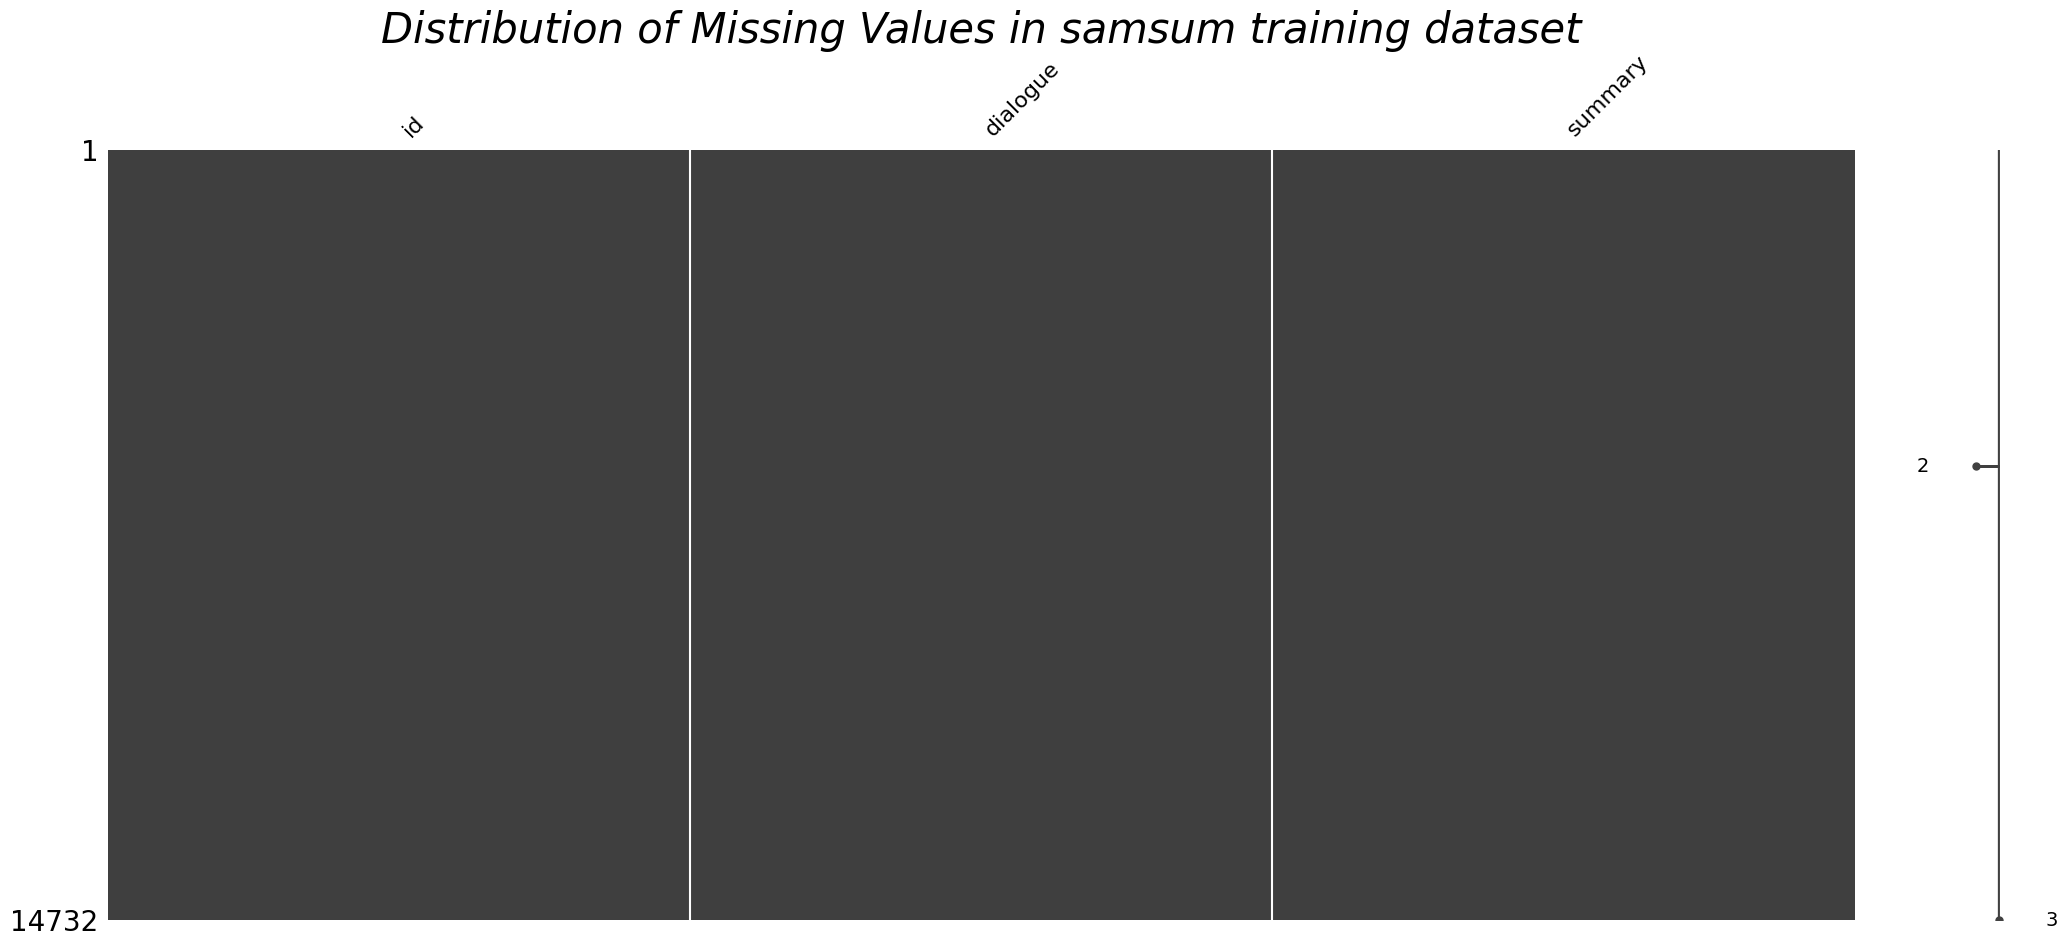

In [ ]:
def plot_miss_vals(df, ds_name="df"):
    msno.matrix(df)
    plt.title(f'Distribution of Missing Values in {ds_name} dataset', fontsize=30, fontstyle='oblique')
    plt.show()

plot_miss_vals(train_df, ds_name+" training")

In [ ]:
train_df.dtypes

,0
id,object
dialogue,object
summary,object


In [ ]:
train_df['dialogue'] = train_df['dialogue'].astype('str')

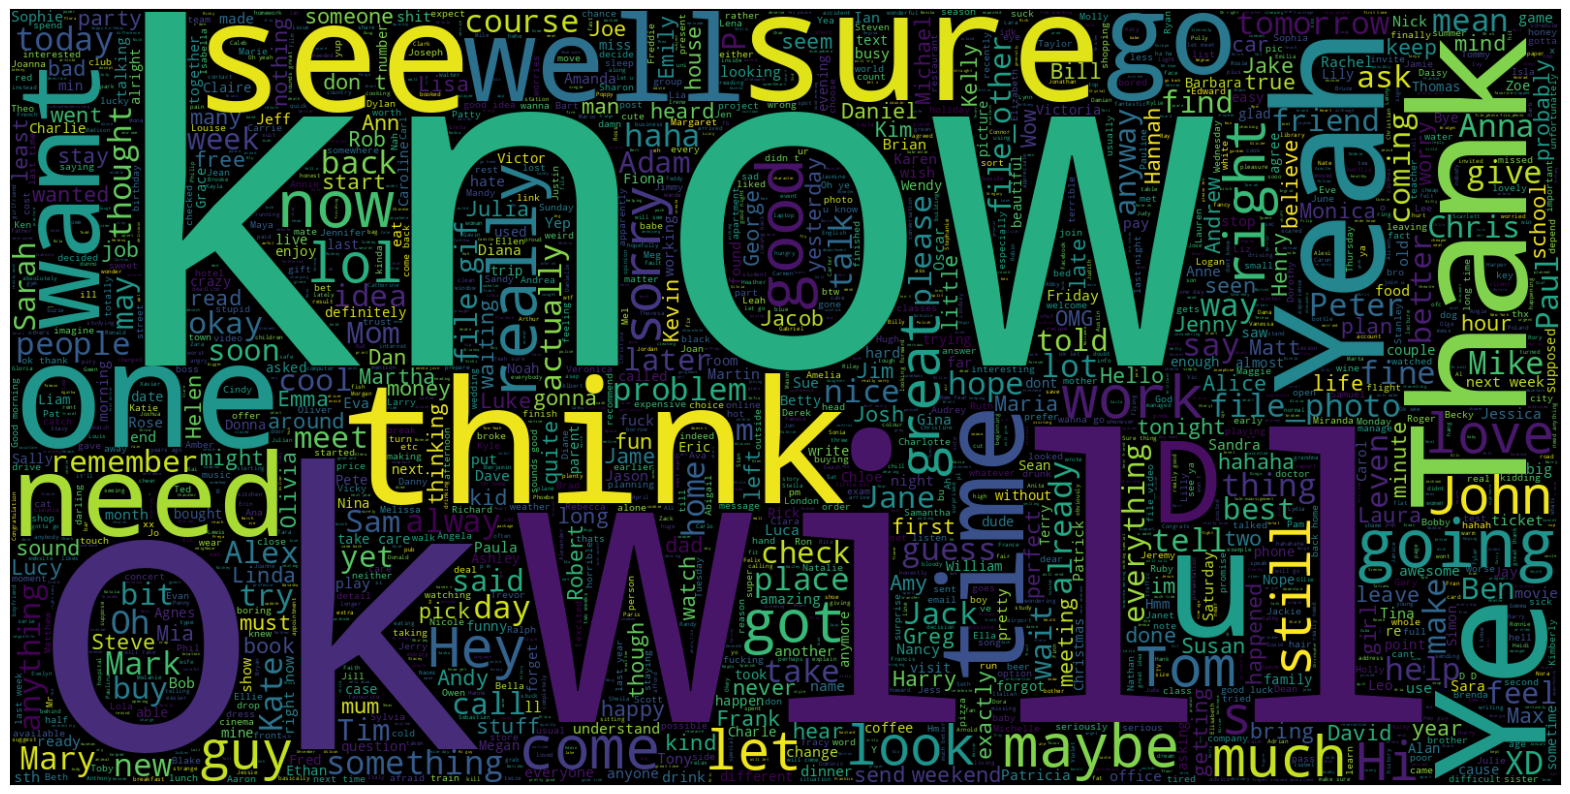

In [ ]:
plt.figure(figsize=(20, 20))
wc = WordCloud(max_words=2000, width=1600, height=800, stopwords=STOPWORDS).generate(' '.join(train_df['dialogue']))
plt.imshow(wc, interpolation='bilinear')
plt.xticks([])
plt.yticks([])
plt.show()

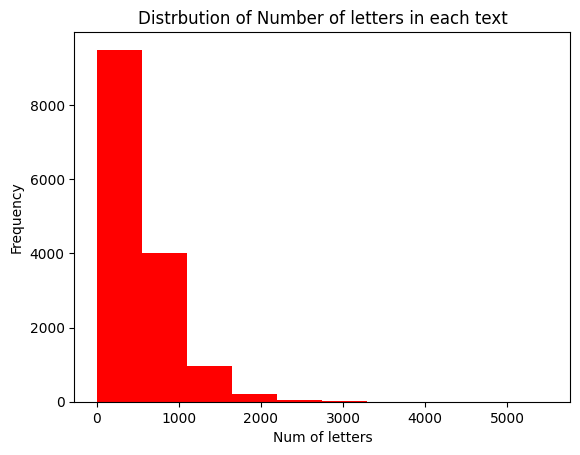

In [ ]:
letters_len=train_df['dialogue'].str.len()
plt.hist(letters_len,color='red')
plt.title("Distrbution of Number of letters in each text")
plt.xlabel("Num of letters")
plt.ylabel("Frequency")
plt.show()

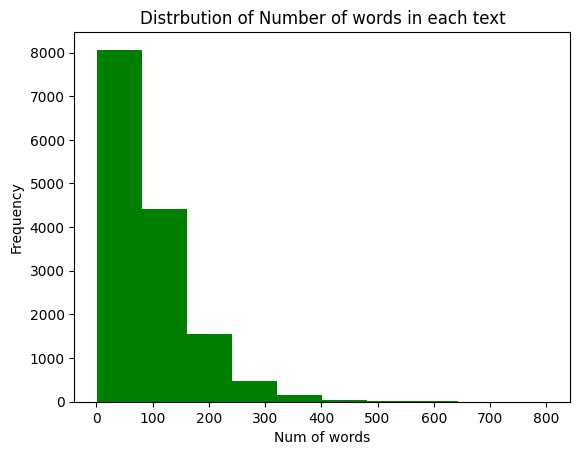

In [ ]:
words_len=train_df['dialogue'].str.split().map(lambda x: len(x))
plt.hist(words_len,color='green')
plt.title("Distrbution of Number of words in each text")
plt.xlabel("Num of words")
plt.ylabel("Frequency")
plt.show()

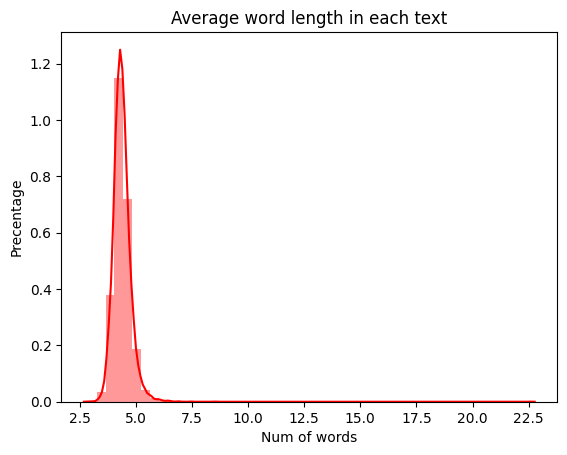

In [ ]:
word=train_df['dialogue'].str.split().apply(lambda x : [len(i) for i in x])
word = word.map(lambda x: np.mean(x))
sns.distplot(word,color='red')
plt.title("Average word length in each text")
plt.xlabel("Num of words")
plt.ylabel("Precentage")
plt.show()

In [ ]:
data = train_df['dialogue'].values.tolist()

In [ ]:
import nltk
import string
from nltk.tokenize import word_tokenize # import word_tokenize
from nltk.corpus import stopwords

# Download 'punkt_tab' for sentence tokenization
nltk.download('punkt_tab')  # Download the missing data package
nltk.download('punkt') # Download necessary resources
nltk.download('stopwords')

data = train_df['dialogue'].values.tolist()
new_data = []

for sentence in data:
    word_tokens = word_tokenize(sentence)
    # Convert stopwords to a set for faster lookup
    stopwords_set = set(stopwords.words('english'))
    filtered_sentence = [w for w in word_tokens if not w.lower() in stopwords_set]
    sen = ' '.join(filtered_sentence)
    table = str.maketrans("", "", string.punctuation)
    new_s = sen.translate(table)

    new_data.append(new_s)

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
new_data = []

for sentence in data:

    word_tokens = word_tokenize(sentence)
    filtered_sentence = [w for w in word_tokens if not w.lower() in stopwords]
    sen = ' '.join(filtered_sentence)
    table = str.maketrans("", "", string.punctuation)
    new_s = sen.translate(table)

    new_data.append(new_s)

TypeError: argument of type 'WordListCorpusReader' is not iterable

In [ ]:
new_s

'Georgia  ready hotel hunting  need book something finally Lisbon Juliette  sure go  show found Georgia   filephoto  Juliette  nah  looks like old lady s room lol Georgia   filephoto  Juliette  s better  bed nt look comfortable Georgia  kind like s really close city center Juliette  show others please Georgia   filephoto  Juliette  nah  one sucks  look horrible curtains Georgia  aff Julie princess Juliette  want comfortable Georgia  come  stop whining know budget Juliette  well hopefully find something s decent right  Georgia  show decent want Marriott something   Juliette  ok ok nt get angry Georgia  need decide today  longer wait higher prices get Juliette  ok get second one  Georgia  ok give second Juliette  sure Georgia  affff someone already booked   Juliette  oh god  s bullshit Georgia  whatever  go third one  looks nice overall maybe changed curtains already Juliette  ok  fine Georgia  done  booked   Juliette  perfect    ca nt wait go    Georgia  know  best time Juliette  time l

In [ ]:
def get_corpus(series):
    words = []
    for text in series:
        for word in text.split():
            words.append(word.strip())
    return words

corpus = get_corpus(new_data)
corpus[:5]

[]

In [ ]:
print(f"dataset contains {len(corpus)} words")

dataset contains 0 words


In [ ]:
from collections import Counter
counter = Counter(corpus)
most_common = counter.most_common(10)
most_common = dict(most_common)
most_common

{}

In [ ]:
def get_top_text_ngrams(corpus, n,g):
    vec = CountVectorizer(ngram_range=(1, 1)).fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq =sorted(words_freq, key = lambda x: x[1], reverse=True)
    return words_freq[:n]

In [ ]:
def get_top_text_ngrams(corpus, n, g):
    # Define or import custom_stop_words here
    custom_stop_words = ['the', 'and', 'a', 'to', 'of', 'in', 'is', 'that', 'it', 'for'] # replace with your actual stop words
    # vec = CountVectorizer(ngram_range=(1, 1)).fit(corpus) # Remove this line
    vec = CountVectorizer(ngram_range=(g, g), stop_words=custom_stop_words).fit(corpus) # Add stop_words to CountVectorizer initialization
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq =sorted(words_freq, key = lambda x: x[1], reverse=True)
    return words_freq[:n]

In [ ]:
import nltk
import string
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import missingno as msno
from wordcloud import WordCloud,STOPWORDS
from collections import Counter

# Make sure to import CountVectorizer:
from sklearn.feature_extraction.text import CountVectorizer

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from tqdm import tqdm

from datasets import load_dataset
from evaluate import load

import torch

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from transformers import pipeline
from transformers import DataCollatorForSeq2Seq
from transformers import TrainingArguments, Trainer

# ... (rest of the code remains the same) ...

In [ ]:
plt.figure(figsize = (16,9))
most_common_uni = get_top_text_ngrams(new_data,10,1)
most_common_uni = dict(most_common_uni)
sns.barplot(x=list(most_common_uni.values()),y=list(most_common_uni.keys()));

ValueError: empty vocabulary; perhaps the documents only contain stop words

<Figure size 1600x900 with 0 Axes>

In [ ]:
def get_top_text_ngrams(corpus, n, g):
    # Refine custom_stop_words if it's too aggressive
    # Retain only the essential stop words that you want to remove
    # For example:
    custom_stop_words = ['the', 'and', 'a', 'to', 'of', 'in', 'is']
    vec = CountVectorizer(ngram_range=(g, g), stop_words=custom_stop_words).fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq =sorted(words_freq, key = lambda x: x[1], reverse=True)
    return words_freq[:n]

In [ ]:
def get_top_text_ngrams(corpus, n, g):
    # 1. Convert custom_stop_words to a list:
    custom_stop_words = list(custom_stop_words)
    vec = CountVectorizer(ngram_range=(g, g), stop_words=custom_stop_words).fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq =sorted(words_freq, key = lambda x: x[1], reverse=True)
    return words_freq[:n]

In [ ]:
import nltk
import string
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import missingno as msno
from wordcloud import WordCloud,STOPWORDS
from collections import Counter

# Make sure to import CountVectorizer:
from sklearn.feature_extraction.text import CountVectorizer

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from tqdm import tqdm

from datasets import load_dataset
from evaluate import load

import torch

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from transformers import pipeline
from transformers import DataCollatorForSeq2Seq
from transformers import TrainingArguments, Trainer


def get_top_text_ngrams(corpus, n, g):
    # 1. Customize stop words:
    custom_stop_words = set(stopwords.words('english'))  # Start with NLTK's stop words

    # Add or remove words as needed:
    # custom_stop_words.add("your_word")
    # custom_stop_words.remove("word_to_keep")

    # 2. Pass stop words to CountVectorizer:
    vec = CountVectorizer(ngram_range=(g, g), stop_words=custom_stop_words).fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    return words_freq[:n]

In [ ]:
import nltk
import string
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import missingno as msno
from wordcloud import WordCloud,STOPWORDS
from collections import Counter

# Make sure to import CountVectorizer:
from sklearn.feature_extraction.text import CountVectorizer

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from tqdm import tqdm

from datasets import load_dataset
from evaluate import load

import torch

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from transformers import pipeline
from transformers import DataCollatorForSeq2Seq
from transformers import TrainingArguments, Trainer


def get_top_text_ngrams(corpus, n, g):
    # 1. Customize stop words:
    custom_stop_words = set(stopwords.words('english'))  # Start with NLTK's stop words

    # Add or remove words as needed:
    # custom_stop_words.add("your_word")
    # custom_stop_words.remove("word_to_keep")

    # 2. Pass stop words to CountVectorizer:
    vec = CountVectorizer(ngram_range=(g, g), stop_words=custom_stop_words).fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    return words_freq[:n]

In [ ]:
X = list(train_df['dialogue'])
X[:5]

["Amanda: I baked  cookies. Do you want some?\r\nJerry: Sure!\r\nAmanda: I'll bring you tomorrow :-)",
 'Olivia: Who are you voting for in this election? \r\nOliver: Liberals as always.\r\nOlivia: Me too!!\r\nOliver: Great',
 "Tim: Hi, what's up?\r\nKim: Bad mood tbh, I was going to do lots of stuff but ended up procrastinating\r\nTim: What did you plan on doing?\r\nKim: Oh you know, uni stuff and unfucking my room\r\nKim: Maybe tomorrow I'll move my ass and do everything\r\nKim: We were going to defrost a fridge so instead of shopping I'll eat some defrosted veggies\r\nTim: For doing stuff I recommend Pomodoro technique where u use breaks for doing chores\r\nTim: It really helps\r\nKim: thanks, maybe I'll do that\r\nTim: I also like using post-its in kaban style",
 "Edward: Rachel, I think I'm in ove with Bella..\r\nrachel: Dont say anything else..\r\nEdward: What do you mean??\r\nrachel: Open your fu**ing door.. I'm outside",
 "Sam: hey  overheard rick say something\r\nSam: i don't k

In [ ]:
model_name = "google/pegasus-cnn_dailymail"
tokenizer = AutoTokenizer.from_pretrained(model_name)

tokenizer_config.json:   0%|          | 0.00/88.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/1.91M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/65.0 [00:00<?, ?B/s]

In [ ]:
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

pytorch_model.bin:   0%|          | 0.00/2.28G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.28G [00:00<?, ?B/s]

Some weights of PegasusForConditionalGeneration were not initialized from the model checkpoint at google/pegasus-cnn_dailymail and are newly initialized: ['model.decoder.embed_positions.weight', 'model.encoder.embed_positions.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


generation_config.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

In [ ]:
pipe = pipeline('summarization', model = model_name )

pipe_out = pipe(test_df['dialogue'][1])

print(pipe_out)

Some weights of PegasusForConditionalGeneration were not initialized from the model checkpoint at google/pegasus-cnn_dailymail and are newly initialized: ['model.decoder.embed_positions.weight', 'model.encoder.embed_positions.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Device set to use cuda:0


[{'summary_text': "Eric: Machine! Rob: Machine! Eric: Machine! Rob: TTYL?<n>Rob: Sure!<n>Eric: Gr8! I'll watch them now!<n>Rob: Me too! Eric: Machine! Rob: Machine! Eric: TTYL?"}]


In [ ]:
print(f"original summary:\n{test_df['summary'][1]}\n")
print("Predicted Summary:")
print(pipe_out[0]['summary_text'].replace(" .<n>", ".\n"))

original summary:
Eric and Rob are going to watch a stand-up on youtube.

Predicted Summary:
Eric: Machine! Rob: Machine! Eric: Machine! Rob: TTYL?<n>Rob: Sure!<n>Eric: Gr8! I'll watch them now!<n>Rob: Me too! Eric: Machine! Rob: Machine! Eric: TTYL?


In [ ]:
def generate_batch_sized_chunks(list_of_elements, batch_size):
    """split the dataset into smaller batches that we can process simultaneously
    Yield successive batch-sized chunks from list_of_elements."""
    for i in range(0, len(list_of_elements), batch_size):
        yield list_of_elements[i : i + batch_size]

In [ ]:
def calculate_metric_on_test_ds(dataset, metric, model, tokenizer,
                               batch_size=16, device=device,
                               column_text="article",
                               column_summary="highlights"):
    article_batches = list(generate_batch_sized_chunks(dataset[column_text].values.tolist(), batch_size))
    target_batches = list(generate_batch_sized_chunks(dataset[column_summary].values.tolist(), batch_size))

    for article_batch, target_batch in tqdm(
        zip(article_batches, target_batches), total=len(article_batches)):

        inputs = tokenizer(article_batch, max_length=1024,  truncation=True,
                        padding="max_length", return_tensors="pt")

        summaries = model.generate(input_ids=inputs["input_ids"].to(device),
                         attention_mask=inputs["attention_mask"].to(device),
                         length_penalty=0.8, num_beams=8, max_length=128)
        ''' parameter for length penalty ensures that the model does not generate sequences that are too long. '''

        # Finally, we decode the generated texts,
        # replace the  token, and add the decoded texts with the references to the metric.
        decoded_summaries = [tokenizer.decode(s, skip_special_tokens=True,
                                clean_up_tokenization_spaces=True)
               for s in summaries]

        decoded_summaries = [d.replace("", " ") for d in decoded_summaries]


        metric.add_batch(predictions=decoded_summaries, references=target_batch)

    #  Finally compute and return the ROUGE scores.
    score = metric.compute()
    return score

In [ ]:
test_df

,id,dialogue,summary
0,13862856,"Hannah: Hey, do you have Betty's number?\nAman...",Hannah needs Betty's number but Amanda doesn't...
1,13729565,Eric: MACHINE!\r\nRob: That's so gr8!\r\nEric:...,Eric and Rob are going to watch a stand-up on ...
2,13680171,"Lenny: Babe, can you help me with something?\r...",Lenny can't decide which trousers to buy. Bob ...
3,13729438,"Will: hey babe, what do you want for dinner to...",Emma will be home soon and she will let Will k...
4,13828600,"Ollie: Hi , are you in Warsaw\r\nJane: yes, ju...",Jane is in Warsaw. Ollie and Jane has a party....
...,...,...,...
814,13611902-1,Alex: Were you able to attend Friday night's b...,Benjamin didn't come to see a basketball game ...
815,13820989,Jamilla: remember that the audition starts at ...,The audition starts at 7.30 P.M. in Antena 3.
816,13717193,"Marta: <file_gif>\r\nMarta: Sorry girls, I cli...","Marta sent a file accidentally,"
817,13829115,Cora: Have you heard how much fuss British med...,There was a meet-and-greet with James Charles ...


In [ ]:
!pip install rouge_score

In [ ]:
from evaluate import load # Change load_metric to load here

rouge_metric = load('rouge')
rouge_metric

EvaluationModule(name: "rouge", module_type: "metric", features: [{'predictions': Value(dtype='string', id='sequence'), 'references': Sequence(feature=Value(dtype='string', id='sequence'), length=-1, id=None)}, {'predictions': Value(dtype='string', id='sequence'), 'references': Value(dtype='string', id='sequence')}], usage: """
Calculates average rouge scores for a list of hypotheses and references
Args:
    predictions: list of predictions to score. Each prediction
        should be a string with tokens separated by spaces.
    references: list of reference for each prediction. Each
        reference should be a string with tokens separated by spaces.
    rouge_types: A list of rouge types to calculate.
        Valid names:
        `"rouge{n}"` (e.g. `"rouge1"`, `"rouge2"`) where: {n} is the n-gram based scoring,
        `"rougeL"`: Longest common subsequence based scoring.
        `"rougeLsum"`: rougeLsum splits text using `"
"`.
        See details in https://github.com/huggingface/

In [ ]:
!pip install py7zr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.9/67.9 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 60.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.2/96.2 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.6/50.6 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 80.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.3/141.3 kB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 413.7/413.7 kB 34.7 MB/s eta 0:00:00


In [ ]:
train_data = train_df['dialogue'].values.tolist()
train_data[:2]

["Amanda: I baked  cookies. Do you want some?\r\nJerry: Sure!\r\nAmanda: I'll bring you tomorrow :-)",
 'Olivia: Who are you voting for in this election? \r\nOliver: Liberals as always.\r\nOlivia: Me too!!\r\nOliver: Great']

In [ ]:
valid_data = val_df['dialogue'].values.tolist()
valid_data[:2]

["A: Hi Tom, are you busy tomorrow’s afternoon?\r\nB: I’m pretty sure I am. What’s up?\r\nA: Can you go with me to the animal shelter?.\r\nB: What do you want to do?\r\nA: I want to get a puppy for my son.\r\nB: That will make him so happy.\r\nA: Yeah, we’ve discussed it many times. I think he’s ready now.\r\nB: That’s good. Raising a dog is a tough issue. Like having a baby ;-) \r\nA: I'll get him one of those little dogs.\r\nB: One that won't grow up too big;-)\r\nA: And eat too much;-))\r\nB: Do you know which one he would like?\r\nA: Oh, yes, I took him there last Monday. He showed me one that he really liked.\r\nB: I bet you had to drag him away.\r\nA: He wanted to take it home right away ;-).\r\nB: I wonder what he'll name it.\r\nA: He said he’d name it after his dead hamster – Lemmy  - he's  a great Motorhead fan :-)))",
 'Emma: I’ve just fallen in love with this advent calendar! Awesome! I wanna one for my kids!\r\nRob: I used to get one every year as a child! Loved them! \r\nE

In [ ]:
test_data = test_df['dialogue'].values.tolist()
test_data[:2]

["Hannah: Hey, do you have Betty's number?\nAmanda: Lemme check\nHannah: <file_gif>\nAmanda: Sorry, can't find it.\nAmanda: Ask Larry\nAmanda: He called her last time we were at the park together\nHannah: I don't know him well\nHannah: <file_gif>\nAmanda: Don't be shy, he's very nice\nHannah: If you say so..\nHannah: I'd rather you texted him\nAmanda: Just text him 🙂\nHannah: Urgh.. Alright\nHannah: Bye\nAmanda: Bye bye",
 "Eric: MACHINE!\r\nRob: That's so gr8!\r\nEric: I know! And shows how Americans see Russian ;)\r\nRob: And it's really funny!\r\nEric: I know! I especially like the train part!\r\nRob: Hahaha! No one talks to the machine like that!\r\nEric: Is this his only stand-up?\r\nRob: Idk. I'll check.\r\nEric: Sure.\r\nRob: Turns out no! There are some of his stand-ups on youtube.\r\nEric: Gr8! I'll watch them now!\r\nRob: Me too!\r\nEric: MACHINE!\r\nRob: MACHINE!\r\nEric: TTYL?\r\nRob: Sure :)"]

In [ ]:
train_summary = train_df['summary'].values.tolist()
valid_summary = val_df['summary'].values.tolist()
test_summary = test_df['summary'].values.tolist()

In [ ]:
train_summary[:2]

['Amanda baked cookies and will bring Jerry some tomorrow.',
 'Olivia and Olivier are voting for liberals in this election. ']

In [ ]:
valid_summary[:2]

['A will go to the animal shelter tomorrow to get a puppy for her son. They already visited the shelter last Monday and the son chose the puppy. ',
 'Emma and Rob love the advent calendar. Lauren fits inside calendar various items, for instance, small toys and Christmas decorations. Her children are excited whenever they get the calendar.']

In [ ]:
test_summary[:2]

["Hannah needs Betty's number but Amanda doesn't have it. She needs to contact Larry.",
 'Eric and Rob are going to watch a stand-up on youtube.']

In [ ]:
def convert_examples_to_features(data, summary):
    input_encodings = tokenizer(data , max_length = 1024, truncation = True )

    with tokenizer.as_target_tokenizer():
        target_encodings = tokenizer(summary, max_length = 128, truncation = True )

    return {
        'input_ids' : input_encodings['input_ids'],
        'attention_mask': input_encodings['attention_mask'],
        'labels': target_encodings['input_ids']
    }

In [ ]:
train_encodings = convert_examples_to_features(train_data, train_summary)
val_encodings = convert_examples_to_features(valid_data, valid_summary)
test_encodings = convert_examples_to_features(test_data, test_summary)

In [ ]:
train_encodings['input_ids'][0]

[12195,
 151,
 125,
 7091,
 3659,
 107,
 842,
 119,
 245,
 181,
 152,
 10508,
 151,
 7435,
 147,
 12195,
 151,
 125,
 131,
 267,
 650,
 119,
 3469,
 29344,
 1]

In [ ]:
train_encodings['attention_mask'][0]

[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

In [ ]:
train_encodings['labels'][0]

[12195, 7091, 3659, 111, 138, 650, 10508, 181, 3469, 107, 1]

In [ ]:
def data_transform(encode):

    l = []
    for i,j,k in zip(encode['input_ids'], encode['attention_mask'], encode['labels']):
        dic = {
            'input_ids': i,
            'attention_mask': j,
            'labels': k
        }
        l.append(dic)

    return l

train_encodings = data_transform(train_encodings)
val_encodings = data_transform(val_encodings)
test_encodings = data_transform(test_encodings)

In [ ]:
seq2seq_data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

In [ ]:
trainer_args = TrainingArguments(
    output_dir='pegasus-samsum',
    num_train_epochs=0.5,
    warmup_steps=500,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    weight_decay=0.01,
    logging_steps=10,
    evaluation_strategy='steps',
    eval_steps=500,
    save_steps=500,
    gradient_accumulation_steps=64
)

In [ ]:
trainer_args = TrainingArguments(
    output_dir='pegasus-samsum',
    num_train_epochs=0.5,
    warmup_steps=500,
    per_device_train_batch_size=1,  # Keep this as 1
    per_device_eval_batch_size=1,  # Keep this as 1
    weight_decay=0.01,
    logging_steps=10,
    evaluation_strategy='steps',
    eval_steps=500,
    save_steps=500,
    gradient_accumulation_steps=16,  # Reduced from 64
    gradient_checkpointing=True,     # Enable gradient checkpointing
    fp16=True                       # Enable mixed precision training
)

In [ ]:
trainer = Trainer(model=model,
                  args=trainer_args,
                  tokenizer=tokenizer,
                  data_collator=seq2seq_data_collator,
                  train_dataset=train_encodings,
                  eval_dataset=val_encodings)

In [ ]:
trainer.train()

wandb: WARNING The `run_name` is currently set to the same value as `TrainingArguments.output_dir`. If this was not intended, please specify a different run name by setting the `TrainingArguments.run_name` parameter.
wandb: Using wandb-core as the SDK backend.  Please refer to https://wandb.me/wandb-core for more information.


<IPython.core.display.Javascript object>

wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize
wandb: Paste an API key from your profile and hit enter:wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: kulalranjani21 (kulalranjani21-nmam-institute-of-technology) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Step,Training Loss,Validation Loss


Step,Training Loss,Validation Loss


TrainOutput(global_step=460, training_loss=2.0617029646168583, metrics={'train_runtime': 2258.5588, 'train_samples_per_second': 3.261, 'train_steps_per_second': 0.204, 'total_flos': 2744263183908864.0, 'train_loss': 2.0617029646168583, 'epoch': 0.4995927233233777})

In [ ]:
score = calculate_metric_on_test_ds(
    test_df, rouge_metric, trainer.model, tokenizer, batch_size = 2, column_text = 'dialogue', column_summary= 'summary'
)

 85%|████████▌ | 349/410 [32:45<07:11,  7.08s/it]

In [ ]:
rouge_names = ["rouge1", "rouge2", "rougeL", "rougeLsum"]
rouge_dict = dict((rn, score[rn].mid.fmeasure ) for rn in rouge_names )

pd.DataFrame(rouge_dict, index = [f'pegasus'] )

In [ ]:
# In ipython-input-78-089364cf2b71
# Instead of:
# score = calculate_metric_on_test_ds(
#     test_df, rouge_metric, trainer.model, tokenizer, batch_size = 2, column_text = 'dialogue', column_summary= 'summary'
# )

# Use this:
score = calculate_metric_on_test_ds(
    test_df, rouge_metric, trainer.model, tokenizer,
    batch_size=2, column_text='dialogue', column_summary='summary'
)

# Extract the fmeasure directly, accounting for potential changes in the output:
rouge_names = ["rouge1", "rouge2", "rougeL", "rougeLsum"]
rouge_dict = {rn: score[rn] if isinstance(score[rn], float) else score[rn].mid.fmeasure for rn in rouge_names}

# ... the rest of the code in ipython-input-79-089364cf2b

In [ ]:
model.save_pretrained("model")

In [ ]:
tokenizer.save_pretrained("tokenizer")

In [ ]:
tokenizer = AutoTokenizer.from_pretrained("/kaggle/working/tokenizer")

In [ ]:
model = "/kaggle/working/model"

In [ ]:
gen_kwargs = {"length_penalty": 0.8, "num_beams":8, "max_length": 128}

sumarizar = pipeline("summarization", model=model,tokenizer=tokenizer)

In [ ]:
sample_text = test_df['dialogue'][0]
orig_summ = test_df['summary'][0]
predicted_summary = sumarizar(sample_text, **gen_kwargs)[0]["summary_text"]

print("Dialogue:")
print(sample_text)


print("\nReference Summary:")
print(orig_summ)


print("\nModel Summary:")
print(predicted_summary)

In [ ]:
def summary(sentence):

    predicted_summary = sumarizar(sentence)[0]["summary_text"]
    print("The summarization of your sentence:\n")
    predicted_summary = predicted_summary.replace(' .<n>', '\n')
    print(predicted_summary)

In [ ]:
summary(test_df['dialogue'][2])

In [ ]:
pegus 2

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('https://colab.research.google.com/drive/1Jx33JUThva2cCMpP7GHvs-vO0fmZ9QPC?usp=drive_link'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [ ]:
!pip install datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.2/491.2 kB 21.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.9/183.9 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.5/143.5 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.8/194.8 kB 15.4 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.3.2
    Uninstalling fsspec-2025.3.2:
      Successfully uninstalled fsspec-2025.3.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.6.0+cu124 requires nvidia-cublas-cu12==12.4.5.8; platform_system == "Linux" and platform_machine == "x86_64", but you have nvidia-cublas-cu12 12.5.3.2 which is incompatible.
torch 2.6.0+cu124 requires nvidia-cuda-cupti-cu12==12.4.127; platform_system 

In [ ]:
from datasets import load_dataset
import torch
import matplotlib.pyplot as plt
from transformers import pipeline

In [ ]:
!pip install py7zr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.9/67.9 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 93.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.2/96.2 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.6/50.6 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 84.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.3/141.3 kB 14.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 413.7/413.7 kB 36.1 MB/s eta 0:00:00


In [ ]:
dataset_samsum = load_dataset("samsum")

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/7.04k [00:00<?, ?B/s]

samsum.py:   0%|          | 0.00/3.36k [00:00<?, ?B/s]

corpus.7z:   0%|          | 0.00/2.94M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/14732 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/819 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/818 [00:00<?, ? examples/s]

In [ ]:
dataset_samsum

DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 14732
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 819
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 818
    })
})

In [ ]:
dataset_samsum["train"][:10]

{'id': ['13818513',
  '13728867',
  '13681000',
  '13730747',
  '13728094',
  '13716343',
  '13611672',
  '13730463',
  '13809976',
  '13809912'],
 'dialogue': ["Amanda: I baked  cookies. Do you want some?\r\nJerry: Sure!\r\nAmanda: I'll bring you tomorrow :-)",
  'Olivia: Who are you voting for in this election? \r\nOliver: Liberals as always.\r\nOlivia: Me too!!\r\nOliver: Great',
  "Tim: Hi, what's up?\r\nKim: Bad mood tbh, I was going to do lots of stuff but ended up procrastinating\r\nTim: What did you plan on doing?\r\nKim: Oh you know, uni stuff and unfucking my room\r\nKim: Maybe tomorrow I'll move my ass and do everything\r\nKim: We were going to defrost a fridge so instead of shopping I'll eat some defrosted veggies\r\nTim: For doing stuff I recommend Pomodoro technique where u use breaks for doing chores\r\nTim: It really helps\r\nKim: thanks, maybe I'll do that\r\nTim: I also like using post-its in kaban style",
  "Edward: Rachel, I think I'm in ove with Bella..\r\nrachel: 

In [ ]:
split_lengths = [len(dataset_samsum[split]) for split in dataset_samsum]

In [ ]:
split_lengths

[14732, 819, 818]

In [ ]:
print(f"Split lengths: {split_lengths}")
print(f"Features: {dataset_samsum['train'].column_names}")
print("\nDialogue:")
print(dataset_samsum["test"][0]["dialogue"])
print("\nSummary:")
print(dataset_samsum["test"][0]["summary"])

Split lengths: [14732, 819, 818]
Features: ['id', 'dialogue', 'summary']

Dialogue:
Hannah: Hey, do you have Betty's number?
Amanda: Lemme check
Hannah: <file_gif>
Amanda: Sorry, can't find it.
Amanda: Ask Larry
Amanda: He called her last time we were at the park together
Hannah: I don't know him well
Hannah: <file_gif>
Amanda: Don't be shy, he's very nice
Hannah: If you say so..
Hannah: I'd rather you texted him
Amanda: Just text him 🙂
Hannah: Urgh.. Alright
Hannah: Bye
Amanda: Bye bye

Summary:
Hannah needs Betty's number but Amanda doesn't have it. She needs to contact Larry.


Evaluating PEGASUS on SAMSum

In [ ]:
pipe = pipeline("summarization", model="google/pegasus-cnn_dailymail")

config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/2.28G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.28G [00:00<?, ?B/s]

Some weights of PegasusForConditionalGeneration were not initialized from the model checkpoint at google/pegasus-cnn_dailymail and are newly initialized: ['model.decoder.embed_positions.weight', 'model.encoder.embed_positions.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


generation_config.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/88.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/1.91M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/65.0 [00:00<?, ?B/s]

Device set to use cuda:0


In [ ]:
pipe_out = pipe(dataset_samsum["test"][0]["dialogue"])
print("Summary:")
print(pipe_out[0]["summary_text"].replace(" .<n>", ".\n"))

Your max_length is set to 128, but your input_length is only 122. Since this is a summarization task, where outputs shorter than the input are typically wanted, you might consider decreasing max_length manually, e.g. summarizer('...', max_length=61)


Summary:
Amanda: Ask Larry Amanda: He called her last time we were at the park together.
Hannah: I'd rather you texted him.
Amanda: Just text him .


Fine-Tuning PEGASUS

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [ ]:
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

model_ckpt = "google/pegasus-cnn_dailymail"
tokenizer = AutoTokenizer.from_pretrained(model_ckpt)
model = AutoModelForSeq2SeqLM.from_pretrained(model_ckpt).to(device)

Some weights of PegasusForConditionalGeneration were not initialized from the model checkpoint at google/pegasus-cnn_dailymail and are newly initialized: ['model.decoder.embed_positions.weight', 'model.encoder.embed_positions.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
d_len = [len(tokenizer.encode(s)) for s in dataset_samsum["train"]["dialogue"]]
s_len = [len(tokenizer.encode(s)) for s in dataset_samsum["train"]["summary"]]

Token indices sequence length is longer than the specified maximum sequence length for this model (1044 > 1024). Running this sequence through the model will result in indexing errors


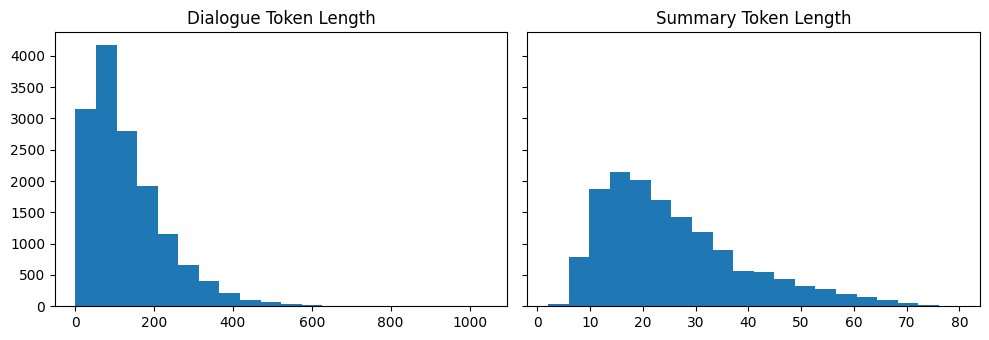

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
axes[0].hist(d_len, bins=20)
axes[0].set_title("Dialogue Token Length")
axes[1].hist(s_len, bins=20)
axes[1].set_title("Summary Token Length")
plt.tight_layout()
plt.show()

In [ ]:
tokenizer.as_target_tokenizer()

In [ ]:
#lets tokenize the dataset

def convert_examples_to_features(example_batch):
    input_encodings = tokenizer(example_batch["dialogue"], max_length=1024, truncation=True)

    with tokenizer.as_target_tokenizer():
        target_encodings = tokenizer(example_batch["summary"], max_length=128, truncation=True)

    return {
        "input_ids": input_encodings["input_ids"],
        "attention_mask": input_encodings["attention_mask"],
        "labels": target_encodings["input_ids"]
    }

In [ ]:
dataset_samsum_pt = dataset_samsum.map(convert_examples_to_features, batched=True)

Map:   0%|          | 0/14732 [00:00<?, ? examples/s]

/usr/local/lib/python3.11/dist-packages/transformers/tokenization_utils_base.py:3980: UserWarning: `as_target_tokenizer` is deprecated and will be removed in v5 of Transformers. You can tokenize your labels by using the argument `text_target` of the regular `__call__` method (either in the same call as your input texts if you use the same keyword arguments, or in a separate call.
  warnings.warn(


Map:   0%|          | 0/819 [00:00<?, ? examples/s]

Map:   0%|          | 0/818 [00:00<?, ? examples/s]

In [ ]:
columns = ["input_ids", "labels", "attention_mask"]
dataset_samsum_pt.set_format(type="torch", columns=columns)

In [ ]:
from transformers import DataCollatorForSeq2Seq

seq2seq_data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

In [ ]:
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir="pegasus-samsum",
    num_train_epochs=1,
    warmup_steps=500,
    per_device_train_batch_size=1,
    per_gpu_eval_batch_size=1,
    weight_decay=0.01,
    logging_steps=10,
    push_to_hub=True,
    evaluation_strategy="steps",
    eval_steps=500,
    save_steps=1e6,
    gradient_accumulation_steps=16,
    report_to="none",  # wandb disabled
)

/usr/local/lib/python3.11/dist-packages/transformers/training_args.py:1611: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


In [ ]:
from huggingface_hub import notebook_login

notebook_login()

In [ ]:
trainer = Trainer(model=model,
                 args=training_args,
                 tokenizer=tokenizer,
                 data_collator=seq2seq_data_collator,
                 train_dataset=dataset_samsum_pt["train"],
                 eval_dataset=dataset_samsum_pt["validation"])

<ipython-input-26-6b0617e87864>:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(model=model,


HfHubHTTPError: 401 Client Error: Unauthorized for url: https://huggingface.co/api/repos/create (Request ID: Root=1-67f50dc0-5baf1e453d8cd57b4647fce6;dd9d3ab9-b5da-4ee1-a2a2-c768c1be2358)

Invalid username or password.

In [ ]:
!export HF_TOKEN=<your_hugging_face_token>
#In notebook cell:
import os
os.environ["HF_TOKEN"] = "<your_hugging_face_token>"

/bin/bash: -c: line 1: syntax error near unexpected token `newline'
/bin/bash: -c: line 1: `export HF_TOKEN=<your_hugging_face_token>'


In [ ]:
training_args = TrainingArguments(
    output_dir="pegasus-samsum",
    num_train_epochs=1,
    warmup_steps=500,
    per_device_train_batch_size=1,
    per_gpu_eval_batch_size=1,
    weight_decay=0.01,
    logging_steps=10,
    push_to_hub=False,  # Disable pushing to Hub
    evaluation_strategy="steps",
    eval_steps=500,
    save_steps=1e6,
    gradient_accumulation_steps=16,
    report_to="none",  # wandb disabled
)

/usr/local/lib/python3.11/dist-packages/transformers/training_args.py:1611: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


In [ ]:
# ... (previous code)

# Update training_args
training_args = TrainingArguments(
    output_dir="pegasus-samsum",
    num_train_epochs=1,
    warmup_steps=500,
    per_device_train_batch_size=1,
    per_gpu_eval_batch_size=1,
    weight_decay=0.01,
    logging_steps=10,
    push_to_hub=False,  # Disable pushing to Hub
    evaluation_strategy="steps",
    eval_steps=500,
    save_steps=1e6,
    gradient_accumulation_steps=16,
    report_to="none",  # wandb disabled
)

# Re-initialize the Trainer with the updated training_args
trainer = Trainer(model=model,
                 args=training_args,
                 tokenizer=tokenizer,
                 data_collator=seq2seq_data_collator,
                 train_dataset=dataset_samsum_pt["train"],
                 eval_dataset=dataset_samsum_pt["validation"])

# ... (rest of the code)

/usr/local/lib/python3.11/dist-packages/transformers/training_args.py:1611: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(
<ipython-input-39-7373f61c2fe7>:21: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(model=model,


In [ ]:
# ... (previous code)
from accelerate import Accelerator  # Import Accelerator
accelerator = Accelerator()        # Create Accelerator instance

# Re-initialize the Trainer with the updated training_args
trainer = Trainer(
    model=model,
    args=training_args,
    tokenizer=tokenizer,
    data_collator=seq2seq_data_collator,
    train_dataset=dataset_samsum_pt["train"],
    eval_dataset=dataset_samsum_pt["validation"]
)

# Wrap the training loop with the accelerator
model, optimizer, training_dataloader, eval_dataloader = accelerator.prepare(
    model, trainer.optimizer, trainer.get_train_dataloader(), trainer.get_eval_dataloader()
)

# ... (training loop)

# ... (rest of the code)

<ipython-input-40-6f9b0f911340>:6: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
Using deprecated `--per_gpu_eval_batch_size` argument which will be removed in a future version. Using `--per_device_eval_batch_size` is preferred.


In [ ]:
# ... (previous code)

# Re-initialize the Trainer with the updated training_args
trainer = Trainer(
    model=model,
    args=training_args,
    tokenizer=tokenizer,
    data_collator=seq2seq_data_collator,
    train_dataset=dataset_samsum_pt["train"],
    eval_dataset=dataset_samsum_pt["validation"]
)

# Wrap the training loop with the accelerator
model, optimizer, training_dataloader, eval_dataloader = accelerator.prepare(
    model, trainer.optimizer, trainer.get_train_dataloader(), trainer.get_eval_dataloader()
)

# ... (training loop)

# ... (rest of the code)

<ipython-input-39-5d25e2dc78af>:4: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


IndexError: tuple index out of range

In [ ]:
trainer.train()

NameError: name 'trainer' is not defined

In [ ]:
training_args = TrainingArguments(
    output_dir="pegasus-samsum",
    num_train_epochs=1,
    warmup_steps=500,
    per_device_train_batch_size=0.5,  # Reduced batch size to 0.5
    per_gpu_eval_batch_size=0.5,  # Reduced batch size to 0.5
    weight_decay=0.01,
    logging_steps=10,
    push_to_hub=False,  # Disable pushing to Hub
    evaluation_strategy="steps",
    eval_steps=500,
    save_steps=1e6,
    gradient_accumulation_steps=4,  # Reduce gradient accumulation steps to 8
    report_to="none",  # wandb disabled
)

/usr/local/lib/python3.11/dist-packages/transformers/training_args.py:1611: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


In [ ]:
import torch
import os

# 1. Clear cached memory
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

# 2. Reduce batch size
batch_size = 8  # Lower this value

# 3. Enable gradient checkpointing (if using transformers)
model.gradient_checkpointing_enable()

# 4. Use mixed precision
from torch.cuda.amp import autocast, GradScaler
scaler = GradScaler()
with autocast():
    output = model(input)
    loss = loss_fn(output, target)
scaler.scale(loss).backward()
scaler.step(optimizer)
scaler.update()

# 5. Move tensors to CPU if not needed on GPU
tensor = tensor.cpu()
del tensor
torch.cuda.empty_cache()

# 6. Use gradient accumulation
accumulation_steps = 4
loss = model(input) / accumulation_steps
loss.backward()
if (step + 1) % accumulation_steps == 0:
    optimizer.step()
    optimizer.zero_grad()

# 7. Set environment variable to reduce fragmentation
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

# 8. Use torch.compile() for better efficiency (PyTorch 2.0+)
model = torch.compile(model)


<ipython-input-36-e247502ae895>:16: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
<ipython-input-36-e247502ae895>:17: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


TypeError: 'method' object is not subscriptable

In [ ]:
import torch
import os

# 1. Clear cached memory
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

# 2. Reduce batch size
batch_size = 8  # Lower this value

# 3. Enable gradient checkpointing (if using transformers)
model.gradient_checkpointing_enable()

# 4. Use mixed precision
from torch.cuda.amp import autocast, GradScaler
scaler = GradScaler()

# Assuming you have a training loop and a batch dictionary
for batch in training_dataloader:  # Replace with your actual data loading
    with autocast():
        # **batch unpacks the dictionary to provide arguments to the model
        output = model(**batch)
        loss = loss_fn(output, batch['labels'])  # Assuming 'labels' is the key for target

    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()

    # Move tensors to CPU if not needed on GPU
    for key in batch:
        batch[key] = batch[key].cpu()  # Move batch tensors to CPU
    del batch  # Delete batch to free memory
    torch.cuda.empty_cache()

# 6. Use gradient accumulation
accumulation_steps = 4

for step, batch in enumerate(training_dataloader):
    with autocast():
        loss = model(**batch) / accumulation_steps
    loss.backward()
    if (step + 1) % accumulation_steps == 0:
        optimizer.step()
        optimizer.zero_grad()

# 7. Set environment variable to reduce fragmentation
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

# 8. Use torch.compile() for better efficiency (PyTorch 2.0+)
model = torch.compile(model)

<ipython-input-37-958b67780300>:16: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
<ipython-input-37-958b67780300>:20: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


NameError: name 'loss_fn' is not defined

In [ ]:
trainer.push_to_hub("Training complete.")

HfHubHTTPError: 401 Client Error: Unauthorized for url: https://huggingface.co/api/repos/create (Request ID: Root=1-67f2a97e-030548c020c192be7331b2aa;f06092f4-d174-4cc6-a313-b524d73de5aa)

Invalid credentials in Authorization header

In [ ]:
from huggingface_hub import notebook_login

notebook_login()

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


In [ ]:
training_args = TrainingArguments(
    output_dir="pegasus-samsum",
    # ... other arguments ...
    push_to_hub=True,  # Enable pushing to Hub
    # ... remaining arguments ...
)

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    tokenizer=tokenizer,
    data_collator=seq2seq_data_collator,
    train_dataset=dataset_samsum_pt["train"],
    eval_dataset=dataset_samsum_pt["validation"]
)

<ipython-input-42-d07e31393b2a>:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


HfHubHTTPError: 401 Client Error: Unauthorized for url: https://huggingface.co/api/repos/create (Request ID: Root=1-67f2a986-09ed72b613284a8f271ee191;6bfd9e9a-d49b-4e45-a3fd-90029593fca4)

Invalid credentials in Authorization header

In [ ]:
from huggingface_hub import notebook_login, HfFolder

# Log in to Hugging Face Hub
notebook_login()

# Save the token to the Hugging Face cache
HfFolder.save_token(HfFolder.get_token())

# Modify the TrainingArguments to include the token or enable push_to_hub
training_args = TrainingArguments(
    output_dir="pegasus-samsum",
    num_train_epochs=1,
    warmup_steps=500,
    per_device_train_batch_size=1,
    per_gpu_eval_batch_size=1,
    weight_decay=0.01,
    logging_steps=10,
    push_to_hub=True,  # Enable pushing to Hub
    hub_token=HfFolder.get_token(),  # Pass the token to the TrainingArguments
    evaluation_strategy="steps",
    eval_steps=500,
    save_steps=1e6,
    gradient_accumulation_steps=16,
    report_to="none",  # wandb disabled
)

# Reinitialize the Trainer with the updated training_args
trainer = Trainer(
    model=model,
    args=training_args,
    tokenizer=tokenizer,
    data_collator=seq2seq_data_collator,
    train_dataset=dataset_samsum_pt["train"],
    eval_dataset=dataset_samsum_pt["validation"]
)

# Now try pushing to the hub
trainer.push_to_hub("Training complete.")

/usr/local/lib/python3.11/dist-packages/transformers/training_args.py:1611: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(
<ipython-input-43-3721d7d768ff>:28: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


HfHubHTTPError: 401 Client Error: Unauthorized for url: https://huggingface.co/api/repos/create (Request ID: Root=1-67f2a992-49d03e520341eca964c831ba;0f597c7e-af97-4741-aedf-f2b41d409e21)

Invalid credentials in Authorization header

In [ ]:
from huggingface_hub import notebook_login, HfFolder

# Log in to Hugging Face Hub
notebook_login()

# Save the token to the Hugging Face cache
HfFolder.save_token(HfFolder.get_token())

# Modify the TrainingArguments to include the token or enable push_to_hub
training_args = TrainingArguments(
    output_dir="pegasus-samsum",
    num_train_epochs=1,
    warmup_steps=500,
    per_device_train_batch_size=1,
    per_gpu_eval_batch_size=1,
    weight_decay=0.01,
    logging_steps=10,
    push_to_hub=True,  # Enable pushing to Hub
    hub_token=HfFolder.get_token(),  # Pass the token to the TrainingArguments
    evaluation_strategy="steps",
    eval_steps=500,
    save_steps=1e6,
    gradient_accumulation_steps=16,
    report_to="none",  # wandb disabled
)

# Reinitialize the Trainer with the updated training_args
trainer = Trainer(
    model=model,
    args=training_args,
    tokenizer=tokenizer,
    data_collator=seq2seq_data_collator,
    train_dataset=dataset_samsum_pt["train"],
    eval_dataset=dataset_samsum_pt["validation"]
)

# Now try pushing to the hub
trainer.push_to_hub("Training complete.")

/usr/local/lib/python3.11/dist-packages/transformers/training_args.py:1611: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(
<ipython-input-44-3721d7d768ff>:28: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


HfHubHTTPError: 401 Client Error: Unauthorized for url: https://huggingface.co/api/repos/create (Request ID: Root=1-67f2a999-7b89640a42454ae5665fb1d5;5d88e21a-9342-418d-b151-c83df2e892dc)

Invalid credentials in Authorization header

Fine-tuned model evaluation

In [ ]:
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

model_ckpt = "nicoladisabato/pegasus-samsum"
tokenizer = AutoTokenizer.from_pretrained(model_ckpt)
model = AutoModelForSeq2SeqLM.from_pretrained(model_ckpt).to(device)

OSError: There was a specific connection error when trying to load nicoladisabato/pegasus-samsum:
401 Client Error: Unauthorized for url: https://huggingface.co/nicoladisabato/pegasus-samsum/resolve/main/config.json (Request ID: Root=1-67f2a9a3-18b8ca49327dc3f734c8033e;24646cd0-a2aa-4f89-b379-de7d19567a10)

Invalid credentials in Authorization header

In [ ]:
!pip install rouge_score

In [ ]:
!pip install datasets --upgrade

In [ ]:
from datasets import load_metric
from tqdm import tqdm

rouge_metric = load_metric("rouge")
rouge_names = ["rouge1", "rouge2", "rougeL", "rougeLsum"]

In [ ]:
pip install evaluate

In [ ]:
!pip install evaluate
import evaluate

# Load the 'rouge' metric instead of 'accuracy'
metric = evaluate.load("rouge")

In [ ]:
pip install datasets==1.18.3  # (Not recommended)

In [ ]:
def chunks(list_of_elements, batch_size):
    """Yield successive batch-sized chunks from list_of_elements."""
    for i in range(0, len(list_of_elements), batch_size):
        yield list_of_elements[i : i + batch_size]

In [ ]:
def evaluate_summaries_pegasus(dataset, metric, model, tokenizer, batch_size=16, device=device,
                                   column_text="article",
                                   column_summary="highlights"):

    article_batches = list(chunks(dataset[column_text], batch_size))
    target_batches = list(chunks(dataset[column_summary], batch_size))

    for article_batch, target_batch in tqdm(zip(article_batches, target_batches), total=len(article_batches)):
            inputs = tokenizer(article_batch, max_length=1024,  truncation=True,
                            padding="max_length", return_tensors="pt")
            print(type(article_batch))
            summaries = model.generate(input_ids=inputs["input_ids"].to(device),
                             attention_mask=inputs["attention_mask"].to(device),
                             length_penalty=0.8, num_beams=8, max_length=128)
            decoded_summaries = [tokenizer.decode(s, skip_special_tokens=True,
                                    clean_up_tokenization_spaces=True) for s in summaries]

            decoded_summaries = [d.replace("<n>", " ") for d in decoded_summaries]
            metric.add_batch(predictions=decoded_summaries, references=target_batch)

    score = metric.compute()

    return score

NameError: name 'device' is not defined

In [ ]:
score = evaluate_summaries_pegasus(dataset_samsum["test"], rouge_metric, model, tokenizer, column_text="dialogue", column_summary="summary", batch_size=8)
rouge_dict = dict((rn, score[rn].mid.fmeasure) for rn in rouge_names)

NameError: name 'evaluate_summaries_pegasus' is not defined

In [ ]:
pd.DataFrame.from_records(rouge_dict, index=[f"pegasus"])

Generating Dialogue Summaries

In [ ]:
gen_kwargs = {"length_penalty": 0.8,
             "num_beams": 8,
             "max_length": 128}
sample_text = dataset_samsum["test"][0]["dialogue"]
reference = dataset_samsum["test"][0]["summary"]
pipe = pipeline("summarization", model=model_ckpt)

In [ ]:
print("Dialogue:")
print(sample_text)
print("\nReference Summary:")
print(reference)
print("\nModel Summary:")
print(pipe(sample_text, **gen_kwargs)[0]["summary_text"])

Trying a custom input

In [ ]:
custom_dialogue = """\
Thom: Hi guys, have you heard of transformers?
Lewis: Yes, I used them recently!
Leandro: Indeed, there is a great library by Hugging Face.
Thom: I know, I helped build it ;)
Lewis: Cool, maybe we should write a book about it. What do you think? Leandro: Great idea, how hard can it be?!
Thom: I am in!
Lewis: Awesome, let's do it together!
"""

print(pipe(custom_dialogue, **gen_kwargs)[0]["summary_text"])

In [ ]:
mh

In [ ]:
import random
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

In [ ]:
df=pd.read_csv('/content/drive/MyDrive/Major Project/samsum-train.csv/samsum-train.csv')

In [ ]:
df.head()

,id,dialogue,summary
0,13818513,Amanda: I baked cookies. Do you want some?\r\...,Amanda baked cookies and will bring Jerry some...
1,13728867,Olivia: Who are you voting for in this electio...,Olivia and Olivier are voting for liberals in ...
2,13681000,"Tim: Hi, what's up?\r\nKim: Bad mood tbh, I wa...",Kim may try the pomodoro technique recommended...
3,13730747,"Edward: Rachel, I think I'm in ove with Bella....",Edward thinks he is in love with Bella. Rachel...
4,13728094,Sam: hey overheard rick say something\r\nSam:...,"Sam is confused, because he overheard Rick com..."


In [ ]:
df.isnull().sum()

,0
id,0
dialogue,1
summary,0


In [ ]:
df.dropna(inplace=True)

In [ ]:
df.isnull().sum()

,0
id,0
dialogue,0
summary,0


In [ ]:
df.columns

Index(['id', 'dialogue', 'summary'], dtype='object')

In [ ]:
df.drop(['id'],axis=1,inplace=True)

In [ ]:
import re
def clean_text(txt):
    txt = txt.lower()
    txt = re.sub(r"i'm", "i am", txt)
    txt = re.sub(r"he's", "he is", txt)
    txt = re.sub(r"she's", "she is", txt)
    txt = re.sub(r"that's", "that is", txt)
    txt = re.sub(r"what's", "what is", txt)
    txt = re.sub(r"where's", "where is", txt)
    txt = re.sub(r"\'ll", " will", txt)
    txt = re.sub(r"\'ve", " have", txt)
    txt = re.sub(r"\'re", " are", txt)
    txt = re.sub(r"\'d", " would", txt)
    txt = re.sub(r"won't", "will not", txt)
    txt = re.sub(r"can't", "can not", txt)
    txt = re.sub(r"[^\w\s]", "", txt)
    txt = re.sub(r"\u202f", " ", txt)
    txt = re.sub("\s+"," ", txt)
    return txt

clean_dialogue = []
clean_summary = []

for line in df['dialogue']:
    clean_dialogue.append(clean_text(line))

for line in df['summary']:
    clean_summary.append(clean_text(line))
del df

In [ ]:
###  count occurences ###
word2count = {}

for line in clean_dialogue:
    for word in line.split():
        if word not in word2count:
            word2count[word] = 1
        else:
            word2count[word] += 1
for line in clean_summary:
    for word in line.split():
        if word not in word2count:
            word2count[word] = 1
        else:
            word2count[word] += 1
del line

In [ ]:
###  remove less frequent ###
thresh = 5

vocab = {}
word_num = 0
for word, count in word2count.items():
    if count >= thresh:
        vocab[word] = word_num
        word_num += 1

for i in range(len(clean_summary)):
    clean_summary[i] = '<SOS> ' + clean_summary[i] + ' <EOS>'

del word,count

tokens = ['<PAD>', '<EOS>', '<OUT>', '<SOS>']
x = len(vocab)
for token in tokens:
    vocab[token] = x
    x += 1

vocab['cameron'] = vocab['<PAD>']
vocab['<PAD>'] = 0

### inv answers dict ###
inv_vocab = {w:v for v, w in vocab.items()}
del token

In [ ]:
vocab['<SOS>']

12050

In [ ]:
encoder_inp = []
for line in clean_dialogue:
    lst = []
    for word in line.split():
        if word not in vocab:
            lst.append(vocab['<OUT>'])
        else:
            lst.append(vocab[word])

    encoder_inp.append(lst)

decoder_inp = []
for line in clean_summary:
    lst = []
    for word in line.split():
        if word not in vocab:
            lst.append(vocab['<OUT>'])
        else:
            lst.append(vocab[word])
    decoder_inp.append(lst)
del clean_dialogue ,clean_summary


In [ ]:
len(encoder_inp) , len(decoder_inp)

(14731, 14731)

In [ ]:
encoder_inp[:2]

[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 10, 11, 5, 12],
 [13, 14, 15, 5, 16, 17, 18, 19, 20, 21, 12049, 22, 23, 13, 24, 25, 21, 26]]

In [ ]:
decoder_inp[:2]

[[12050, 0, 2, 3, 52, 10, 11, 8, 7, 12, 12048],
 [12050, 13, 52, 4693, 15, 16, 17, 12049, 18, 19, 20, 12048]]

In [ ]:
max_len=16

In [ ]:
encoder_inp[:1]

[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 10, 11, 5, 12]]

In [ ]:
decoder_inp[:1]

[[12050, 0, 2, 3, 52, 10, 11, 8, 7, 12, 12048]]

In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences # import pad_sequences
decoder_final_output = []
for i in decoder_inp:
    decoder_final_output.append(i[1:])


decoder_final_output = pad_sequences(decoder_final_output, max_len, padding='post', truncating='post')

In [ ]:
decoder_final_output[:1]

array([[    0,     2,     3,    52,    10,    11,     8,     7,    12,
        12048,     0,     0,     0,     0,     0,     0]], dtype=int32)

In [ ]:
from tensorflow.keras.utils import to_categorical
decoder_final_output = to_categorical(decoder_final_output, len(vocab))

print(decoder_final_output.shape)

(14731, 16, 12051)


In [ ]:
decoder_final_output[:5]

array([[[1., 0., 0., ..., 0., 0., 0.],
        [0., 0., 1., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [1., 0., 0., ..., 0., 0., 0.],
        [1., 0., 0., ..., 0., 0., 0.],
        [1., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [1., 0., 0., ..., 0., 0., 0.],
        [1., 0., 0., ..., 0., 0., 0.],
        [1., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 1., 0., 0.],
        [1., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

    

In [ ]:
"""import tensorflow as tf

def format_dataset(en_input,de_input,de_outtput):
    return ({"encoder_inputs": [en_input,de_input], "decoder_inputs":de_outtput} )

def make_dataset(en_input,de_input,de_outtput):

    dataset_i = tf.data.Dataset.from_tensor_slices(([en_input,de_input], de_outtput))
    dataset = dataset.batch(batch_size)
    dataset = dataset.map(format_dataset)
    return dataset.shuffle(2048).prefetch(16).cache()


train_dataset = make_dataset(encoder_inp, decoder_inp,decoder_final_output)"""

'import tensorflow as tf\n\ndef format_dataset(en_input,de_input,de_outtput):\n    return ({"encoder_inputs": [en_input,de_input], "decoder_inputs":de_outtput} )\n\ndef make_dataset(en_input,de_input,de_outtput):\n\n    dataset_i = tf.data.Dataset.from_tensor_slices(([en_input,de_input], de_outtput))\n    dataset = dataset.batch(batch_size)\n    dataset = dataset.map(format_dataset)\n    return dataset.shuffle(2048).prefetch(16).cache()\n\n\ntrain_dataset = make_dataset(encoder_inp, decoder_inp,decoder_final_output)'

In [ ]:
UNITS = 128
EPOCHS = 10
BATCH_SIZE = 64
VOCAB_SIZE = len(vocab)

In [ ]:
from keras.layers import LSTM, Input, TimeDistributed, Dense, Activation, RepeatVector, Embedding, LayerNormalization, MultiHeadAttention, Add, Bidirectional, Concatenate
from keras.models import Model

# Define an input sequence and process it.
encoder_inputs = Input(shape=(max_len,))  # Input shape should be (max_len,)
x = Embedding(VOCAB_SIZE, UNITS)(encoder_inputs)
encoder_outputs = Bidirectional(merge_mode='sum', layer=LSTM(UNITS, return_sequences=True,
                           return_state=False, dropout=0.2))(x)

# Set up the decoder, using `encoder_states` as initial state.
decoder_inputs = Input(shape=(max_len,))  # Input shape should be (max_len,)
decoder_embeddings = Embedding(VOCAB_SIZE, UNITS)(decoder_inputs)

x = LSTM(UNITS, return_sequences=True, dropout=0.2)(decoder_embeddings, initial_state=None)

#Attention
attention = MultiHeadAttention(num_heads=4, key_dim=UNITS, dropout=0.2)
attention_output, attention_scores = attention(query=x, value=encoder_outputs, return_attention_scores=True)

add = Add()
normalization = LayerNormalization()

attention_seq = add([x, attention_output])
attention_seq = normalization(attention_seq)

decoder_outputs = Dense(VOCAB_SIZE)(attention_seq)

In [ ]:
# Define the model that will turn
# `encoder_input_data` & `decoder_input_data` into `decoder_target_data`
model_MHA = Model([encoder_inputs, decoder_inputs], decoder_outputs)
model_MHA.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 16)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer         │ (None, 16)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 16, 128)   │  1,542,528 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 16, 128)   │  1,542,528 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 16, 128)   │    131,584 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 16, 128)   │    263,168 │ embedding[0][0]   │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ [(None, 16, 128), │    263,808 │ lstm_1[0][0],     │
│ (MultiHeadAttentio… │ (None, 4, 16,     │            │ bidirectional[0]… │
│                     │ 16)]              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 16, 128)   │          0 │ lstm_1[0][0],     │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 16, 128)   │        256 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16, 12051) │  1,554,579 │ layer_normalizat… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,298,451 (20.21 MB)

 Trainable params: 5,298,451 (20.21 MB)

 Non-trainable params: 0 (0.00 B)

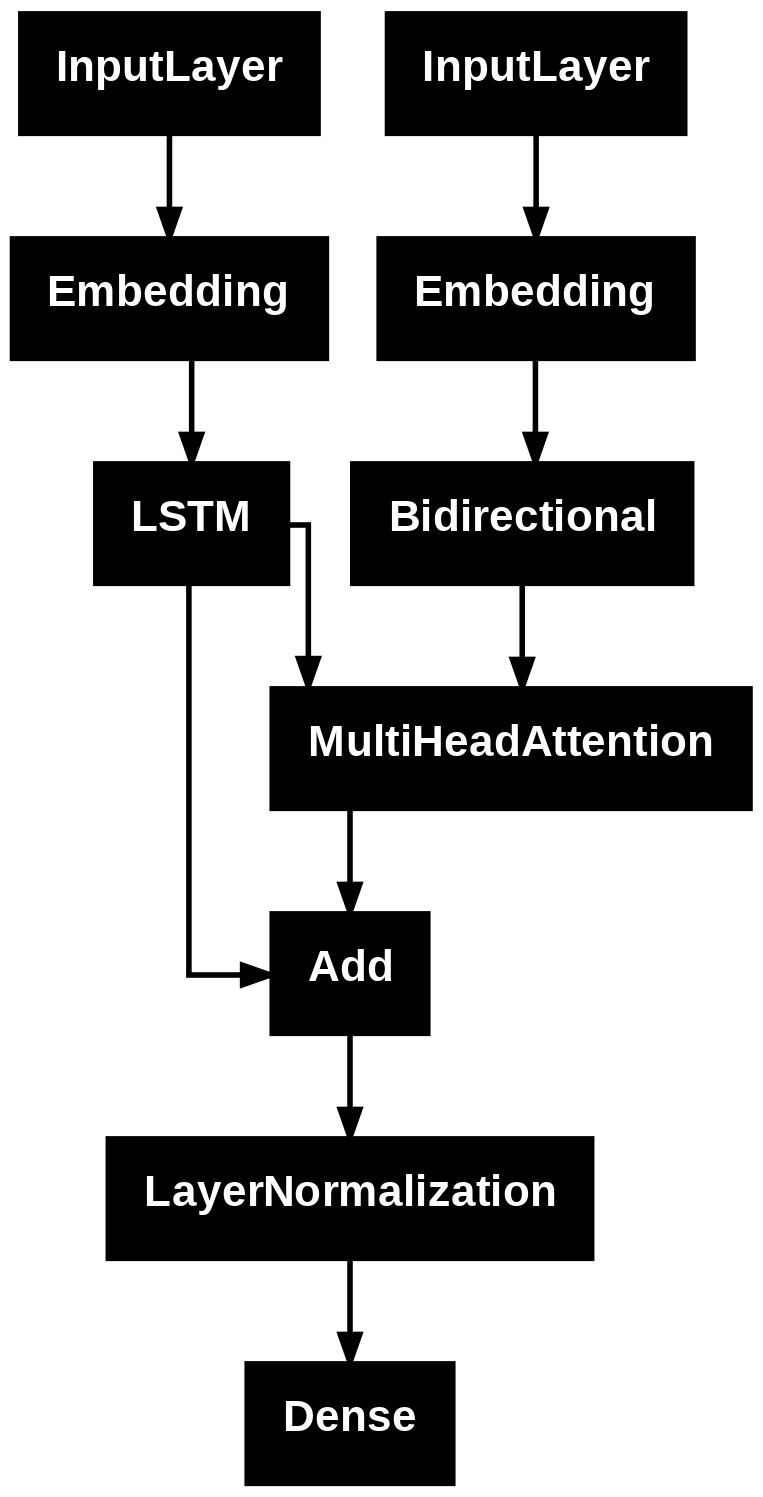

In [ ]:
from tensorflow.keras.utils import plot_model
plot_model(model_MHA)

In [ ]:
model_MHA.compile(loss='categorical_crossentropy',metrics=['acc'],optimizer='adam')

In [ ]:
history = model_MHA.fit([encoder_inp, decoder_inp],decoder_final_output,batch_size=BATCH_SIZE,
          epochs=EPOCHS,validation_split=0.1)

Output hidden; open in https://colab.research.google.com to view.

NameError: name 'history' is not defined

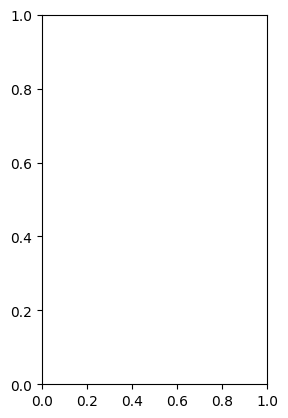

In [ ]:
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.ylim([0, max(plt.ylim())])
plt.xlabel('Epoch #')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['acc'], label='accuracy')
plt.plot(history.history['acc'], label='val_accuracy')
plt.ylim([0, max(plt.ylim())])
plt.xlabel('Epoch #')
plt.ylabel('Accuracy')
plt.legend()

In [ ]:
def pad_seq(seq, max_length=max_len, pad_token_id=0):
        if len(seq) > max_length:
            pad = seq[:max_length]
        else:
            pad = seq + [pad_token_id]*(max_length-len(seq))

        return pad

In [ ]:
import tensorflow as tf
def predict(text_dialogue, model=model_MHA, return_sent=False, print_gen=True):

    clean_txt = clean_text(text_dialogue)
    encoder_inp = []
    for word in clean_txt.split():
        if word not in vocab:
            encoder_inp.append(vocab['<OUT>'])
        else:
            encoder_inp.append(vocab[word])

    encoder_inp = pad_seq(encoder_inp, max_len)
    decoder_inp = np.zeros(max_len, dtype=np.int32)
    decoder_inp[0]= vocab['<SOS>']
    predict = -1
    output = []
    i = 0
    sentiment =''
    while predict!= vocab['<EOS>'] and i<max_len-1:
        softmax = tf.keras.layers.Softmax()
        test_predict = softmax(model.predict([np.expand_dims(encoder_inp, axis=0),
                                              np.expand_dims(decoder_inp, axis=0)], verbose=False))
        predict = np.argmax(test_predict[0][i])
        output += [predict]
        decoder_inp[i+1] = predict
        i +=1
        sentiment += ' '+ inv_vocab[predict]
    if print_gen:
        return sentiment
    if return_sent:
        return sent_id_en

In [ ]:
predict("Hannah: Hey, do you have Betty's number?\nAmanda: Lemme check\nHannah: <file_gif>\nAmanda: Sorry, can't find it.\nAmanda: Ask Larry\nAmanda: He called her last time we were at the park together\nHannah: I don't know him well\nHannah: <file_gif>\nAmanda: Don't be shy, he's very nice\nHannah: If you say so..\nHannah: I'd rather you texted him")

In [ ]:
pegus